# Knowledge Distillation & Hardware-Aware NAS for Edge Deployment
**Roll number: 22i-1948** — complete, self-contained Google Colab notebook for **Question 1** (knowledge distillation, CIFAR-100) and **Question 2** (hardware-aware neural architecture search, CIFAR-10).

Running this notebook **writes the whole GitHub repository** (`src/`, scripts, README, requirements), **trains every model**, exports **ONNX** models, runs **ONNX Runtime CPU inference**, **benchmarks** everything, generates the **technical report PDF** from the real results, and packages everything as **`22i-1948_<SECTION>.zip`**.

| # | Deliverable | Produced by |
|---|---|---|
| 1 | Teacher ResNet-50 checkpoint + training script | `src/q1_kd/train_teacher.py` → `checkpoints/q1/teacher/` |
| 2 | MobileNetV2, SqueezeNet, EfficientNet-Lite0 | `src/q1_kd/models/students.py` |
| 3 | Three baseline (no-KD) checkpoints | `src/q1_kd/train_baseline.py` → `checkpoints/q1/baseline/` |
| 4 | KD implementation, scripts, three distilled checkpoints | `src/q1_kd/kd.py`, `train_kd.py` → `checkpoints/q1/kd/` |
| 5 | NAS search space + architecture generator | `src/q2_nas/search_space.py`, `generator.py` |
| 6 | Executable Optuna (Bayesian TPE) search | `src/q2_nas/search.py`, `hardware.py` |
| 7 | Best architecture + search history (CSV/JSON) | `results/q2/` |
| 8 | Trained checkpoint of the best architecture | `src/q2_nas/train_best.py` → `checkpoints/q2/nas_best.pt` |
| 9 | Inference scripts for all students + NAS model | `src/deploy/inference.py` |
| 10 | ONNX models + CPU inference scripts | `src/deploy/export_onnx.py`, `onnx_inference.py` → `onnx_models/` |
| 11 | Automated benchmarking + CSV results | `src/deploy/benchmark.py` → `results/*.csv` |
| 12 | Technical report (PDF) with screenshots | `src/report/` → `report/` |
| 13 | README | `README.md`, `requirements.txt` |

### How to run
1. **Runtime → Change runtime type → T4 GPU** (any CUDA GPU works).
2. Set `SECTION` (and optionally `MODE`, `USE_DRIVE`) in the next cell.
3. **Runtime → Run all.** If Colab disconnects, simply *Run all* again: finished stages are skipped and the running stage resumes from its last epoch (when `USE_DRIVE=True`).

| MODE | What it does | Time on a T4 |
|---|---|---|
| `FULL` | the real experiment (values used in the report) | ≈ 2.5–3.5 h |
| `QUICK` | real data, very short schedules – check that everything runs | ≈ 30–40 min |
| `SMOKE` | synthetic data, 1–2 epochs – functional test, also works on CPU | ≈ 5–10 min |

## 0. Configuration

In [4]:
ROLL_NO   = "22i-1948"
SECTION   = "A"        # <-- set your section letter here (used for the folder, zip and report names)
MODE      = "FULL"     # "FULL" | "QUICK" | "SMOKE"
USE_DRIVE = True       # save everything to Google Drive -> survives disconnects, auto-resume

# ---------------------------------------------------------------- hyper-parameters per mode
HP = {
    "FULL": {
        "teacher":    {"epochs": 30, "lr": 0.05, "batch_size": 128, "wd": 5e-4},
        "baseline":   {"epochs": 30, "lr": 0.1,  "batch_size": 128, "wd": 5e-4},
        "kd":         {"epochs": 30, "lr": 0.1,  "batch_size": 128, "wd": 5e-4,
                       "temperature": 4.0, "alpha": 0.9, "beta": 1.0, "feat_loss": "fitnet"},
        "nas_search": {"n_trials": 30, "max_total_trials": 150, "trial_epochs": 10, "train_subset": 20000,
                       "max_latency_ms": 5.0, "max_size_mb": 1.0, "max_peak_mem_mb": 6.0, "threads": 1},
        "nas_best":   {"epochs": 60, "lr": 0.1, "batch_size": 128},
        "benchmark":  {"threads": 1, "runs": 100},
    },
    "QUICK": {
        "teacher":    {"epochs": 4, "lr": 0.05, "batch_size": 128, "wd": 5e-4},
        "baseline":   {"epochs": 4, "lr": 0.1,  "batch_size": 128, "wd": 5e-4},
        "kd":         {"epochs": 4, "lr": 0.1,  "batch_size": 128, "wd": 5e-4,
                       "temperature": 4.0, "alpha": 0.9, "beta": 1.0, "feat_loss": "fitnet"},
        "nas_search": {"n_trials": 6, "max_total_trials": 40, "trial_epochs": 3, "train_subset": 10000,
                       "max_latency_ms": 5.0, "max_size_mb": 1.0, "max_peak_mem_mb": 6.0, "threads": 1},
        "nas_best":   {"epochs": 8, "lr": 0.1, "batch_size": 128},
        "benchmark":  {"threads": 1, "runs": 50},
    },
    "SMOKE": {
        "teacher":    {"epochs": 1, "lr": 0.05, "batch_size": 64, "wd": 5e-4},
        "baseline":   {"epochs": 1, "lr": 0.1,  "batch_size": 64, "wd": 5e-4},
        "kd":         {"epochs": 1, "lr": 0.1,  "batch_size": 64, "wd": 5e-4,
                       "temperature": 4.0, "alpha": 0.9, "beta": 1.0, "feat_loss": "fitnet"},
        "nas_search": {"n_trials": 3, "max_total_trials": 20, "trial_epochs": 2, "train_subset": 1000,
                       "max_latency_ms": 5.0, "max_size_mb": 1.0, "max_peak_mem_mb": 6.0, "threads": 1},
        "nas_best":   {"epochs": 1, "lr": 0.1, "batch_size": 64},
        "benchmark":  {"threads": 1, "runs": 20},
    },
}[MODE]
SMOKE_FLAG = "--smoke" if MODE == "SMOKE" else ""
print(f"{ROLL_NO}_{SECTION} | MODE={MODE}")

22i-1948_A | MODE=FULL


## 1. Install dependencies & check the GPU
PyTorch, torchvision, NumPy, pandas and matplotlib are pre-installed on Colab; the cell below adds ONNX, ONNX Runtime, Optuna and ReportLab.

In [5]:
%pip install -q onnx onnxruntime onnxscript optuna reportlab psutil
import torch, torchvision, platform, subprocess
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| python", platform.python_version())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found. Use Runtime > Change runtime type > T4 GPU (FULL mode is not practical on CPU).")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | python 3.13.16
GPU: Tesla T4


## 2. Create the project folder
With `USE_DRIVE=True` the repository lives in Google Drive (`MyDrive/22i-1948_<SECTION>`). Datasets are downloaded to the fast local disk.

In [6]:
import os, sys, json, pathlib
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_NAME = f"{ROLL_NO}_{SECTION}" + ("" if MODE == "FULL" else f"_{MODE.lower()}")
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive"
elif IN_COLAB:
    BASE = "/content"
else:
    BASE = os.path.abspath("colab_runs")
PROJECT_ROOT = os.path.join(BASE, PROJECT_NAME)
DATA_DIR = "/content/data" if IN_COLAB else os.path.join(BASE, "data")

for d in ["src/common", "src/q1_kd/models", "src/q2_nas", "src/deploy", "src/report", "notebooks",
          "checkpoints", "results", "onnx_models", "logs", "report", "screenshots", "samples"]:
    os.makedirs(os.path.join(PROJECT_ROOT, d), exist_ok=True)
for pkg in ["src", "src/common", "src/q1_kd", "src/q1_kd/models", "src/q2_nas", "src/deploy", "src/report"]:
    pathlib.Path(PROJECT_ROOT, pkg, "__init__.py").touch()
os.makedirs(DATA_DIR, exist_ok=True)
os.chdir(PROJECT_ROOT)
os.environ["PROJECT_ROOT"] = PROJECT_ROOT
os.environ["DATA_DIR"] = DATA_DIR
os.environ["PYTHONUNBUFFERED"] = "1"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
print("project:", PROJECT_ROOT, "\ndata   :", DATA_DIR)

Mounted at /content/drive
project: /content/drive/MyDrive/22i-1948_A 
data   : /content/data


## 3. Source code of the repository
Each cell below writes one file of the repository with `%%writefile`. Every script is also runnable on its own from the command line (see README).

### 3.1 Common utilities — data pipeline, training engine, hardware profiling

In [7]:
%%writefile src/common/utils.py
"""Shared helpers: seeding, device, logging, checkpoint I/O, metrics, CSV/JSON."""
import csv
import io
import json
import os
import random
import sys
import time
from pathlib import Path

import numpy as np
import torch

PROJECT_ROOT = Path(os.environ.get("PROJECT_ROOT", os.getcwd())).resolve()
CKPT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results"
ONNX_DIR = PROJECT_ROOT / "onnx_models"
LOG_DIR = PROJECT_ROOT / "logs"
DATA_DIR = Path(os.environ.get("DATA_DIR", PROJECT_ROOT / "data")).resolve()


def ensure_dirs():
    for d in (CKPT_DIR, RESULTS_DIR, ONNX_DIR, LOG_DIR, DATA_DIR):
        d.mkdir(parents=True, exist_ok=True)


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device():
    if torch.cuda.is_available():
        torch.backends.cudnn.benchmark = True
        return torch.device("cuda")
    return torch.device("cpu")


class Tee:
    """Duplicate stdout/stderr into a log file (logs are reused as report screenshots)."""

    def __init__(self, path):
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        self.file = open(path, "a", buffering=1)
        self.stdout = sys.stdout

    def write(self, msg):
        self.stdout.write(msg)
        self.file.write(msg)

    def flush(self):
        self.stdout.flush()
        self.file.flush()

    def isatty(self):
        return False


def setup_logging(name: str):
    ensure_dirs()
    tee = Tee(LOG_DIR / f"{name}.log")
    sys.stdout = tee
    print(f"\n===== {name} | {time.strftime('%Y-%m-%d %H:%M:%S')} =====")
    return tee


class AverageMeter:
    def __init__(self):
        self.sum, self.count = 0.0, 0

    def update(self, val, n=1):
        self.sum += float(val) * n
        self.count += n

    @property
    def avg(self):
        return self.sum / max(self.count, 1)


@torch.no_grad()
def topk_correct(logits, target, ks=(1, 5)):
    maxk = min(max(ks), logits.size(1))
    _, pred = logits.topk(maxk, dim=1)
    correct = pred.eq(target.view(-1, 1))
    return [correct[:, : min(k, maxk)].any(dim=1).sum().item() for k in ks]


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def state_dict_size_mb(model):
    """Storage size of the serialized fp32 weights (what is actually written to disk)."""
    buf = io.BytesIO()
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, buf)
    return buf.getbuffer().nbytes / (1024 ** 2)


def save_checkpoint(path, model, meta: dict):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    sd = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    torch.save({"state_dict": sd, "meta": meta}, path)


def load_checkpoint(path, map_location="cpu"):
    return torch.load(path, map_location=map_location, weights_only=False)


def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))


def load_json(path):
    with open(path) as f:
        return json.load(f)


def write_csv(rows, path):
    """Write a list of dicts to CSV (union of keys, stable order)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    keys = []
    for r in rows:
        for k in r:
            if k not in keys:
                keys.append(k)
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        for r in rows:
            w.writerow(r)


def upsert_csv_row(row: dict, path, key: str):
    """Insert or replace a row (matched on `key`) in a CSV file."""
    path = Path(path)
    rows = []
    if path.exists():
        with open(path) as f:
            rows = list(csv.DictReader(f))
    rows = [r for r in rows if r.get(key) != str(row[key])]
    rows.append(row)
    write_csv(rows, path)


def fmt_time(sec):
    m, s = divmod(int(sec), 60)
    h, m = divmod(m, 60)
    return f"{h:d}h{m:02d}m{s:02d}s" if h else f"{m:d}m{s:02d}s"

Writing src/common/utils.py


In [8]:
%%writefile src/common/data.py
"""CIFAR-10 / CIFAR-100 loading and a fast on-device batch loader.

The whole dataset is held as uint8 on the training device; random-crop (pad 4),
horizontal flip, normalisation and optional resizing are done batch-wise on the
GPU. This removes the CPU data-loading bottleneck on Colab (2 vCPUs) and makes
both KD and NAS training several times faster than a torchvision DataLoader.
"""
import math

import numpy as np
import torch
import torch.nn.functional as F

from .utils import DATA_DIR

STATS = {
    "cifar10": ((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
    "cifar100": ((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)),
}

CIFAR10_CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
                   "dog", "frog", "horse", "ship", "truck"]


def load_cifar(name="cifar100", root=None, smoke=False):
    """Return dict with uint8 NHWC arrays x_train/x_test, int64 y_train/y_test, classes."""
    name = name.lower()
    num_classes = 100 if name == "cifar100" else 10
    if smoke:  # synthetic data for a fast end-to-end functional test
        rng = np.random.default_rng(0)
        classes = CIFAR10_CLASSES if num_classes == 10 else [f"class_{i}" for i in range(100)]
        return dict(x_train=rng.integers(0, 256, (640, 32, 32, 3), dtype=np.uint8),
                    y_train=rng.integers(0, num_classes, 640).astype(np.int64),
                    x_test=rng.integers(0, 256, (256, 32, 32, 3), dtype=np.uint8),
                    y_test=rng.integers(0, num_classes, 256).astype(np.int64),
                    classes=classes, num_classes=num_classes, name=name)
    import torchvision
    root = str(root or DATA_DIR)
    cls = torchvision.datasets.CIFAR100 if name == "cifar100" else torchvision.datasets.CIFAR10
    tr = cls(root=root, train=True, download=True)
    te = cls(root=root, train=False, download=True)
    return dict(x_train=tr.data, y_train=np.array(tr.targets, dtype=np.int64),
                x_test=te.data, y_test=np.array(te.targets, dtype=np.int64),
                classes=list(tr.classes), num_classes=num_classes, name=name)


def train_val_split(x, y, n_val, seed=0):
    """Stratified hold-out split (used by NAS so that search never sees the test set)."""
    rng = np.random.default_rng(seed)
    classes = np.unique(y)
    per_class = max(1, n_val // len(classes))
    val_idx = np.concatenate([rng.permutation(np.where(y == c)[0])[:per_class] for c in classes])
    mask = np.ones(len(y), dtype=bool)
    mask[val_idx] = False
    return x[mask], y[mask], x[val_idx], y[val_idx]


class DeviceLoader:
    """Iterable over (images, labels) batches produced entirely on `device`."""

    def __init__(self, x, y, batch_size, device, dataset="cifar100", train=True,
                 resolution=32, drop_last=None, channels_last=True, seed=0):
        self.x = torch.as_tensor(x).permute(0, 3, 1, 2).contiguous().to(device)  # uint8 NCHW
        self.y = torch.as_tensor(y, dtype=torch.long).to(device)
        self.bs, self.device, self.train = batch_size, device, train
        self.resolution = resolution
        self.drop_last = train if drop_last is None else drop_last
        self.channels_last = channels_last and device.type == "cuda"
        mean, std = STATS[dataset]
        self.mean = torch.tensor(mean, device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(std, device=device).view(1, 3, 1, 1)
        self.gen = torch.Generator(device=device)
        self.gen.manual_seed(seed)

    def __len__(self):
        n = len(self.y)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def _augment(self, xb):
        b, _, h, w = xb.shape
        pad = 4
        xp = F.pad(xb, (pad, pad, pad, pad))  # zero padding (standard CIFAR augmentation)
        oy = torch.randint(0, 2 * pad + 1, (b,), device=xb.device, generator=self.gen)
        ox = torch.randint(0, 2 * pad + 1, (b,), device=xb.device, generator=self.gen)
        ar_h = torch.arange(h, device=xb.device)
        ar_w = torch.arange(w, device=xb.device)
        rows = (oy[:, None] + ar_h)[:, None, :, None].expand(b, 3, h, w)
        cols = (ox[:, None] + ar_w)[:, None, None, :].expand(b, 3, h, w)
        out = xp[torch.arange(b, device=xb.device)[:, None, None, None],
                 torch.arange(3, device=xb.device)[None, :, None, None], rows, cols]
        flip = torch.rand(b, device=xb.device, generator=self.gen) < 0.5
        out = torch.where(flip[:, None, None, None], out.flip(3), out)
        return out

    def preprocess(self, xb_uint8):
        xb = xb_uint8.float().div_(255.0)
        if self.train:
            xb = self._augment(xb)
        xb = (xb - self.mean) / self.std
        if self.resolution != xb.shape[-1]:
            xb = F.interpolate(xb, size=(self.resolution, self.resolution), mode="bilinear",
                               align_corners=False, antialias=self.resolution < xb.shape[-1])
        if self.channels_last:
            xb = xb.contiguous(memory_format=torch.channels_last)
        return xb

    def __iter__(self):
        n = len(self.y)
        idx = (torch.randperm(n, device=self.device, generator=self.gen) if self.train
               else torch.arange(n, device=self.device))
        for i in range(len(self)):
            bi = idx[i * self.bs:(i + 1) * self.bs]
            yield self.preprocess(self.x[bi]), self.y[bi]


def preprocess_numpy(images_uint8_nhwc, dataset, resolution=32):
    """CPU preprocessing used by inference / ONNX pipelines: uint8 NHWC -> float32 NCHW."""
    x = torch.as_tensor(np.ascontiguousarray(images_uint8_nhwc)).permute(0, 3, 1, 2).float() / 255.0
    mean, std = STATS[dataset]
    x = (x - torch.tensor(mean).view(1, 3, 1, 1)) / torch.tensor(std).view(1, 3, 1, 1)
    if resolution != x.shape[-1]:
        x = F.interpolate(x, size=(resolution, resolution), mode="bilinear",
                          align_corners=False, antialias=resolution < x.shape[-1])
    return x.contiguous()

Writing src/common/data.py


In [9]:
%%writefile src/common/trainer.py
"""Generic training / evaluation engine (AMP, cosine LR with warm-up, resumable)."""
import math
import time
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

from .utils import AverageMeter, fmt_time, topk_correct, write_csv


@torch.no_grad()
def evaluate(model, loader, device, amp=True):
    model.eval()
    loss_m, n, c1, c5 = AverageMeter(), 0, 0, 0
    for x, y in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16,
                            enabled=amp and device.type == "cuda"):
            logits = model(x)
        loss_m.update(F.cross_entropy(logits.float(), y).item(), y.size(0))
        a, b = topk_correct(logits, y, (1, 5))
        c1, c5, n = c1 + a, c5 + b, n + y.size(0)
    return {"loss": loss_m.avg, "top1": 100.0 * c1 / max(n, 1), "top5": 100.0 * c5 / max(n, 1)}


def build_optimizer(params, lr, wd, momentum=0.9):
    """SGD-Nesterov; no weight decay on BatchNorm / bias parameters."""
    decay, no_decay = [], []
    for p in params:
        if not p.requires_grad:
            continue
        (no_decay if p.ndim <= 1 else decay).append(p)
    return torch.optim.SGD([{"params": decay, "weight_decay": wd},
                            {"params": no_decay, "weight_decay": 0.0}],
                           lr=lr, momentum=momentum, nesterov=True)


def cosine_with_warmup(optimizer, total_steps, warmup_steps):
    def fn(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)


def ce_criterion(label_smoothing=0.0):
    def fn(model, x, y):
        logits = model(x)
        loss = F.cross_entropy(logits.float(), y, label_smoothing=label_smoothing)
        return loss, logits, {"ce": loss.item()}
    return fn


def fit(model, train_loader, val_loader, device, *, epochs, lr, wd, criterion,
        trainable: nn.Module = None, eval_model: nn.Module = None, warmup_epochs=1,
        amp=True, run_name="run", resume_path=None, history_csv=None,
        report_fn=None, log_every_epoch=True, grad_clip=None):
    """Train `trainable` (defaults to `model`) using `criterion(trainable, x, y)`.

    criterion returns (loss, logits, dict_of_scalar_parts). `eval_model` is the network
    evaluated on `val_loader` (the student when trainable is a KD wrapper).
    `report_fn(epoch, val_top1)` may raise (e.g. optuna.TrialPruned).
    Returns (history list, best metrics dict, best_state_dict).
    """
    trainable = trainable or model
    eval_model = eval_model or model
    use_amp = amp and device.type == "cuda"
    opt = build_optimizer(trainable.parameters(), lr, wd)
    steps = epochs * len(train_loader)
    sched = cosine_with_warmup(opt, steps, warmup_epochs * len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    start_epoch, history, best = 0, [], {"top1": -1.0}
    best_state = None

    if resume_path and Path(resume_path).exists():
        ck = torch.load(resume_path, map_location=device, weights_only=False)
        trainable.load_state_dict(ck["trainable"])
        opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"])
        start_epoch, history, best = ck["epoch"], ck["history"], ck["best"]
        best_state = ck.get("best_state")
        print(f"[{run_name}] resumed from epoch {start_epoch}/{epochs}")

    t0 = time.time()
    for epoch in range(start_epoch, epochs):
        trainable.train()
        te = time.time()
        meters, loss_m, c1, n = {}, AverageMeter(), 0, 0
        for x, y in train_loader:
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                loss, logits, parts = criterion(trainable, x, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if grad_clip:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(trainable.parameters(), grad_clip)
            scaler.step(opt)
            scaler.update()
            sched.step()
            bs = y.size(0)
            loss_m.update(loss.item(), bs)
            for k, v in parts.items():
                meters.setdefault(k, AverageMeter()).update(v, bs)
            c1 += topk_correct(logits.detach(), y, (1,))[0]
            n += bs
        val = evaluate(eval_model, val_loader, device, amp)
        rec = {"epoch": epoch + 1, "lr": opt.param_groups[0]["lr"], "train_loss": loss_m.avg,
               "train_top1": 100.0 * c1 / max(n, 1),
               **{f"train_{k}": m.avg for k, m in meters.items()},
               "val_loss": val["loss"], "val_top1": val["top1"], "val_top5": val["top5"],
               "epoch_time_s": time.time() - te}
        history.append(rec)
        if val["top1"] > best["top1"]:
            best = {"epoch": epoch + 1, **val}
            best_state = {k: v.detach().cpu().clone() for k, v in eval_model.state_dict().items()}
        if log_every_epoch:
            parts_s = " ".join(f"{k}={m.avg:.3f}" for k, m in meters.items())
            print(f"[{run_name}] ep {epoch + 1:3d}/{epochs} loss={loss_m.avg:.4f} {parts_s} "
                  f"train@1={rec['train_top1']:.2f} val@1={val['top1']:.2f} val@5={val['top5']:.2f} "
                  f"({rec['epoch_time_s']:.1f}s, total {fmt_time(time.time() - t0)})", flush=True)
        if history_csv:
            write_csv(history, history_csv)
        if resume_path:
            Path(resume_path).parent.mkdir(parents=True, exist_ok=True)
            tmp = Path(str(resume_path) + ".tmp")
            torch.save({"trainable": trainable.state_dict(), "opt": opt.state_dict(),
                        "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                        "epoch": epoch + 1, "history": history, "best": best,
                        "best_state": best_state}, tmp)
            tmp.replace(resume_path)  # atomic: a Colab disconnect never leaves a corrupt file
        if report_fn is not None:
            report_fn(epoch, val["top1"])
    return history, best, best_state

Writing src/common/trainer.py


In [10]:
%%writefile src/common/profiling.py
"""Hardware measurements: CPU latency (PyTorch & ONNX Runtime), storage size,
peak inference memory, FLOPs. Used by both the NAS hardware-aware search and the
benchmarking scripts."""
import copy
import gc
import os
import statistics
import time

import numpy as np
import torch

from .utils import count_params, state_dict_size_mb


def _stats(times_ms):
    t = sorted(times_ms)
    return {"mean_ms": statistics.fmean(t), "median_ms": statistics.median(t),
            "p90_ms": t[int(0.9 * (len(t) - 1))], "std_ms": statistics.pstdev(t),
            "min_ms": t[0]}


@torch.inference_mode()
def torch_cpu_latency(model, input_shape=(1, 3, 32, 32), warmup=10, runs=50, threads=1):
    """Measured wall-clock CPU latency of a PyTorch model (eval mode, fp32)."""
    prev = torch.get_num_threads()
    torch.set_num_threads(threads)
    m = copy.deepcopy(model).cpu().eval()
    x = torch.randn(*input_shape)
    for _ in range(warmup):
        m(x)
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        m(x)
        times.append((time.perf_counter() - t0) * 1e3)
    torch.set_num_threads(prev)
    del m
    return _stats(times)


def ort_session(onnx_path, threads=1):
    import onnxruntime as ort
    so = ort.SessionOptions()
    so.intra_op_num_threads = threads
    so.inter_op_num_threads = 1
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(str(onnx_path), sess_options=so, providers=["CPUExecutionProvider"])


def ort_cpu_latency(onnx_path_or_session, input_shape=(1, 3, 32, 32), warmup=10, runs=100, threads=1):
    sess = (onnx_path_or_session if not isinstance(onnx_path_or_session, (str, os.PathLike))
            else ort_session(onnx_path_or_session, threads))
    name = sess.get_inputs()[0].name
    x = np.random.randn(*input_shape).astype(np.float32)
    for _ in range(warmup):
        sess.run(None, {name: x})
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        sess.run(None, {name: x})
        times.append((time.perf_counter() - t0) * 1e3)
    return _stats(times)


@torch.inference_mode()
def peak_inference_memory_mb(model, input_shape=(1, 3, 32, 32)):
    """Peak CPU memory allocated by the PyTorch allocator during one forward pass.

    Uses torch.profiler memory events (allocations +, frees -) replayed in time
    order; the running maximum is the peak activation + workspace memory. The
    weights are counted separately (they are resident before the pass starts),
    so peak_total = weights + peak_activations. Returns None when unsupported.
    """
    try:
        from torch.profiler import ProfilerActivity, profile
        m = copy.deepcopy(model).cpu().eval()
        x = torch.randn(*input_shape)
        m(x)  # warm-up (lazy init)
        with profile(activities=[ProfilerActivity.CPU], profile_memory=True) as prof:
            m(x)
        # leaf events only (allocating ops such as aten::empty and '[memory]' free events),
        # so an allocation is not counted again by its parent op
        events = [(e.time_range.start, e.cpu_memory_usage) for e in prof.events()
                  if len(e.cpu_children) == 0 and (e.cpu_memory_usage or 0) != 0]
        events.sort(key=lambda t: t[0])
        cur = peak = 0
        for _, mem in events:
            cur += mem
            peak = max(peak, cur)
        weights_mb = sum(p.numel() * p.element_size() for p in m.state_dict().values()) / 2 ** 20
        del m
        gc.collect()
        return {"peak_activation_mb": peak / 2 ** 20, "weights_mb": weights_mb,
                "peak_total_mb": peak / 2 ** 20 + weights_mb}
    except Exception as ex:  # pragma: no cover - depends on build
        print(f"[profiling] peak memory not supported: {ex}")
        return None


def gpu_peak_memory_mb(model, input_shape=(1, 3, 32, 32)):
    if not torch.cuda.is_available():
        return None
    m = copy.deepcopy(model).cuda().eval()
    x = torch.randn(*input_shape, device="cuda")
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    base = torch.cuda.memory_allocated()
    with torch.inference_mode():
        m(x)
    torch.cuda.synchronize()
    peak = (torch.cuda.max_memory_allocated() - base) / 2 ** 20
    del m
    torch.cuda.empty_cache()
    return peak


def count_flops(model, input_shape=(1, 3, 32, 32)):
    """FLOPs of one forward pass (torch.utils.flop_counter; 1 MAC = 2 FLOPs)."""
    try:
        from torch.utils.flop_counter import FlopCounterMode
        m = copy.deepcopy(model).cpu().eval()
        with FlopCounterMode(display=False) as fc, torch.inference_mode():
            m(torch.randn(*input_shape))
        return int(fc.get_total_flops())
    except Exception as ex:  # pragma: no cover
        print(f"[profiling] flop counting failed: {ex}")
        return None


def profile_model(model, input_shape=(1, 3, 32, 32), threads=1, warmup=10, runs=50, memory=True):
    """Full hardware profile used by NAS and benchmarking."""
    lat = torch_cpu_latency(model, input_shape, warmup, runs, threads)
    out = {"params": count_params(model), "size_mb": state_dict_size_mb(model),
           "flops": count_flops(model, input_shape),
           "cpu_latency_ms": lat["median_ms"], "cpu_latency_mean_ms": lat["mean_ms"],
           "cpu_latency_p90_ms": lat["p90_ms"]}
    if memory:
        mem = peak_inference_memory_mb(model, input_shape)
        out["peak_mem_mb"] = mem["peak_total_mb"] if mem else None
        out["peak_act_mem_mb"] = mem["peak_activation_mb"] if mem else None
    return out

Writing src/common/profiling.py


### 3.2 Question 1 — teacher, students, knowledge-distillation framework, training scripts

In [11]:
%%writefile src/q1_kd/models/teacher.py
"""ResNet-50 teacher adapted to 32x32 CIFAR images.

The ImageNet stem (7x7 stride-2 conv + max-pool) would shrink a 32x32 image to
8x8 before the first residual stage, so it is replaced by a 3x3 stride-1 conv and
the max-pool is removed (standard CIFAR adaptation). Spatial sizes:
32 (layer1) -> 16 (layer2) -> 8 (layer3) -> 4 (layer4).
Optionally initialised from ImageNet weights (the new 3x3 stem is initialised from
the centre of the pretrained 7x7 kernels), then fully trained on CIFAR-100.
"""
import torch
import torch.nn as nn
import torchvision


class ResNet50Teacher(nn.Module):
    # channels of the intermediate representations used for feature distillation
    feature_channels = {"mid": 1024, "final": 2048}

    def __init__(self, num_classes=100, pretrained=True):
        super().__init__()
        weights = None
        if pretrained:
            try:
                weights = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
            except Exception:
                weights = None
        try:
            net = torchvision.models.resnet50(weights=weights)
        except Exception as ex:  # no internet -> random init
            print(f"[teacher] could not load ImageNet weights ({ex}); training from scratch")
            net = torchvision.models.resnet50(weights=None)
            weights = None
        old_conv = net.conv1
        net.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
        if weights is not None:
            with torch.no_grad():
                net.conv1.weight.copy_(old_conv.weight[:, :, 2:5, 2:5] * (49.0 / 9.0) ** 0.5)
        net.maxpool = nn.Identity()
        net.fc = nn.Linear(2048, num_classes)
        self.pretrained = weights is not None
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu)
        self.layer1, self.layer2, self.layer3, self.layer4 = net.layer1, net.layer2, net.layer3, net.layer4
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = net.fc

    def forward(self, x, return_features=False):
        x = self.stem(x)
        x = self.layer2(self.layer1(x))
        mid = self.layer3(x)          # 1024 x 8 x 8
        final = self.layer4(mid)      # 2048 x 4 x 4
        logits = self.fc(torch.flatten(self.pool(final), 1))
        if return_features:
            return logits, {"mid": mid, "final": final}
        return logits


def build_teacher(num_classes=100, pretrained=True):
    return ResNet50Teacher(num_classes, pretrained)

Writing src/q1_kd/models/teacher.py


In [12]:
%%writefile src/q1_kd/models/students.py
"""Lightweight student networks, implemented from scratch and adapted to 32x32 inputs.

Every student exposes the same interface as the teacher:
    logits = model(x)
    logits, feats = model(x, return_features=True)   # feats = {"mid": 8x8 map, "final": 4x4 map}
and a `feature_channels` dict, which the feature-distillation module uses to build
1x1 regressors into the teacher's feature space.

CIFAR adaptation: the first strides are reduced so the total stride is 8
(32 -> 4), matching the teacher's layer3 (8x8) and layer4 (4x4) resolutions.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


def _make_divisible(v, divisor=8, min_value=None):
    min_value = min_value or divisor
    new_v = max(min_value, int(v + divisor / 2) // divisor * divisor)
    if new_v < 0.9 * v:
        new_v += divisor
    return new_v


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, s=1, groups=1, act=nn.ReLU6):
        layers = [nn.Conv2d(cin, cout, k, s, k // 2, groups=groups, bias=False), nn.BatchNorm2d(cout)]
        if act is not None:
            layers.append(act(inplace=True))
        super().__init__(*layers)


class DropPath(nn.Module):
    """Stochastic depth (used by EfficientNet-Lite)."""

    def __init__(self, p=0.0):
        super().__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0.0:
            return x
        keep = 1.0 - self.p
        mask = x.new_empty(x.shape[0], 1, 1, 1).bernoulli_(keep)
        return x * mask / keep


class InvertedResidual(nn.Module):
    """MobileNetV2 / MBConv block: 1x1 expand -> kxk depthwise -> 1x1 linear projection."""

    def __init__(self, cin, cout, stride, expand, kernel=3, act=nn.ReLU6, drop_path=0.0):
        super().__init__()
        hidden = int(round(cin * expand))
        self.use_res = stride == 1 and cin == cout
        layers = []
        if expand != 1:
            layers.append(ConvBNAct(cin, hidden, 1, act=act))
        layers += [ConvBNAct(hidden, hidden, kernel, stride, groups=hidden, act=act),
                   nn.Conv2d(hidden, cout, 1, bias=False), nn.BatchNorm2d(cout)]
        self.block = nn.Sequential(*layers)
        self.drop_path = DropPath(drop_path) if self.use_res else nn.Identity()

    def forward(self, x):
        out = self.block(x)
        return x + self.drop_path(out) if self.use_res else out


# --------------------------------------------------------------------------- MobileNetV2
class MobileNetV2(nn.Module):
    """MobileNetV2 (Sandler et al., 2018). CIFAR strides: stem 1, stages (1,1,2,2,1,2,1)."""

    # t (expansion), c (channels), n (repeats), s (stride)
    CFG = [(1, 16, 1, 1), (6, 24, 2, 1), (6, 32, 3, 2), (6, 64, 4, 2),
           (6, 96, 3, 1), (6, 160, 3, 2), (6, 320, 1, 1)]

    def __init__(self, num_classes=100, width_mult=1.0, dropout=0.2):
        super().__init__()
        cin = _make_divisible(32 * width_mult)
        self.last_channels = _make_divisible(1280 * max(1.0, width_mult))
        self.stem = ConvBNAct(3, cin, 3, 1)
        stages = []
        for t, c, n, s in self.CFG:
            cout = _make_divisible(c * width_mult)
            blocks = []
            for i in range(n):
                blocks.append(InvertedResidual(cin, cout, s if i == 0 else 1, t))
                cin = cout
            stages.append(nn.Sequential(*blocks))
        self.stages_a = nn.Sequential(*stages[:5])   # -> 96 x 8 x 8  ("mid")
        self.stages_b = nn.Sequential(*stages[5:])   # -> 320 x 4 x 4
        self.head = ConvBNAct(cin, self.last_channels, 1)  # -> 1280 x 4 x 4 ("final")
        self.feature_channels = {"mid": _make_divisible(96 * width_mult), "final": self.last_channels}
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(self.last_channels, num_classes))
        _init_weights(self)

    def forward(self, x, return_features=False):
        mid = self.stages_a(self.stem(x))
        final = self.head(self.stages_b(mid))
        logits = self.classifier(torch.flatten(F.adaptive_avg_pool2d(final, 1), 1))
        return (logits, {"mid": mid, "final": final}) if return_features else logits


# --------------------------------------------------------------------------- SqueezeNet
class Fire(nn.Module):
    def __init__(self, cin, squeeze, e1, e3):
        super().__init__()
        self.squeeze = nn.Sequential(nn.Conv2d(cin, squeeze, 1, bias=False), nn.BatchNorm2d(squeeze), nn.ReLU(inplace=True))
        self.e1 = nn.Sequential(nn.Conv2d(squeeze, e1, 1, bias=False), nn.BatchNorm2d(e1), nn.ReLU(inplace=True))
        self.e3 = nn.Sequential(nn.Conv2d(squeeze, e3, 3, padding=1, bias=False), nn.BatchNorm2d(e3), nn.ReLU(inplace=True))

    def forward(self, x):
        s = self.squeeze(x)
        return torch.cat([self.e1(s), self.e3(s)], 1)


class SqueezeNet(nn.Module):
    """SqueezeNet v1.1 (Iandola et al., 2016) with BatchNorm, 3x3 stride-1 stem and
    max-pools placed at 32->16->8->4. Fire modules squeeze with 1x1 convs then expand
    with parallel 1x1 / 3x3 convs; the classifier is a 1x1 conv + global average pool."""

    def __init__(self, num_classes=100, dropout=0.3):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.stage1 = nn.Sequential(nn.MaxPool2d(2), Fire(64, 16, 64, 64), Fire(128, 16, 64, 64))           # 16x16
        self.stage2 = nn.Sequential(nn.MaxPool2d(2), Fire(128, 32, 128, 128), Fire(256, 32, 128, 128))     # 8x8 mid
        self.stage3 = nn.Sequential(nn.MaxPool2d(2), Fire(256, 48, 192, 192), Fire(384, 48, 192, 192),
                                    Fire(384, 64, 256, 256), Fire(512, 64, 256, 256))                       # 4x4 final
        self.feature_channels = {"mid": 256, "final": 512}
        # final ReLU of the original classifier is removed so logits can be negative (needed for KD)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Conv2d(512, num_classes, 1))
        _init_weights(self)
        nn.init.normal_(self.classifier[1].weight, 0, 0.01)

    def forward(self, x, return_features=False):
        mid = self.stage2(self.stage1(self.stem(x)))
        final = self.stage3(mid)
        logits = torch.flatten(F.adaptive_avg_pool2d(self.classifier(final), 1), 1)
        return (logits, {"mid": mid, "final": final}) if return_features else logits


# --------------------------------------------------------------------------- EfficientNet-Lite0
class EfficientNetLite0(nn.Module):
    """EfficientNet-Lite0 (Tan & Le, 2019; TF Lite variant): EfficientNet-B0 MBConv
    layout with the edge-friendly changes — no squeeze-and-excitation, ReLU6
    instead of Swish, and stem/head widths fixed (not scaled)."""

    # expansion, kernel, stride, out_channels, repeats   (B0 layout, CIFAR strides)
    CFG = [(1, 3, 1, 16, 1), (6, 3, 1, 24, 2), (6, 5, 2, 40, 2), (6, 3, 2, 80, 3),
           (6, 5, 1, 112, 3), (6, 5, 2, 192, 4), (6, 3, 1, 320, 1)]

    def __init__(self, num_classes=100, dropout=0.2, drop_path=0.1):
        super().__init__()
        self.stem = ConvBNAct(3, 32, 3, 1)
        total = sum(c[4] for c in self.CFG)
        cin, idx, stages = 32, 0, []
        for e, k, s, c, n in self.CFG:
            blocks = []
            for i in range(n):
                blocks.append(InvertedResidual(cin, c, s if i == 0 else 1, e, k, drop_path=drop_path * idx / total))
                cin, idx = c, idx + 1
            stages.append(nn.Sequential(*blocks))
        self.stages_a = nn.Sequential(*stages[:5])   # -> 112 x 8 x 8 ("mid")
        self.stages_b = nn.Sequential(*stages[5:])   # -> 320 x 4 x 4
        self.head = ConvBNAct(320, 1280, 1)          # -> 1280 x 4 x 4 ("final")
        self.feature_channels = {"mid": 112, "final": 1280}
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(1280, num_classes))
        _init_weights(self)

    def forward(self, x, return_features=False):
        mid = self.stages_a(self.stem(x))
        final = self.head(self.stages_b(mid))
        logits = self.classifier(torch.flatten(F.adaptive_avg_pool2d(final, 1), 1))
        return (logits, {"mid": mid, "final": final}) if return_features else logits


def _init_weights(model):
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0, 0.01)
            nn.init.zeros_(m.bias)


STUDENTS = {
    "mobilenetv2": MobileNetV2,
    "squeezenet": SqueezeNet,
    "efficientnet_lite0": EfficientNetLite0,
}

PRETTY = {"mobilenetv2": "MobileNetV2", "squeezenet": "SqueezeNet",
          "efficientnet_lite0": "EfficientNet-Lite0", "resnet50": "ResNet-50 (teacher)"}


def build_student(name, num_classes=100):
    if name not in STUDENTS:
        raise ValueError(f"unknown student '{name}', choose from {list(STUDENTS)}")
    return STUDENTS[name](num_classes=num_classes)

Writing src/q1_kd/models/students.py


In [13]:
%%writefile src/q1_kd/kd.py
"""Knowledge-distillation framework.

Total student objective (per mini-batch):

    L = (1 - alpha) * CE(z_s, y)                                   # hard labels
      + alpha * T^2 * KL( softmax(z_t / T) || softmax(z_s / T) )   # soft targets (Hinton et al., 2015)
      + beta  * sum_h  L_feat( r_h(F_s^h), F_t^h )                 # feature hints (FitNets, Romero et al., 2015)

* `temperature_softmax`  : softened class distribution softmax(z / T).
* `SoftTargetKDLoss`     : soft-target KD; the T^2 factor keeps gradient magnitudes
                           comparable across temperatures.
* `FeatureDistillation`  : learnable 1x1-conv + BN regressors r_h map each student
                           hint layer to the teacher's channel dimension; spatial sizes
                           are aligned with adaptive average pooling. Two hint losses:
                           - "fitnet": MSE between L2-normalised feature maps
                           - "at"    : attention transfer (Zagoruyko & Komodakis, 2017)
* `DistillationWrapper`  : bundles student + regressors + frozen teacher into one
                           module so the generic trainer can optimise it.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


def temperature_softmax(logits, T):
    return F.softmax(logits / T, dim=1)


class SoftTargetKDLoss(nn.Module):
    def __init__(self, temperature=4.0):
        super().__init__()
        self.T = temperature

    def forward(self, student_logits, teacher_logits):
        T = self.T
        log_p_s = F.log_softmax(student_logits.float() / T, dim=1)
        p_t = temperature_softmax(teacher_logits.float(), T)
        return F.kl_div(log_p_s, p_t, reduction="batchmean") * (T * T)


class FeatureDistillation(nn.Module):
    def __init__(self, student_channels: dict, teacher_channels: dict, hints=("mid", "final"), loss_type="fitnet"):
        super().__init__()
        self.hints, self.loss_type = list(hints), loss_type
        self.regressors = nn.ModuleDict({
            h: nn.Sequential(nn.Conv2d(student_channels[h], teacher_channels[h], 1, bias=False),
                             nn.BatchNorm2d(teacher_channels[h]))
            for h in self.hints})

    @staticmethod
    def _attention(f):
        return F.normalize(f.float().pow(2).mean(1).flatten(1), dim=1)

    def forward(self, s_feats, t_feats):
        losses = {}
        for h in self.hints:
            s, t = s_feats[h], t_feats[h].detach()
            if self.loss_type == "at":
                if s.shape[-2:] != t.shape[-2:]:
                    s = F.adaptive_avg_pool2d(s, t.shape[-2:])
                losses[h] = (self._attention(s) - self._attention(t)).pow(2).sum(1).mean()
            else:  # fitnet hint with regressor
                s = self.regressors[h](s)
                if s.shape[-2:] != t.shape[-2:]:
                    s = F.adaptive_avg_pool2d(s, t.shape[-2:])
                s_n = F.normalize(s.float().flatten(1), dim=1)
                t_n = F.normalize(t.float().flatten(1), dim=1)
                losses[h] = (s_n - t_n).pow(2).sum(1).mean()
        return sum(losses.values()), losses


class DistillationWrapper(nn.Module):
    """Student + (frozen) teacher + feature regressors; forward returns the KD loss."""

    def __init__(self, student, teacher, temperature=4.0, alpha=0.7, beta=1.0,
                 hints=("mid", "final"), feat_loss="fitnet"):
        super().__init__()
        self.student = student
        self.teacher = teacher.eval()
        for p in self.teacher.parameters():
            p.requires_grad_(False)
        self.alpha, self.beta = alpha, beta
        self.kd = SoftTargetKDLoss(temperature)
        self.use_feat = beta > 0 and len(hints) > 0
        self.feat = (FeatureDistillation(student.feature_channels, teacher.feature_channels, hints, feat_loss)
                     if self.use_feat else None)

    def train(self, mode=True):
        super().train(mode)
        self.teacher.eval()  # teacher BN statistics stay frozen
        return self

    def forward(self, x):
        return self.student(x)

    def loss(self, x, y):
        with torch.no_grad():
            t_logits, t_feats = self.teacher(x, return_features=True)
        s_logits, s_feats = self.student(x, return_features=True)
        ce = F.cross_entropy(s_logits.float(), y)
        kd = self.kd(s_logits, t_logits)
        total = (1.0 - self.alpha) * ce + self.alpha * kd
        parts = {"ce": ce.item(), "kd": kd.item()}
        if self.use_feat:
            feat, per_hint = self.feat(s_feats, t_feats)
            total = total + self.beta * feat
            parts["feat"] = feat.item()
        return total, s_logits, parts


def kd_criterion(wrapper: DistillationWrapper, x, y):
    return wrapper.loss(x, y)

Writing src/q1_kd/kd.py


In [14]:
%%writefile src/q1_kd/common_args.py
"""Shared CLI arguments and helpers for the Q1 scripts."""
import argparse

from ..common.utils import CKPT_DIR, RESULTS_DIR

Q1_CKPT = CKPT_DIR / "q1"
Q1_RES = RESULTS_DIR / "q1"


def base_parser(desc):
    p = argparse.ArgumentParser(description=desc)
    p.add_argument("--epochs", type=int, default=30)
    p.add_argument("--batch-size", type=int, default=128)
    p.add_argument("--lr", type=float, default=0.1)
    p.add_argument("--wd", type=float, default=5e-4)
    p.add_argument("--warmup-epochs", type=int, default=1)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--no-amp", action="store_true")
    p.add_argument("--force", action="store_true", help="retrain even if a final checkpoint exists")
    p.add_argument("--smoke", action="store_true", help="synthetic data, for a quick functional test")
    return p


def teacher_ckpt_path():
    return Q1_CKPT / "teacher" / "resnet50_teacher.pt"


def student_ckpt_path(name, variant):
    return Q1_CKPT / variant / f"{name}_{variant}.pt"

Writing src/q1_kd/common_args.py


In [15]:
%%writefile src/q1_kd/student_runner.py
"""Shared logic for training a student (baseline or distilled) and recording results."""
import time

import torch

from ..common.data import DeviceLoader, load_cifar
from ..common.trainer import evaluate, fit
from ..common.utils import (count_params, fmt_time, get_device, save_checkpoint, save_json,
                            seed_everything, state_dict_size_mb)
from .common_args import Q1_CKPT, Q1_RES, student_ckpt_path
from .models.students import PRETTY, build_student


def run_student(name, variant, args, criterion_factory):
    """variant in {"baseline", "kd"}; criterion_factory(student, device, data) -> (trainable, criterion, extra_meta)."""
    out = student_ckpt_path(name, variant)
    if out.exists() and not args.force:
        print(f"[{name}/{variant}] checkpoint exists at {out} - skipping (use --force to retrain)")
        return
    seed_everything(args.seed)
    device = get_device()
    data = load_cifar("cifar100", smoke=args.smoke)
    train = DeviceLoader(data["x_train"], data["y_train"], args.batch_size, device, "cifar100", True, seed=args.seed)
    test = DeviceLoader(data["x_test"], data["y_test"], 512, device, "cifar100", False)
    student = build_student(name, data["num_classes"]).to(device)
    if device.type == "cuda":
        student = student.to(memory_format=torch.channels_last)
    trainable, criterion, extra = criterion_factory(student, device, data)
    print(f"[{name}/{variant}] {PRETTY[name]} params={count_params(student) / 1e6:.3f}M device={device}")
    run = f"{name}_{variant}"
    t0 = time.time()
    history, best, _ = fit(student, train, test, device, epochs=args.epochs, lr=args.lr, wd=args.wd,
                           criterion=criterion, trainable=trainable, eval_model=student,
                           warmup_epochs=args.warmup_epochs, amp=not args.no_amp, run_name=run,
                           resume_path=Q1_CKPT / variant / f"{run}_last.pt",
                           history_csv=Q1_RES / "history" / f"{run}.csv")
    final = evaluate(student, test, device)
    train_time = time.time() - t0
    meta = {"arch": name, "variant": variant, "dataset": "cifar100", "num_classes": data["num_classes"],
            "classes": data["classes"], "resolution": 32, "test_top1": final["top1"], "test_top5": final["top5"],
            "best_epoch_top1": best["top1"], "epochs": args.epochs, "args": vars(args), **extra}
    save_checkpoint(out, student, meta)
    save_json({"model": name, "variant": variant, "params": count_params(student),
               "size_mb": state_dict_size_mb(student), "test_top1": final["top1"], "test_top5": final["top5"],
               "best_epoch_top1": best["top1"], "epochs": args.epochs, "train_time_s": train_time, **extra},
              Q1_RES / "metrics" / f"{run}.json")
    print(f"[{run}] final test top1={final['top1']:.2f} top5={final['top5']:.2f} "
          f"(time {fmt_time(train_time)}) -> {out}")
    (Q1_CKPT / variant / f"{run}_last.pt").unlink(missing_ok=True)

Writing src/q1_kd/student_runner.py


In [16]:
%%writefile src/q1_kd/train_teacher.py
"""Deliverable 1 - train the ResNet-50 teacher on CIFAR-100.

Usage:  python -m src.q1_kd.train_teacher --epochs 30 --lr 0.05
"""
import time

import torch

from ..common.data import DeviceLoader, load_cifar
from ..common.trainer import ce_criterion, evaluate, fit
from ..common.utils import (count_params, fmt_time, get_device, save_checkpoint, save_json,
                            seed_everything, setup_logging, state_dict_size_mb)
from .common_args import Q1_CKPT, Q1_RES, base_parser, teacher_ckpt_path
from .models.teacher import build_teacher


def main():
    p = base_parser("Train ResNet-50 teacher on CIFAR-100")
    p.add_argument("--no-pretrained", action="store_true", help="random init instead of ImageNet init")
    p.add_argument("--label-smoothing", type=float, default=0.0)
    p.set_defaults(lr=0.05)
    args = p.parse_args()
    setup_logging("q1_train_teacher")
    print(vars(args))
    out = teacher_ckpt_path()
    if out.exists() and not args.force:
        print(f"[teacher] checkpoint exists at {out} - skipping (use --force to retrain)")
        return
    seed_everything(args.seed)
    device = get_device()
    data = load_cifar("cifar100", smoke=args.smoke)
    train = DeviceLoader(data["x_train"], data["y_train"], args.batch_size, device, "cifar100", True, seed=args.seed)
    test = DeviceLoader(data["x_test"], data["y_test"], 512, device, "cifar100", False)
    model = build_teacher(data["num_classes"], pretrained=not args.no_pretrained and not args.smoke).to(device)
    if device.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    print(f"[teacher] ResNet-50 params={count_params(model) / 1e6:.2f}M  ImageNet-init={model.pretrained}  device={device}")
    t0 = time.time()
    history, best, _ = fit(model, train, test, device, epochs=args.epochs, lr=args.lr, wd=args.wd,
                           criterion=ce_criterion(args.label_smoothing), warmup_epochs=args.warmup_epochs,
                           amp=not args.no_amp, run_name="teacher",
                           resume_path=Q1_CKPT / "teacher" / "resnet50_teacher_last.pt",
                           history_csv=Q1_RES / "history" / "teacher_resnet50.csv")
    final = evaluate(model, test, device)
    meta = {"arch": "resnet50", "dataset": "cifar100", "num_classes": data["num_classes"],
            "classes": data["classes"], "resolution": 32, "test_top1": final["top1"],
            "test_top5": final["top5"], "best_epoch_top1": best["top1"], "epochs": args.epochs,
            "imagenet_init": model.pretrained, "args": vars(args)}
    save_checkpoint(out, model, meta)
    metrics = {"model": "resnet50", "variant": "teacher", "params": count_params(model),
               "size_mb": state_dict_size_mb(model), "test_top1": final["top1"], "test_top5": final["top5"],
               "best_epoch_top1": best["top1"], "epochs": args.epochs, "train_time_s": time.time() - t0}
    save_json(metrics, Q1_RES / "metrics" / "teacher_resnet50.json")
    print(f"[teacher] final test top1={final['top1']:.2f} top5={final['top5']:.2f} "
          f"(time {fmt_time(time.time() - t0)}) -> {out}")
    (Q1_CKPT / "teacher" / "resnet50_teacher_last.pt").unlink(missing_ok=True)


if __name__ == "__main__":
    main()

Writing src/q1_kd/train_teacher.py


In [17]:
%%writefile src/q1_kd/train_baseline.py
"""Deliverable 3 - baseline pipeline: train the three students WITHOUT distillation
(plain cross-entropy on hard labels, identical schedule/augmentation to the KD runs).

Usage:  python -m src.q1_kd.train_baseline --models mobilenetv2 squeezenet efficientnet_lite0 --epochs 30
"""
from ..common.trainer import ce_criterion
from ..common.utils import setup_logging
from .common_args import base_parser
from .models.students import STUDENTS
from .student_runner import run_student


def main():
    p = base_parser("Baseline (no-KD) training of student networks on CIFAR-100")
    p.add_argument("--models", nargs="+", default=list(STUDENTS), choices=list(STUDENTS))
    args = p.parse_args()
    setup_logging("q1_train_baseline")
    print(vars(args))

    def factory(student, device, data):
        return student, ce_criterion(0.0), {"kd": False}

    for name in args.models:
        run_student(name, "baseline", args, factory)


if __name__ == "__main__":
    main()

Writing src/q1_kd/train_baseline.py


In [18]:
%%writefile src/q1_kd/train_kd.py
"""Deliverable 4 - knowledge-distillation training of the three students.

Loss = (1-alpha)*CE + alpha*T^2*KL(teacher_T || student_T) + beta*feature-hint loss
(see src/q1_kd/kd.py). The ResNet-50 teacher is loaded from its checkpoint and frozen.

Usage:  python -m src.q1_kd.train_kd --temperature 4 --alpha 0.9 --beta 1.0 --epochs 30
"""
import torch

from ..common.utils import load_checkpoint, setup_logging
from .common_args import base_parser, teacher_ckpt_path
from .kd import DistillationWrapper, kd_criterion
from .models.students import STUDENTS
from .models.teacher import build_teacher
from .student_runner import run_student


def load_teacher(device, num_classes=100):
    path = teacher_ckpt_path()
    if not path.exists():
        raise FileNotFoundError(f"teacher checkpoint not found at {path}; run src.q1_kd.train_teacher first")
    ck = load_checkpoint(path)
    teacher = build_teacher(num_classes, pretrained=False)
    teacher.load_state_dict(ck["state_dict"])
    teacher = teacher.to(device).eval()
    if device.type == "cuda":
        teacher = teacher.to(memory_format=torch.channels_last)
    return teacher, ck["meta"]


def main():
    p = base_parser("Knowledge distillation ResNet-50 -> students on CIFAR-100")
    p.add_argument("--models", nargs="+", default=list(STUDENTS), choices=list(STUDENTS))
    p.add_argument("--temperature", type=float, default=4.0, help="softmax temperature T")
    p.add_argument("--alpha", type=float, default=0.9, help="weight of soft-target loss (1-alpha for hard labels)")
    p.add_argument("--beta", type=float, default=1.0, help="weight of feature-distillation loss (0 disables)")
    p.add_argument("--hints", nargs="+", default=["mid", "final"], choices=["mid", "final"])
    p.add_argument("--feat-loss", default="fitnet", choices=["fitnet", "at"])
    args = p.parse_args()
    setup_logging("q1_train_kd")
    print(vars(args))

    cache = {}

    def factory(student, device, data):
        if "teacher" not in cache:
            cache["teacher"], meta = load_teacher(device, data["num_classes"])
            print(f"[kd] teacher loaded (test top1={meta.get('test_top1', float('nan')):.2f})")
        wrapper = DistillationWrapper(student, cache["teacher"], args.temperature, args.alpha,
                                      args.beta, args.hints, args.feat_loss).to(device)
        extra = {"kd": True, "temperature": args.temperature, "alpha": args.alpha, "beta": args.beta,
                 "hints": "+".join(args.hints), "feat_loss": args.feat_loss}
        return wrapper, kd_criterion, extra

    for name in args.models:
        run_student(name, "kd", args, factory)


if __name__ == "__main__":
    main()

Writing src/q1_kd/train_kd.py


### 3.3 Question 2 — search space, architecture generator, hardware constraints, Optuna search, final training

In [19]:
%%writefile src/q2_nas/search_space.py
"""Deliverable 5 - searchable CNN architecture space.

An architecture is a JSON-serialisable dict:

{
  "resolution": 32,                 # variable input resolution        {16, 24, 32}
  "stem_channels": 24,              #                                  {16, 24, 32}
  "stem_kernel": 3,                 #                                  {3, 5}
  "stages": [                       # variable depth: 2-4 stages x 1-4 blocks
     {"block": "dws",               # block type   {conv, dws (depthwise separable), mbconv}
      "depth": 2,                   # blocks in the stage            {1, 2, 3, 4}
      "channels": 32,               # filters (stage-specific choices)
      "kernel": 5,                  # kernel size  {3, 5, 7}
      "expansion": 1,               # mbconv expansion ratio {2, 4, 6} (1 for conv/dws)
      "activation": "hardswish",    # {relu, relu6, hardswish, silu, gelu}
      "stride": 1}, ...],
  "head_channels": 256,             # 1x1 conv before pooling (0 = none) {0, 128, 256, 512}
  "dropout": 0.1
}

Search dimensions required by the assignment: variable depth (stages + blocks per stage),
variable filters/channels, kernel sizes, depthwise-separable blocks, activation
functions, input resolution.
"""
import random

RESOLUTIONS = [16, 24, 32]
STEM_CHANNELS = [16, 24, 32]
STEM_KERNELS = [3, 5]
NUM_STAGES = [2, 3, 4]
DEPTHS = [1, 2, 3, 4]
KERNELS = [3, 5, 7]
BLOCK_TYPES = ["conv", "dws", "mbconv"]
EXPANSIONS = [2, 4, 6]
ACTIVATIONS = ["relu", "relu6", "hardswish", "silu", "gelu"]
HEAD_CHANNELS = [0, 128, 256, 512]
DROPOUTS = [0.0, 0.1, 0.2]
# channel choices grow with stage index (stage 0 is the highest-resolution stage)
STAGE_CHANNELS = [[16, 24, 32, 48], [32, 48, 64, 96], [64, 96, 128, 160], [128, 160, 192, 256]]


def search_space_summary():
    n = len(RESOLUTIONS) * len(STEM_CHANNELS) * len(STEM_KERNELS) * len(HEAD_CHANNELS) * len(DROPOUTS)
    per_stage = [len(DEPTHS) * len(c) * len(KERNELS) * (2 + len(EXPANSIONS)) * len(ACTIVATIONS) for c in STAGE_CHANNELS]
    total = 0
    for s in NUM_STAGES:
        prod = 1
        for i in range(s):
            prod *= per_stage[i]
        total += prod
    return {"resolutions": RESOLUTIONS, "stem_channels": STEM_CHANNELS, "stem_kernels": STEM_KERNELS,
            "num_stages": NUM_STAGES, "depths": DEPTHS, "kernels": KERNELS, "block_types": BLOCK_TYPES,
            "expansions": EXPANSIONS, "activations": ACTIVATIONS, "head_channels": HEAD_CHANNELS,
            "dropouts": DROPOUTS, "stage_channels": STAGE_CHANNELS, "approx_num_architectures": n * total}


def _finalise(cfg):
    """Strides: stage 0 keeps resolution, every later stage halves it."""
    for i, st in enumerate(cfg["stages"]):
        st["stride"] = 1 if i == 0 else 2
        if st["block"] != "mbconv":
            st["expansion"] = 1
    return cfg


def sample_optuna(trial):
    """Sample an architecture with an Optuna trial (TPE models each choice)."""
    cfg = {"resolution": trial.suggest_categorical("resolution", RESOLUTIONS),
           "stem_channels": trial.suggest_categorical("stem_channels", STEM_CHANNELS),
           "stem_kernel": trial.suggest_categorical("stem_kernel", STEM_KERNELS),
           "stages": []}
    n_stages = trial.suggest_categorical("num_stages", NUM_STAGES)
    for i in range(n_stages):
        block = trial.suggest_categorical(f"s{i}_block", BLOCK_TYPES)
        cfg["stages"].append({
            "block": block,
            "depth": trial.suggest_categorical(f"s{i}_depth", DEPTHS),
            "channels": trial.suggest_categorical(f"s{i}_channels", STAGE_CHANNELS[i]),
            "kernel": trial.suggest_categorical(f"s{i}_kernel", KERNELS),
            "expansion": trial.suggest_categorical(f"s{i}_expansion", EXPANSIONS) if block == "mbconv" else 1,
            "activation": trial.suggest_categorical(f"s{i}_act", ACTIVATIONS),
        })
    cfg["head_channels"] = trial.suggest_categorical("head_channels", HEAD_CHANNELS)
    cfg["dropout"] = trial.suggest_categorical("dropout", DROPOUTS)
    return _finalise(cfg)


def sample_random(rng: random.Random = None):
    """Uniform random architecture (used for tests / random-search comparison)."""
    rng = rng or random.Random()
    cfg = {"resolution": rng.choice(RESOLUTIONS), "stem_channels": rng.choice(STEM_CHANNELS),
           "stem_kernel": rng.choice(STEM_KERNELS), "stages": []}
    for i in range(rng.choice(NUM_STAGES)):
        block = rng.choice(BLOCK_TYPES)
        cfg["stages"].append({"block": block, "depth": rng.choice(DEPTHS), "channels": rng.choice(STAGE_CHANNELS[i]),
                              "kernel": rng.choice(KERNELS),
                              "expansion": rng.choice(EXPANSIONS) if block == "mbconv" else 1,
                              "activation": rng.choice(ACTIVATIONS)})
    cfg["head_channels"] = rng.choice(HEAD_CHANNELS)
    cfg["dropout"] = rng.choice(DROPOUTS)
    return _finalise(cfg)


def arch_to_string(cfg):
    st = "|".join(f"{s['block']}-d{s['depth']}-c{s['channels']}-k{s['kernel']}-e{s['expansion']}-{s['activation']}"
                  for s in cfg["stages"])
    return f"r{cfg['resolution']}_stem{cfg['stem_channels']}k{cfg['stem_kernel']}_[{st}]_head{cfg['head_channels']}"

Writing src/q2_nas/search_space.py


In [20]:
%%writefile src/q2_nas/generator.py
"""Deliverable 5 - automated architecture generator: arch-config dict -> nn.Module."""
import torch
import torch.nn as nn
import torch.nn.functional as F

ACT = {"relu": nn.ReLU, "relu6": nn.ReLU6, "hardswish": nn.Hardswish, "silu": nn.SiLU, "gelu": nn.GELU}


def make_act(name):
    cls = ACT[name]
    return cls() if name == "gelu" else cls(inplace=True)


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k, s=1, groups=1, act="relu"):
        layers = [nn.Conv2d(cin, cout, k, s, k // 2, groups=groups, bias=False), nn.BatchNorm2d(cout)]
        if act:
            layers.append(make_act(act))
        super().__init__(*layers)


class StandardBlock(nn.Module):
    """Plain kxk convolution block (residual when shapes match)."""

    def __init__(self, cin, cout, k, s, act, **_):
        super().__init__()
        self.conv = ConvBNAct(cin, cout, k, s, act=act)
        self.res = s == 1 and cin == cout

    def forward(self, x):
        y = self.conv(x)
        return x + y if self.res else y


class DepthwiseSeparableBlock(nn.Module):
    """Depthwise kxk conv (groups=cin) + pointwise 1x1 conv (MobileNetV1-style)."""

    def __init__(self, cin, cout, k, s, act, **_):
        super().__init__()
        self.dw = ConvBNAct(cin, cin, k, s, groups=cin, act=act)
        self.pw = ConvBNAct(cin, cout, 1, act=act)
        self.res = s == 1 and cin == cout

    def forward(self, x):
        y = self.pw(self.dw(x))
        return x + y if self.res else y


class MBConvBlock(nn.Module):
    """Inverted residual: 1x1 expand -> depthwise kxk -> 1x1 linear projection."""

    def __init__(self, cin, cout, k, s, act, expansion=4, **_):
        super().__init__()
        hid = cin * expansion
        self.body = nn.Sequential(ConvBNAct(cin, hid, 1, act=act), ConvBNAct(hid, hid, k, s, groups=hid, act=act),
                                  ConvBNAct(hid, cout, 1, act=None))
        self.res = s == 1 and cin == cout

    def forward(self, x):
        y = self.body(x)
        return x + y if self.res else y


BLOCKS = {"conv": StandardBlock, "dws": DepthwiseSeparableBlock, "mbconv": MBConvBlock}


class GeneratedNet(nn.Module):
    def __init__(self, cfg, num_classes=10):
        super().__init__()
        self.cfg = cfg
        first_act = cfg["stages"][0]["activation"]
        self.stem = ConvBNAct(3, cfg["stem_channels"], cfg["stem_kernel"], 1, act=first_act)
        cin, stages = cfg["stem_channels"], []
        for st in cfg["stages"]:
            blocks = []
            for i in range(st["depth"]):
                blocks.append(BLOCKS[st["block"]](cin, st["channels"], st["kernel"], st["stride"] if i == 0 else 1,
                                                  st["activation"], expansion=st["expansion"]))
                cin = st["channels"]
            stages.append(nn.Sequential(*blocks))
        self.stages = nn.Sequential(*stages)
        last_act = cfg["stages"][-1]["activation"]
        self.head = ConvBNAct(cin, cfg["head_channels"], 1, act=last_act) if cfg["head_channels"] else nn.Identity()
        feat = cfg["head_channels"] or cin
        self.classifier = nn.Sequential(nn.Dropout(cfg.get("dropout", 0.0)), nn.Linear(feat, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.head(self.stages(self.stem(x)))
        return self.classifier(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1))


def build_model(cfg, num_classes=10):
    return GeneratedNet(cfg, num_classes)

Writing src/q2_nas/generator.py


In [21]:
%%writefile src/q2_nas/hardware.py
"""Deliverable 6 (hardware-aware part) - deployment constraints and the
resource-constrained selection rule, based on MEASURED CPU latency, model storage
size and peak inference memory (see src/common/profiling.py)."""
from dataclasses import asdict, dataclass

from ..common.profiling import profile_model


@dataclass
class DeploymentConstraints:
    max_latency_ms: float = 5.0      # median single-image CPU latency (1 thread)
    max_size_mb: float = 1.0         # serialized fp32 weights on disk (~250k parameters)
    max_peak_mem_mb: float = 6.0     # peak inference memory (weights + activations)
    threads: int = 1                 # CPU threads used for measurement (edge-like setting)

    def to_dict(self):
        return asdict(self)


def hardware_profile(model, resolution, constraints: DeploymentConstraints, runs=30, warmup=5):
    return profile_model(model, (1, 3, resolution, resolution), threads=constraints.threads,
                         warmup=warmup, runs=runs, memory=True)


def check_constraints(hw: dict, c: DeploymentConstraints):
    """Return list of violated constraints (empty list -> deployable)."""
    v = []
    if hw["cpu_latency_ms"] > c.max_latency_ms:
        v.append(f"latency {hw['cpu_latency_ms']:.2f}ms > {c.max_latency_ms}ms")
    if hw["size_mb"] > c.max_size_mb:
        v.append(f"size {hw['size_mb']:.2f}MB > {c.max_size_mb}MB")
    if hw.get("peak_mem_mb") is not None and hw["peak_mem_mb"] > c.max_peak_mem_mb:
        v.append(f"peak_mem {hw['peak_mem_mb']:.2f}MB > {c.max_peak_mem_mb}MB")
    return v


def constrained_score(val_acc, hw, c: DeploymentConstraints, lat_weight=2.0, size_weight=1.0):
    """Resource-aware objective (higher is better), only defined for feasible models:

        score = val_acc(%) - lat_weight * latency/latency_budget - size_weight * size/size_budget

    Accuracy dominates; among similarly accurate models the faster / smaller one wins
    (e.g. halving latency is worth ~1 accuracy point with the default weights)."""
    return (val_acc - lat_weight * hw["cpu_latency_ms"] / c.max_latency_ms
            - size_weight * hw["size_mb"] / c.max_size_mb)

Writing src/q2_nas/hardware.py


In [22]:
%%writefile src/q2_nas/search.py
"""Deliverables 6 & 7 - hardware-aware NAS with Bayesian optimisation (Optuna TPE).

Pipeline for every candidate (one Optuna trial):
  1. TPE sampler proposes an architecture from the search space (search_space.py)
  2. generator.py builds the nn.Module
  3. HARDWARE GATE - measured on CPU before any training:
        median CPU latency (batch 1), serialized model size, peak inference memory
     -> candidates violating a deployment constraint are REJECTED (trial pruned, no training)
  4. feasible candidates are trained on a CIFAR-10 training subset and validated on a
     held-out validation split (the test set is never used during search); a median
     pruner stops clearly bad candidates early
  5. objective = resource-aware score (hardware.constrained_score)
The study is stored in SQLite, so an interrupted Colab session resumes where it stopped.
Outputs: results/q2/search_history.csv/.json, results/q2/best_architecture.json

Usage:  python -m src.q2_nas.search --n-trials 30 --trial-epochs 10
"""
import argparse
import json
import os
import shutil
import tempfile
import time
from pathlib import Path
import warnings

import optuna
import torch

from ..common.data import DeviceLoader, load_cifar, train_val_split
from ..common.trainer import ce_criterion, fit
from ..common.utils import (RESULTS_DIR, fmt_time, get_device, save_json, seed_everything,
                            setup_logging, write_csv)
from .generator import build_model
from .hardware import DeploymentConstraints, check_constraints, constrained_score, hardware_profile
from .search_space import arch_to_string, sample_optuna, search_space_summary

Q2_RES = RESULTS_DIR / "q2"
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)


def parse():
    p = argparse.ArgumentParser(description="Hardware-aware NAS on CIFAR-10 (Optuna TPE)")
    p.add_argument("--n-trials", type=int, default=30, help="number of TRAINED (feasible) candidates")
    p.add_argument("--max-total-trials", type=int, default=150, help="cap incl. rejected candidates")
    p.add_argument("--trial-epochs", type=int, default=10)
    p.add_argument("--train-subset", type=int, default=20000, help="training images per candidate")
    p.add_argument("--val-size", type=int, default=5000)
    p.add_argument("--batch-size", type=int, default=256)
    p.add_argument("--lr", type=float, default=0.1)
    p.add_argument("--wd", type=float, default=5e-4)
    p.add_argument("--max-latency-ms", type=float, default=5.0)
    p.add_argument("--max-size-mb", type=float, default=1.0)
    p.add_argument("--max-peak-mem-mb", type=float, default=6.0)
    p.add_argument("--threads", type=int, default=1, help="CPU threads for latency measurement")
    p.add_argument("--latency-runs", type=int, default=30)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--study-name", default="hw_aware_nas_cifar10")
    p.add_argument("--fresh", action="store_true", help="delete previous study and start over")
    p.add_argument("--smoke", action="store_true")
    return p.parse_args()


def export_history(study, constraints, args):
    rows, full = [], []
    for t in study.trials:
        ua = t.user_attrs
        if "arch" not in ua:
            continue
        hw = ua.get("hw", {})
        row = {"trial": t.number, "status": ua.get("status", t.state.name.lower()),
               "score": t.value if t.state == optuna.trial.TrialState.COMPLETE else None,
               "val_top1": ua.get("val_top1"), "epochs_trained": ua.get("epochs_trained", 0),
               "cpu_latency_ms": hw.get("cpu_latency_ms"), "size_mb": hw.get("size_mb"),
               "peak_mem_mb": hw.get("peak_mem_mb"), "params": hw.get("params"),
               "mflops": (hw.get("flops") or 0) / 1e6, "resolution": ua["arch"]["resolution"],
               "num_stages": len(ua["arch"]["stages"]),
               "total_blocks": sum(s["depth"] for s in ua["arch"]["stages"]),
               "violations": "; ".join(ua.get("violations", [])), "duration_s": ua.get("duration_s"),
               "arch": arch_to_string(ua["arch"]), "arch_json": json.dumps(ua["arch"])}
        rows.append(row)
        full.append({**row, "arch": ua["arch"], "hw": hw})
    write_csv(rows, Q2_RES / "search_history.csv")
    save_json({"constraints": constraints.to_dict(), "args": vars(args), "search_space": search_space_summary(),
               "trials": full}, Q2_RES / "search_history.json")
    return rows


def main():
    args = parse()
    setup_logging("q2_nas_search")
    print(vars(args))
    seed_everything(args.seed)
    device = get_device()
    constraints = DeploymentConstraints(args.max_latency_ms, args.max_size_mb, args.max_peak_mem_mb, args.threads)
    print(f"[nas] constraints: {constraints.to_dict()}")
    print(f"[nas] search space size ~ {search_space_summary()['approx_num_architectures']:.3e} architectures")

    data = load_cifar("cifar10", smoke=args.smoke)
    xtr, ytr, xval, yval = train_val_split(data["x_train"], data["y_train"],
                                           min(args.val_size, len(data["y_train"]) // 5), seed=args.seed)
    n_sub = min(args.train_subset, len(ytr))
    xtr, ytr = xtr[:n_sub], ytr[:n_sub]
    print(f"[nas] candidate training images={len(ytr)}  validation images={len(yval)} (held out from train)")

    Q2_RES.mkdir(parents=True, exist_ok=True)
    # SQLite on a network/FUSE file system (Google Drive) can fail with locking errors,
    # so the study runs on local disk and is mirrored into results/ after every trial.
    db = Q2_RES / "nas_study.db"
    work_db = Path(os.environ.get("NAS_DB_WORKDIR", tempfile.gettempdir())) / f"{args.study_name}.db"
    if args.fresh:
        db.unlink(missing_ok=True)
        work_db.unlink(missing_ok=True)
    if db.exists() and (not work_db.exists() or db.stat().st_mtime > work_db.stat().st_mtime):
        shutil.copy2(db, work_db)  # resume a study saved by an earlier session
    storage = f"sqlite:///{work_db}"
    sampler = optuna.samplers.TPESampler(seed=args.seed, multivariate=True, group=True,
                                         n_startup_trials=8, constant_liar=False)
    pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=max(1, args.trial_epochs // 2))
    study = optuna.create_study(study_name=args.study_name, storage=storage, direction="maximize",
                                sampler=sampler, pruner=pruner, load_if_exists=True)
    study.set_user_attr("constraints", constraints.to_dict())

    def objective(trial):
        t0 = time.time()
        cfg = sample_optuna(trial)
        trial.set_user_attr("arch", cfg)
        model = build_model(cfg, data["num_classes"])
        hw = hardware_profile(model, cfg["resolution"], constraints, runs=args.latency_runs)
        trial.set_user_attr("hw", hw)
        violations = check_constraints(hw, constraints)
        trial.set_user_attr("violations", violations)
        tag = (f"trial {trial.number:3d} r{cfg['resolution']} params={hw['params'] / 1e3:.0f}k "
               f"lat={hw['cpu_latency_ms']:.2f}ms size={hw['size_mb']:.2f}MB mem={hw['peak_mem_mb'] or 0:.2f}MB")
        if violations:
            trial.set_user_attr("status", "rejected_constraints")
            trial.set_user_attr("duration_s", time.time() - t0)
            print(f"[nas] {tag} -> REJECTED ({'; '.join(violations)})", flush=True)
            raise optuna.TrialPruned()
        model = model.to(device)
        if device.type == "cuda":
            model = model.to(memory_format=torch.channels_last)
        train = DeviceLoader(xtr, ytr, args.batch_size, device, "cifar10", True, cfg["resolution"], seed=trial.number)
        val = DeviceLoader(xval, yval, 1000, device, "cifar10", False, cfg["resolution"])
        state = {"epochs": 0}

        def report(epoch, top1):
            state["epochs"] = epoch + 1
            trial.report(top1, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        try:
            history, best, _ = fit(model, train, val, device, epochs=args.trial_epochs, lr=args.lr, wd=args.wd,
                                   criterion=ce_criterion(0.0), warmup_epochs=1, run_name=f"trial{trial.number}",
                                   report_fn=report, log_every_epoch=False)
        except optuna.TrialPruned:
            trial.set_user_attr("status", "pruned_early")
            trial.set_user_attr("epochs_trained", state["epochs"])
            trial.set_user_attr("duration_s", time.time() - t0)
            print(f"[nas] {tag} -> pruned by median rule after {state['epochs']} epochs", flush=True)
            raise
        val_top1 = history[-1]["val_top1"]
        score = constrained_score(val_top1, hw, constraints)
        trial.set_user_attr("status", "completed")
        trial.set_user_attr("val_top1", val_top1)
        trial.set_user_attr("epochs_trained", args.trial_epochs)
        trial.set_user_attr("duration_s", time.time() - t0)
        print(f"[nas] {tag} -> val@1={val_top1:.2f} score={score:.2f} ({time.time() - t0:.0f}s)", flush=True)
        return score

    t_start = time.time()
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def n_trained():
        return sum(1 for t in study.trials if t.user_attrs.get("status") in ("completed", "pruned_early"))

    while n_trained() < args.n_trials and len(study.trials) < args.max_total_trials:
        study.optimize(objective, n_trials=1, catch=(RuntimeError,))
        export_history(study, constraints, args)
        shutil.copy2(work_db, db)
    rows = export_history(study, constraints, args)
    shutil.copy2(work_db, db)

    done = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    if not done:
        raise RuntimeError("no feasible architecture found - relax the deployment constraints")
    best = max(done, key=lambda t: t.value)  # resource-constrained selection (feasible only)
    result = {"trial": best.number, "score": best.value, "val_top1": best.user_attrs["val_top1"],
              "arch": best.user_attrs["arch"], "arch_string": arch_to_string(best.user_attrs["arch"]),
              "hw": best.user_attrs["hw"], "constraints": constraints.to_dict(),
              "selection_rule": "argmax over feasible trials of val_top1 - 2*lat/lat_budget - 1*size/size_budget",
              "search_time_s": time.time() - t_start}
    save_json(result, Q2_RES / "best_architecture.json")
    stats = {s: sum(1 for r in rows if r["status"] == s) for s in ("completed", "pruned_early", "rejected_constraints")}
    print(f"[nas] trials: {len(rows)} total, {stats}")
    print(f"[nas] BEST trial {best.number}: val@1={result['val_top1']:.2f} score={best.value:.2f} "
          f"lat={result['hw']['cpu_latency_ms']:.2f}ms size={result['hw']['size_mb']:.3f}MB")
    print(f"[nas] arch: {result['arch_string']}")
    print(f"[nas] search time this session {fmt_time(time.time() - t_start)} -> {Q2_RES / 'best_architecture.json'}")


if __name__ == "__main__":
    main()

Writing src/q2_nas/search.py


In [23]:
%%writefile src/q2_nas/train_best.py
"""Deliverable 8 - rebuild the best discovered architecture and train it FROM SCRATCH
on the full CIFAR-10 training set; evaluate on the CIFAR-10 test set.

Usage:  python -m src.q2_nas.train_best --epochs 60
"""
import argparse
import time

import torch

from ..common.data import DeviceLoader, load_cifar
from ..common.trainer import ce_criterion, evaluate, fit
from ..common.utils import (CKPT_DIR, RESULTS_DIR, fmt_time, get_device, load_json, save_checkpoint,
                            save_json, seed_everything, setup_logging)
from .generator import build_model
from .hardware import DeploymentConstraints, check_constraints, hardware_profile
from .search_space import arch_to_string

Q2_CKPT = CKPT_DIR / "q2"
Q2_RES = RESULTS_DIR / "q2"


def main():
    p = argparse.ArgumentParser(description="Train the best NAS architecture from scratch on CIFAR-10")
    p.add_argument("--epochs", type=int, default=60)
    p.add_argument("--batch-size", type=int, default=128)
    p.add_argument("--lr", type=float, default=0.1)
    p.add_argument("--wd", type=float, default=5e-4)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--force", action="store_true")
    p.add_argument("--smoke", action="store_true")
    args = p.parse_args()
    setup_logging("q2_train_best")
    print(vars(args))
    out = Q2_CKPT / "nas_best.pt"
    if out.exists() and not args.force:
        print(f"[nas-best] checkpoint exists at {out} - skipping (use --force to retrain)")
        return
    best = load_json(Q2_RES / "best_architecture.json")
    cfg = best["arch"]
    print(f"[nas-best] trial {best['trial']} | {arch_to_string(cfg)}")
    seed_everything(args.seed)
    device = get_device()
    data = load_cifar("cifar10", smoke=args.smoke)
    model = build_model(cfg, data["num_classes"])  # fresh random initialisation (from scratch)
    c = DeploymentConstraints(**best["constraints"])
    hw = hardware_profile(model, cfg["resolution"], c, runs=100, warmup=10)
    print(f"[nas-best] hardware: {hw} | violations: {check_constraints(hw, c) or 'none'}")
    model = model.to(device)
    if device.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    res = cfg["resolution"]
    train = DeviceLoader(data["x_train"], data["y_train"], args.batch_size, device, "cifar10", True, res, seed=args.seed)
    test = DeviceLoader(data["x_test"], data["y_test"], 1000, device, "cifar10", False, res)
    t0 = time.time()
    history, best_ep, _ = fit(model, train, test, device, epochs=args.epochs, lr=args.lr, wd=args.wd,
                              criterion=ce_criterion(0.0), warmup_epochs=2, run_name="nas_best",
                              resume_path=Q2_CKPT / "nas_best_last.pt", history_csv=Q2_RES / "history_nas_best.csv")
    final = evaluate(model, test, device)
    meta = {"arch": "nas", "arch_config": cfg, "dataset": "cifar10", "num_classes": data["num_classes"],
            "classes": data["classes"], "resolution": res, "test_top1": final["top1"], "test_top5": final["top5"],
            "search_val_top1": best["val_top1"], "hw": hw, "epochs": args.epochs}
    save_checkpoint(out, model, meta)
    save_json({"model": "nas_best", "trial": best["trial"], "arch_string": arch_to_string(cfg),
               "test_top1": final["top1"], "test_top5": final["top5"], "best_epoch_top1": best_ep["top1"],
               "search_val_top1": best["val_top1"], "epochs": args.epochs, "train_time_s": time.time() - t0, **hw},
              Q2_RES / "nas_best_metrics.json")
    print(f"[nas-best] final test top1={final['top1']:.2f} top5={final['top5']:.2f} "
          f"(time {fmt_time(time.time() - t0)}) -> {out}")
    (Q2_CKPT / "nas_best_last.pt").unlink(missing_ok=True)


if __name__ == "__main__":
    main()

Writing src/q2_nas/train_best.py


### 3.4 Deployment — model registry, ONNX export, ONNX Runtime CPU inference, unified inference, benchmarking

In [24]:
%%writefile src/deploy/registry.py
"""Model registry: one place that knows every trained model, its checkpoint,
builder, dataset and input resolution (used by inference, ONNX export, benchmarks)."""
from pathlib import Path

from ..common.utils import CKPT_DIR, ONNX_DIR, load_checkpoint
from ..q1_kd.models.students import PRETTY, STUDENTS, build_student
from ..q1_kd.models.teacher import build_teacher
from ..q2_nas.generator import build_model as build_nas


def all_model_keys(include_teacher=False):
    keys = ["resnet50_teacher"] if include_teacher else []
    keys += [f"{s}_{v}" for v in ("baseline", "kd") for s in STUDENTS]
    keys.append("nas_best")
    return keys


def ckpt_path(key) -> Path:
    if key == "resnet50_teacher":
        return CKPT_DIR / "q1" / "teacher" / "resnet50_teacher.pt"
    if key == "nas_best":
        return CKPT_DIR / "q2" / "nas_best.pt"
    name, variant = key.rsplit("_", 1)
    return CKPT_DIR / "q1" / variant / f"{name}_{variant}.pt"


def onnx_path(key) -> Path:
    return ONNX_DIR / f"{key}.onnx"


def available_keys(include_teacher=False):
    return [k for k in all_model_keys(include_teacher) if ckpt_path(k).exists()]


def describe(key):
    if key == "resnet50_teacher":
        return {"model": "ResNet-50", "variant": "teacher", "question": "Q1", "dataset": "cifar100"}
    if key == "nas_best":
        return {"model": "NAS-best", "variant": "nas", "question": "Q2", "dataset": "cifar10"}
    name, variant = key.rsplit("_", 1)
    return {"model": PRETTY[name], "variant": variant, "question": "Q1", "dataset": "cifar100"}


def load_model(key, map_location="cpu"):
    """Return (eval-mode model on CPU, meta dict) for a registry key."""
    path = ckpt_path(key)
    if not path.exists():
        raise FileNotFoundError(f"no checkpoint for '{key}' at {path}")
    ck = load_checkpoint(path, map_location)
    meta = ck["meta"]
    if key == "resnet50_teacher":
        model = build_teacher(meta["num_classes"], pretrained=False)
    elif key == "nas_best":
        model = build_nas(meta["arch_config"], meta["num_classes"])
    else:
        model = build_student(meta["arch"], meta["num_classes"])
    model.load_state_dict(ck["state_dict"])
    return model.eval(), meta

Writing src/deploy/registry.py


In [25]:
%%writefile src/deploy/export_onnx.py
"""Deliverable 10 - export trained student models and the NAS model to ONNX and
verify each export numerically against PyTorch with ONNX Runtime (CPU).

Usage:  python -m src.deploy.export_onnx                # all available models
        python -m src.deploy.export_onnx --models mobilenetv2_kd nas_best
"""
import argparse
import warnings

import numpy as np
import onnx
import torch

from ..common.profiling import ort_session
from ..common.utils import ONNX_DIR, RESULTS_DIR, setup_logging, write_csv
from .registry import available_keys, describe, load_model, onnx_path

OPSET = 17


def export_one(model, resolution, path, opset=OPSET):
    """Export with a dynamic batch dimension. Uses the TorchScript exporter
    (stable for CNNs, single self-contained file); falls back to the torch.export
    based exporter if the installed PyTorch no longer provides it."""
    path.parent.mkdir(parents=True, exist_ok=True)
    x = torch.randn(1, 3, resolution, resolution)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            torch.onnx.export(model, (x,), str(path), input_names=["input"], output_names=["logits"],
                              dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
                              opset_version=opset, do_constant_folding=True, dynamo=False)
            exporter = "torchscript"
        except Exception as ex:
            print(f"  TorchScript exporter failed ({ex}); using dynamo exporter")
            batch = torch.export.Dim("batch", min=1, max=4096)
            prog = torch.onnx.export(model, (x,), dynamo=True, input_names=["input"], output_names=["logits"],
                                     dynamic_shapes=({0: batch},), opset_version=max(opset, 18))
            prog.save(str(path), external_data=False)
            exporter = "dynamo"
    m = onnx.load(str(path))
    onnx.checker.check_model(m)
    return exporter


def verify(model, path, resolution, n=16):
    x = torch.randn(n, 3, resolution, resolution)
    with torch.inference_mode():
        ref = model(x).numpy()
    sess = ort_session(path, threads=2)
    out = sess.run(None, {sess.get_inputs()[0].name: x.numpy()})[0]
    diff = float(np.abs(out - ref).max())
    rel = diff / max(1.0, float(np.abs(ref).max()))
    return diff, rel, float((out.argmax(1) == ref.argmax(1)).mean())


def main():
    p = argparse.ArgumentParser(description="Export models to ONNX and verify with ONNX Runtime")
    p.add_argument("--models", nargs="+", default=None)
    p.add_argument("--include-teacher", action="store_true")
    p.add_argument("--opset", type=int, default=OPSET)
    args = p.parse_args()
    setup_logging("export_onnx")
    keys = args.models or available_keys(args.include_teacher)
    rows = []
    for key in keys:
        model, meta = load_model(key)
        res = meta["resolution"]
        path = onnx_path(key)
        exporter = export_one(model, res, path, args.opset)
        diff, rel, agree = verify(model, path, res)
        size = path.stat().st_size / 2 ** 20
        rows.append({"key": key, **describe(key), "onnx_file": str(path.relative_to(ONNX_DIR.parent)),
                     "onnx_size_mb": size, "opset": args.opset, "exporter": exporter, "input_shape": f"Nx3x{res}x{res}",
                     "max_abs_diff_vs_torch": diff, "max_rel_diff_vs_torch": rel,
                     "top1_agreement": agree})
        status = "OK" if rel < 1e-3 and agree == 1.0 else "CHECK"
        print(f"[onnx] {key:28s} -> {path.name:32s} {size:7.2f}MB  max|diff|={diff:.2e}  agree={agree:.2f}  {status}")
    write_csv(rows, RESULTS_DIR / "onnx_export.csv")
    print(f"[onnx] wrote {RESULTS_DIR / 'onnx_export.csv'}")


if __name__ == "__main__":
    main()

Writing src/deploy/export_onnx.py


In [26]:
%%writefile src/deploy/onnx_inference.py
"""Deliverable 10 - CPU inference with ONNX Runtime.

`OnnxClassifier` wraps an ONNX Runtime CPU session (CPUExecutionProvider, full graph
optimisation, configurable threads). The CLI evaluates every exported model on the
corresponding test set on CPU and measures latency / throughput.

Usage:  python -m src.deploy.onnx_inference                       # all exported models
        python -m src.deploy.onnx_inference --models nas_best --n-test 2000 --threads 2
"""
import argparse
import time

import numpy as np

from ..common.data import load_cifar, preprocess_numpy
from ..common.profiling import ort_cpu_latency, ort_session
from ..common.utils import RESULTS_DIR, load_checkpoint, setup_logging, write_csv
from .registry import all_model_keys, ckpt_path, describe, onnx_path


class OnnxClassifier:
    def __init__(self, key_or_path, threads=1, dataset=None, resolution=None, classes=None):
        path = onnx_path(key_or_path) if not str(key_or_path).endswith(".onnx") else key_or_path
        self.key = str(key_or_path)
        self.session = ort_session(path, threads)
        self.input_name = self.session.get_inputs()[0].name
        meta = {}
        if dataset is None or resolution is None or classes is None:
            ck = ckpt_path(self.key)
            meta = load_checkpoint(ck)["meta"] if ck.exists() else {}
        self.dataset = dataset or meta.get("dataset", "cifar100")
        self.resolution = resolution or meta.get("resolution", 32)
        self.classes = classes or meta.get("classes")

    def logits(self, x_float_nchw: np.ndarray, batch_size=256):
        outs = []
        for i in range(0, len(x_float_nchw), batch_size):
            outs.append(self.session.run(None, {self.input_name: x_float_nchw[i:i + batch_size]})[0])
        return np.concatenate(outs)

    def predict_uint8(self, images_nhwc_uint8, topk=5):
        x = preprocess_numpy(images_nhwc_uint8, self.dataset, self.resolution).numpy()
        z = self.logits(x)
        p = np.exp(z - z.max(1, keepdims=True))
        p /= p.sum(1, keepdims=True)
        idx = np.argsort(-p, 1)[:, :topk]
        return idx, np.take_along_axis(p, idx, 1)


def evaluate_onnx(clf: OnnxClassifier, x_uint8, y, batch_size=256):
    t0 = time.perf_counter()
    x = preprocess_numpy(x_uint8, clf.dataset, clf.resolution).numpy()
    z = clf.logits(x, batch_size)
    elapsed = time.perf_counter() - t0
    top5 = np.argsort(-z, 1)[:, :5]
    return {"top1": 100.0 * float((top5[:, 0] == y).mean()), "top5": 100.0 * float((top5 == y[:, None]).any(1).mean()),
            "throughput_img_s": len(y) / elapsed}


def main():
    p = argparse.ArgumentParser(description="ONNX Runtime CPU inference / evaluation")
    p.add_argument("--models", nargs="+", default=None)
    p.add_argument("--n-test", type=int, default=10000, help="test images to evaluate (max 10000)")
    p.add_argument("--threads", type=int, default=2)
    p.add_argument("--smoke", action="store_true")
    args = p.parse_args()
    setup_logging("onnx_cpu_inference")
    keys = args.models or [k for k in all_model_keys(True) if onnx_path(k).exists()]
    data_cache, rows = {}, []
    for key in keys:
        clf = OnnxClassifier(key, threads=args.threads)
        if clf.dataset not in data_cache:
            data_cache[clf.dataset] = load_cifar(clf.dataset, smoke=args.smoke)
        d = data_cache[clf.dataset]
        n = min(args.n_test, len(d["y_test"]))
        ev = evaluate_onnx(clf, d["x_test"][:n], d["y_test"][:n])
        lat = ort_cpu_latency(clf.session, (1, 3, clf.resolution, clf.resolution), runs=100)
        rows.append({"key": key, **describe(key), "n_test": n, "threads": args.threads, "onnx_top1": ev["top1"],
                     "onnx_top5": ev["top5"], "batch_throughput_img_s": ev["throughput_img_s"],
                     "latency_b1_median_ms": lat["median_ms"], "latency_b1_p90_ms": lat["p90_ms"]})
        print(f"[ort-cpu] {key:28s} top1={ev['top1']:6.2f} top5={ev['top5']:6.2f} "
              f"b1-latency={lat['median_ms']:.3f}ms throughput={ev['throughput_img_s']:.0f} img/s")
    write_csv(rows, RESULTS_DIR / "onnx_cpu_inference.csv")
    print(f"[ort-cpu] wrote {RESULTS_DIR / 'onnx_cpu_inference.csv'}")


if __name__ == "__main__":
    main()

Writing src/deploy/onnx_inference.py


In [27]:
%%writefile src/deploy/inference.py
"""Deliverable 9 - unified inference pipeline for ALL trained student models
(baseline + distilled MobileNetV2 / SqueezeNet / EfficientNet-Lite0) and the NAS model.

One class, two back-ends:
    clf = UnifiedClassifier("mobilenetv2_kd", backend="torch")   # PyTorch (CPU or GPU)
    clf = UnifiedClassifier("nas_best", backend="onnx")          # ONNX Runtime (CPU)
    clf.predict("samples/cifar100_0_cat.png", topk=3)

Accepted inputs: image path(s), PIL image(s), uint8 numpy HWC / NHWC arrays.
Pre-processing is identical for every model (RGB -> 32x32 -> normalise with the
training-set statistics -> resize to the model's input resolution).

CLI:
    python -m src.deploy.inference --list
    python -m src.deploy.inference --make-samples
    python -m src.deploy.inference --model all --images samples/*.png
    python -m src.deploy.inference --model mobilenetv2_kd --backend onnx --images samples/cifar100_*.png
"""
import argparse
import glob
from pathlib import Path

import numpy as np
import torch

from ..common.data import load_cifar, preprocess_numpy
from ..common.utils import PROJECT_ROOT, setup_logging
from .registry import available_keys, describe, load_model, onnx_path


def to_uint8_batch(images):
    """Normalise any supported input to a uint8 NHWC 32x32 RGB batch."""
    from PIL import Image
    if isinstance(images, (str, Path, Image.Image)):
        images = [images]
    if isinstance(images, np.ndarray):
        arr = images if images.ndim == 4 else images[None]
        if arr.shape[1:3] != (32, 32):
            arr = np.stack([np.array(Image.fromarray(a).resize((32, 32), Image.BILINEAR)) for a in arr])
        return arr.astype(np.uint8)
    out = []
    for im in images:
        if isinstance(im, (str, Path)):
            im = Image.open(im)
        out.append(np.array(im.convert("RGB").resize((32, 32), Image.BILINEAR), dtype=np.uint8))
    return np.stack(out)


class UnifiedClassifier:
    def __init__(self, key, backend="torch", device=None, threads=1):
        self.key, self.backend = key, backend
        model, meta = load_model(key)
        self.meta, self.classes = meta, meta["classes"]
        self.dataset, self.resolution = meta["dataset"], meta["resolution"]
        if backend == "onnx":
            from .onnx_inference import OnnxClassifier
            if not onnx_path(key).exists():
                raise FileNotFoundError(f"{onnx_path(key)} missing - run src.deploy.export_onnx first")
            self.ort = OnnxClassifier(key, threads, self.dataset, self.resolution, self.classes)
        else:
            self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
            self.model = model.to(self.device).eval()

    @torch.inference_mode()
    def predict_proba(self, images):
        batch = to_uint8_batch(images)
        if self.backend == "onnx":
            x = preprocess_numpy(batch, self.dataset, self.resolution).numpy()
            z = self.ort.logits(x)
            z = z - z.max(1, keepdims=True)
            p = np.exp(z)
            return p / p.sum(1, keepdims=True)
        x = preprocess_numpy(batch, self.dataset, self.resolution).to(self.device)
        return torch.softmax(self.model(x).float(), 1).cpu().numpy()

    def predict(self, images, topk=3):
        p = self.predict_proba(images)
        idx = np.argsort(-p, 1)[:, :topk]
        return [[(self.classes[j], float(p[i, j])) for j in idx[i]] for i in range(len(p))]


def make_samples(n=8, out_dir=None, smoke=False):
    """Save a few CIFAR-10 / CIFAR-100 test images as PNG files for the demo."""
    from PIL import Image
    out_dir = Path(out_dir or PROJECT_ROOT / "samples")
    out_dir.mkdir(parents=True, exist_ok=True)
    for ds in ("cifar100", "cifar10"):
        d = load_cifar(ds, smoke=smoke)
        for i in range(n):
            label = d["classes"][d["y_test"][i]]
            Image.fromarray(d["x_test"][i]).save(out_dir / f"{ds}_{i}_{label}.png")
    print(f"[samples] wrote {2 * n} images to {out_dir}")


def main():
    p = argparse.ArgumentParser(description="Unified inference for all student models and the NAS model")
    p.add_argument("--model", default="all", help="registry key or 'all'")
    p.add_argument("--backend", default="torch", choices=["torch", "onnx"])
    p.add_argument("--images", nargs="*", default=None)
    p.add_argument("--topk", type=int, default=3)
    p.add_argument("--list", action="store_true")
    p.add_argument("--make-samples", action="store_true")
    p.add_argument("--smoke", action="store_true")
    args = p.parse_args()
    setup_logging("unified_inference")
    if args.list:
        for k in available_keys():
            print(f"{k:28s} {describe(k)}")
        return
    if args.make_samples:
        make_samples(smoke=args.smoke)
        return
    keys = available_keys() if args.model == "all" else [args.model]
    files = []
    for pat in args.images or [str(PROJECT_ROOT / "samples" / "*.png")]:
        files += sorted(glob.glob(pat))
    for key in keys:
        clf = UnifiedClassifier(key, args.backend)
        # each model only classifies images of its own dataset (CIFAR-100 students, CIFAR-10 NAS)
        sel = [f for f in files if Path(f).name.startswith(clf.dataset + "_")] or files
        preds = clf.predict(sel, args.topk)
        hits = 0
        print(f"\n=== {key} ({args.backend}, {clf.dataset}, {clf.resolution}x{clf.resolution}) ===")
        for f, pr in zip(sel, preds):
            truth = Path(f).stem.split("_", 2)[-1] if Path(f).stem.count("_") >= 2 else "?"
            hits += pr[0][0] == truth
            top = ", ".join(f"{c} {s:.2f}" for c, s in pr)
            print(f"  {Path(f).name:36s} -> {top}")
        print(f"  top-1 correct on samples: {hits}/{len(sel)}")


if __name__ == "__main__":
    main()

Writing src/deploy/inference.py


In [28]:
%%writefile src/deploy/benchmark.py
"""Deliverable 11 - automated benchmarking of every trained model.

For each model (teacher, 3 baseline students, 3 distilled students, NAS-best):
  parameters, checkpoint size, ONNX size, FLOPs, test accuracy (PyTorch),
  ONNX Runtime CPU accuracy, PyTorch CPU latency (b=1), ONNX Runtime CPU latency (b=1),
  ONNX Runtime throughput (b=64), peak inference memory (CPU, and GPU when available).
Writes results/benchmark_results.csv, results/kd_comparison.csv and all plots.

Usage:  python -m src.deploy.benchmark --threads 1
"""
import argparse

import numpy as np
import pandas as pd

from ..common.data import load_cifar
from ..common.profiling import (count_flops, gpu_peak_memory_mb, ort_cpu_latency, ort_session,
                                peak_inference_memory_mb, torch_cpu_latency)
from ..common.utils import RESULTS_DIR, count_params, load_json, setup_logging, write_csv
from .onnx_inference import OnnxClassifier, evaluate_onnx
from .registry import available_keys, ckpt_path, describe, load_model, onnx_path


def main():
    p = argparse.ArgumentParser(description="Benchmark all trained models")
    p.add_argument("--threads", type=int, default=1, help="CPU threads (1 = edge-like single core)")
    p.add_argument("--runs", type=int, default=100)
    p.add_argument("--n-test", type=int, default=10000, help="test images for ONNX CPU accuracy")
    p.add_argument("--smoke", action="store_true")
    args = p.parse_args()
    setup_logging("benchmark")
    data_cache, rows = {}, []
    for key in available_keys(include_teacher=True):
        model, meta = load_model(key)
        res = meta["resolution"]
        shape = (1, 3, res, res)
        info = describe(key)
        row = {"key": key, **info, "params_M": count_params(model) / 1e6,
               "ckpt_size_mb": ckpt_path(key).stat().st_size / 2 ** 20,
               "mflops": (count_flops(model, shape) or 0) / 1e6, "input_res": res,
               "torch_top1": meta.get("test_top1"), "torch_top5": meta.get("test_top5")}
        lat = torch_cpu_latency(model, shape, warmup=10, runs=max(20, args.runs // 2 if key == "resnet50_teacher" else args.runs),
                                threads=args.threads)
        row["torch_cpu_latency_ms"] = lat["median_ms"]
        mem = peak_inference_memory_mb(model, shape)
        row["peak_cpu_mem_mb"] = mem["peak_total_mb"] if mem else None
        row["peak_gpu_mem_mb"] = gpu_peak_memory_mb(model, shape)
        op = onnx_path(key)
        if op.exists():
            ds = info["dataset"]
            if ds not in data_cache:
                data_cache[ds] = load_cifar(ds, smoke=args.smoke)
            d = data_cache[ds]
            n = min(args.n_test, len(d["y_test"]))
            clf = OnnxClassifier(key, threads=args.threads)
            ev = evaluate_onnx(clf, d["x_test"][:n], d["y_test"][:n])
            sess = ort_session(op, args.threads)
            l1 = ort_cpu_latency(sess, shape, runs=args.runs)
            l64 = ort_cpu_latency(sess, (64, 3, res, res), warmup=3, runs=10)
            row.update({"onnx_size_mb": op.stat().st_size / 2 ** 20, "onnx_cpu_top1": ev["top1"],
                        "onnx_cpu_top5": ev["top5"], "onnx_eval_images": n,
                        "ort_cpu_latency_ms": l1["median_ms"], "ort_cpu_latency_p90_ms": l1["p90_ms"],
                        "ort_throughput_b64_img_s": 64 / (l64["median_ms"] / 1e3),
                        "ort_speedup_vs_torch": lat["median_ms"] / l1["median_ms"]})
        row["cpu_threads"] = args.threads
        rows.append(row)
        print(f"[bench] {key:28s} params={row['params_M']:.3f}M size={row['ckpt_size_mb']:.2f}MB "
              f"MFLOPs={row['mflops']:.1f} top1={row['torch_top1']} "
              f"torch-cpu={row['torch_cpu_latency_ms']:.2f}ms ort-cpu={row.get('ort_cpu_latency_ms', float('nan')):.2f}ms")
    write_csv(rows, RESULTS_DIR / "benchmark_results.csv")

    # KD vs baseline comparison table
    df = pd.DataFrame(rows)
    comp = []
    for m in df[df.variant == "baseline"].model:
        b = df[(df.model == m) & (df.variant == "baseline")].iloc[0]
        k = df[(df.model == m) & (df.variant == "kd")]
        if len(k):
            k = k.iloc[0]
            comp.append({"student": m, "params_M": b.params_M, "baseline_top1": b.torch_top1, "kd_top1": k.torch_top1,
                         "kd_gain_top1": k.torch_top1 - b.torch_top1, "baseline_top5": b.torch_top5,
                         "kd_top5": k.torch_top5, "kd_gain_top5": k.torch_top5 - b.torch_top5})
    teacher = df[df.variant == "teacher"]
    if len(teacher):
        for c in comp:
            c["teacher_top1"] = float(teacher.iloc[0].torch_top1)
            c["compression_ratio"] = float(teacher.iloc[0].params_M) / c["params_M"]
    write_csv(comp, RESULTS_DIR / "kd_comparison.csv")
    print(pd.DataFrame(comp).to_string(index=False) if comp else "[bench] no KD comparison available")
    print(f"[bench] wrote {RESULTS_DIR / 'benchmark_results.csv'} and {RESULTS_DIR / 'kd_comparison.csv'}")

    from ..report.plots import make_all_plots
    make_all_plots()


if __name__ == "__main__":
    main()

Writing src/deploy/benchmark.py


### 3.5 Report — plots, log screenshots, PDF generator

In [29]:
%%writefile src/report/plots.py
"""Figures for the technical report (written to results/plots/)."""
import json

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402

from ..common.utils import RESULTS_DIR  # noqa: E402

PLOTS = RESULTS_DIR / "plots"
# fixed categorical order (validated palette): blue, orange, aqua, yellow, magenta, green, violet
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                      "#e87ba4", "#008300", "#6250d6")
CRITICAL, MUTED, INK, INK2 = "#d03b3b", "#a3a29c", "#0b0b0b", "#52514e"
STUDENTS = [("mobilenetv2", "MobileNetV2"), ("squeezenet", "SqueezeNet"), ("efficientnet_lite0", "EfficientNet-Lite0")]

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False, "lines.linewidth": 2, "savefig.dpi": 160, "savefig.bbox": "tight"})


def _read(path):
    return pd.read_csv(path) if path.exists() else None


def _save(fig, name):
    PLOTS.mkdir(parents=True, exist_ok=True)
    fig.savefig(PLOTS / name)
    plt.close(fig)
    print(f"[plots] {PLOTS / name}")


def teacher_curve():
    h = _read(RESULTS_DIR / "q1" / "history" / "teacher_resnet50.csv")
    if h is None:
        return
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.plot(h.epoch, h.train_top1, color=BLUE, label="train top-1")
    ax.plot(h.epoch, h.val_top1, color=ORANGE, label="test top-1")
    ax.set(xlabel="epoch", ylabel="accuracy (%)", title="ResNet-50 teacher on CIFAR-100")
    ax.legend()
    _save(fig, "q1_teacher_training.png")


def student_curves():
    hist = RESULTS_DIR / "q1" / "history"
    tm = RESULTS_DIR / "q1" / "metrics" / "teacher_resnet50.json"
    t_acc = json.load(open(tm))["test_top1"] if tm.exists() else None
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
    any_ = False
    for ax, (k, name) in zip(axes, STUDENTS):
        for variant, color, label in (("baseline", BLUE, "baseline (CE only)"), ("kd", ORANGE, "distilled (KD)")):
            h = _read(hist / f"{k}_{variant}.csv")
            if h is not None:
                ax.plot(h.epoch, h.val_top1, color=color, label=label)
                any_ = True
        if t_acc is not None:
            ax.axhline(t_acc, color=MUTED, ls="--", lw=1.5, label="teacher")
        ax.set(title=name, xlabel="epoch")
    axes[0].set_ylabel("CIFAR-100 test top-1 (%)")
    axes[0].legend(loc="lower right")
    if any_:
        _save(fig, "q1_student_training_curves.png")
    else:
        plt.close(fig)


def kd_bars():
    c = _read(RESULTS_DIR / "kd_comparison.csv")
    if c is None or not len(c):
        return
    fig, ax = plt.subplots(figsize=(7, 3.8))
    x = range(len(c))
    w = 0.38
    b1 = ax.bar([i - w / 2 - 0.01 for i in x], c.baseline_top1, w, color=BLUE, label="baseline")
    b2 = ax.bar([i + w / 2 + 0.01 for i in x], c.kd_top1, w, color=ORANGE, label="distilled (KD)")
    for bars in (b1, b2):
        for b in bars:
            ax.annotate(f"{b.get_height():.1f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                        ha="center", va="bottom", fontsize=9, color=INK, xytext=(0, 2), textcoords="offset points")
    if "teacher_top1" in c:
        ax.axhline(c.teacher_top1.iloc[0], color=MUTED, ls="--", lw=1.5, label="ResNet-50 teacher")
    ax.set_xticks(list(x), c.student)
    ax.set(ylabel="CIFAR-100 test top-1 (%)", title="Knowledge distillation vs baseline training")
    ax.set_ylim(0, max(c.kd_top1.max(), c.baseline_top1.max(), c.get("teacher_top1", pd.Series([0])).max()) * 1.15)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
    _save(fig, "q1_kd_vs_baseline.png")


def latency_bars():
    b = _read(RESULTS_DIR / "benchmark_results.csv")
    if b is None or "ort_cpu_latency_ms" not in b:
        return
    b = b[b.ort_cpu_latency_ms.notna()]
    fig, ax = plt.subplots(figsize=(9, 3.8))
    x = range(len(b))
    w = 0.38
    ax.bar([i - w / 2 - 0.01 for i in x], b.torch_cpu_latency_ms, w, color=BLUE, label="PyTorch CPU")
    ax.bar([i + w / 2 + 0.01 for i in x], b.ort_cpu_latency_ms, w, color=AQUA, label="ONNX Runtime CPU")
    ax.set_xticks(list(x), [k.replace("_", "\n", 1) for k in b.key], fontsize=8)
    ax.set(ylabel="median latency, batch 1 (ms)", title="CPU inference latency (single image)")
    ax.legend()
    _save(fig, "cpu_latency_torch_vs_onnx.png")

    q1 = b[(b.question == "Q1") & b.onnx_cpu_top1.notna()]
    if len(q1):
        fig, ax = plt.subplots(figsize=(6.5, 4))
        for (variant, color, label) in (("baseline", BLUE, "baseline"), ("kd", ORANGE, "distilled")):
            s = q1[q1.variant == variant]
            ax.scatter(s.ort_cpu_latency_ms, s.onnx_cpu_top1, s=60, color=color, label=label,
                       edgecolor="#fcfcfb", linewidth=2, zorder=3)
            for _, r in s.iterrows():
                ax.annotate(r.model, (r.ort_cpu_latency_ms, r.onnx_cpu_top1), xytext=(6, 4),
                            textcoords="offset points", fontsize=8, color=INK2)
        ax.set(xlabel="ONNX Runtime CPU latency (ms)", ylabel="CIFAR-100 top-1 (%)",
               title="Students: accuracy vs CPU latency")
        ax.legend()
        _save(fig, "q1_accuracy_vs_latency.png")


def nas_plots():
    h = _read(RESULTS_DIR / "q2" / "search_history.csv")
    if h is None or not len(h):
        return
    cons = json.load(open(RESULTS_DIR / "q2" / "search_history.json"))["constraints"]
    styles = {"completed": (BLUE, "trained & feasible"), "pruned_early": (YELLOW, "pruned (median rule)"),
              "rejected_constraints": (CRITICAL, "rejected by constraints")}
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for st, (color, label) in styles.items():
        s = h[h.status == st]
        ax.scatter(s.cpu_latency_ms, s.size_mb, s=40, color=color, label=f"{label} ({len(s)})",
                   edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    ax.axvline(cons["max_latency_ms"], color=INK2, ls="--", lw=1)
    ax.axhline(cons["max_size_mb"], color=INK2, ls="--", lw=1)
    ax.set(xscale="log", yscale="log", xlabel="measured CPU latency (ms, log)", ylabel="model size (MB, log)",
           title="NAS candidates vs deployment constraints")
    ax.legend(fontsize=8)
    _save(fig, "q2_nas_constraints_scatter.png")

    done = h[h.status == "completed"]
    if len(done):
        fig, ax = plt.subplots(figsize=(6.5, 4.2))
        sc = ax.scatter(done.cpu_latency_ms, done.val_top1, c=done.size_mb, cmap="Blues", vmin=0,
                        s=55, edgecolor=INK2, linewidth=0.6, zorder=3)
        best = done.loc[done.score.idxmax()]
        ax.scatter([best.cpu_latency_ms], [best.val_top1], s=180, facecolor="none", edgecolor=ORANGE, linewidth=2.5,
                   label=f"selected (trial {int(best.trial)})", zorder=4)
        fig.colorbar(sc, ax=ax, label="size (MB)")
        ax.set(xlabel="measured CPU latency (ms)", ylabel="validation top-1 (%)", title="Feasible candidates")
        ax.legend(loc="lower right")
        _save(fig, "q2_nas_accuracy_vs_latency.png")

        fig, ax = plt.subplots(figsize=(6.5, 3.6))
        ax.scatter(done.trial, done.score, color=BLUE, s=30, label="trial score", zorder=3)
        d2 = done.sort_values("trial")
        ax.step(d2.trial, d2.score.cummax(), where="post", color=ORANGE, label="best so far")
        ax.set(xlabel="trial", ylabel="resource-aware score", title="Optuna (TPE) optimisation history")
        ax.legend()
        _save(fig, "q2_nas_history.png")

    hb = _read(RESULTS_DIR / "q2" / "history_nas_best.csv")
    if hb is not None:
        fig, ax = plt.subplots(figsize=(6, 3.6))
        ax.plot(hb.epoch, hb.train_top1, color=BLUE, label="train top-1")
        ax.plot(hb.epoch, hb.val_top1, color=ORANGE, label="test top-1")
        ax.set(xlabel="epoch", ylabel="accuracy (%)", title="Best NAS architecture trained from scratch (CIFAR-10)")
        ax.legend()
        _save(fig, "q2_nas_best_training.png")


def make_all_plots():
    for fn in (teacher_curve, student_curves, kd_bars, latency_bars, nas_plots):
        try:
            fn()
        except Exception as ex:  # a missing result must not stop the pipeline
            print(f"[plots] {fn.__name__} skipped: {ex}")


if __name__ == "__main__":
    make_all_plots()

Writing src/report/plots.py


In [30]:
%%writefile src/report/screenshots.py
"""Render terminal-style screenshots (PNG) of the key execution logs, so the report
contains captured evidence of every pipeline stage. Real Colab screenshots can be
added to the `screenshots/` folder as well; the report includes every PNG there."""
import re

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

from ..common.utils import LOG_DIR, PROJECT_ROOT  # noqa: E402

SHOTS = PROJECT_ROOT / "screenshots"

# (log file, title, regex of lines to keep, max lines)
SPECS = [
    ("q1_train_teacher", "Q1 - ResNet-50 teacher training", r"\[teacher\]", 26),
    ("q1_train_baseline", "Q1 - baseline student training (no KD)", r"final test|params=", 12),
    ("q1_train_kd", "Q1 - knowledge-distillation training", r"\[kd\]|final test|params=| ep +\d+/", 30),
    ("export_onnx", "ONNX export + numerical verification", r"\[onnx\]", 12),
    ("onnx_cpu_inference", "ONNX Runtime CPU inference", r"\[ort-cpu\]", 12),
    ("unified_inference", "Unified inference pipeline", r"===|->|correct", 30),
    ("q2_nas_search", "Q2 - hardware-aware NAS search (Optuna TPE)", r"\[nas\]", 34),
    ("q2_train_best", "Q2 - best architecture trained from scratch", r"\[nas-best\]| ep +\d+/", 30),
    ("benchmark", "Automated benchmarking", r"\[bench\]", 14),
]


def _last_useful_run(text, pattern):
    """Most recent run section that actually did work (re-runs that only print
    'checkpoint exists - skipping' are ignored)."""
    parts = re.split(r"\n(?====== )", text)
    for part in reversed(parts):
        hits = [ln for ln in part.splitlines() if re.search(pattern, ln) and "skipping" not in ln]
        if len(hits) >= 2:
            return part
    return parts[-1] if parts else text


def render(lines, title, path, width=118):
    lines = [ln if len(ln) <= width else ln[: width - 3] + "..." for ln in lines]
    h = 0.6 + 0.165 * (len(lines) + 2)
    fig = plt.figure(figsize=(12, h))
    fig.patch.set_facecolor("#1a1a19")
    fig.text(0.012, 1 - 0.32 / h, f"$ {title}", color="#86b6ef", family="monospace", fontsize=9.5, va="top",
             weight="bold")
    fig.text(0.012, 1 - 0.62 / h, "\n".join(lines), color="#f0efec", family="monospace", fontsize=7.6, va="top",
             linespacing=1.32)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, facecolor=fig.get_facecolor())
    plt.close(fig)


def make_screenshots():
    made = []
    for i, (name, title, pattern, n) in enumerate(SPECS, 1):
        f = LOG_DIR / f"{name}.log"
        if not f.exists():
            continue
        text = _last_useful_run(f.read_text(errors="ignore"), pattern)
        keep = [ln.rstrip() for ln in text.splitlines() if re.search(pattern, ln)]
        if len(keep) > n:  # keep the head and the tail of long logs
            keep = keep[: n // 3] + ["   ..."] + keep[-(n - n // 3 - 1):]
        if not keep:
            continue
        out = SHOTS / f"log_{i:02d}_{name}.png"
        render(keep, title, out)
        made.append(out)
        print(f"[screenshots] {out}")
    return made


if __name__ == "__main__":
    make_screenshots()

Writing src/report/screenshots.py


In [31]:
%%writefile src/report/make_report.py
"""Deliverable 12 - build the technical report PDF from the actual experiment outputs
(metrics JSON/CSV, plots, log screenshots). Every number in the report is read from
results/, so the PDF always matches the trained models in the repository.

Usage:  python -m src.report.make_report --roll 22i-1948 --section A
"""
import argparse
import datetime
import json
from pathlib import Path

import pandas as pd
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.platypus import (Image, KeepTogether, PageBreak, Paragraph, SimpleDocTemplate, Spacer, Table,
                                TableStyle)

from ..common.utils import PROJECT_ROOT, RESULTS_DIR
from ..q2_nas.search_space import search_space_summary
from .plots import PLOTS
from .screenshots import SHOTS, make_screenshots

SS = getSampleStyleSheet()
H1 = ParagraphStyle("H1", parent=SS["Heading1"], fontSize=15, spaceBefore=10, spaceAfter=6,
                    textColor=colors.HexColor("#184f95"))
H2 = ParagraphStyle("H2", parent=SS["Heading2"], fontSize=12, spaceBefore=8, spaceAfter=4,
                    textColor=colors.HexColor("#1c5cab"))
BODY = ParagraphStyle("B", parent=SS["BodyText"], fontSize=9.6, leading=13.2, spaceAfter=5)
SMALL = ParagraphStyle("S", parent=BODY, fontSize=8, leading=10)
CODE = ParagraphStyle("C", parent=BODY, fontName="Courier", fontSize=8.3, leading=10.5,
                      backColor=colors.HexColor("#f3f2ee"), borderPadding=4, spaceBefore=3, spaceAfter=7)
CAP = ParagraphStyle("Cap", parent=BODY, fontSize=8.3, textColor=colors.HexColor("#52514e"), alignment=TA_CENTER)
PAGE_W = A4[0] - 3.6 * cm


def P(t, st=BODY):
    return Paragraph(t, st)


def fnum(v, nd=2):
    try:
        if v is None or (isinstance(v, float) and pd.isna(v)):
            return "-"
        return f"{float(v):.{nd}f}"
    except (TypeError, ValueError):
        return str(v)


def table(rows, header, col_w=None, font=7.8):
    data = [[Paragraph(f"<b>{h}</b>", ParagraphStyle("th", parent=SMALL, fontSize=font)) for h in header]]
    for r in rows:
        data.append([Paragraph(str(c), ParagraphStyle("td", parent=SMALL, fontSize=font)) for c in r])
    t = Table(data, colWidths=col_w, repeatRows=1, hAlign="LEFT")
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#cde2fb")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f6f6f3")]),
        ("GRID", (0, 0), (-1, -1), 0.3, colors.HexColor("#c9c8c2")),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("TOPPADDING", (0, 0), (-1, -1), 2.5), ("BOTTOMPADDING", (0, 0), (-1, -1), 2.5)]))
    return t


def figure(path, caption, width=PAGE_W):
    path = Path(path)
    if not path.exists():
        return []
    from PIL import Image as PILImage
    w, h = PILImage.open(path).size
    width = min(width, PAGE_W)
    height = width * h / w
    if height > 21 * cm:
        height = 21 * cm
        width = height * w / h
    return [KeepTogether([Image(str(path), width=width, height=height), P(caption, CAP), Spacer(1, 6)])]


def jload(p):
    p = Path(p)
    return json.load(open(p)) if p.exists() else None


def csv(p):
    p = Path(p)
    return pd.read_csv(p) if p.exists() else None


def build(roll, section, out_path):
    cfg = jload(RESULTS_DIR / "run_config.json") or {}
    bench = csv(RESULTS_DIR / "benchmark_results.csv")
    kdc = csv(RESULTS_DIR / "kd_comparison.csv")
    onnx_exp = csv(RESULTS_DIR / "onnx_export.csv")
    teacher = jload(RESULTS_DIR / "q1" / "metrics" / "teacher_resnet50.json")
    nas_hist = csv(RESULTS_DIR / "q2" / "search_history.csv")
    nas_best = jload(RESULTS_DIR / "q2" / "best_architecture.json")
    nas_final = jload(RESULTS_DIR / "q2" / "nas_best_metrics.json")
    nas_json = jload(RESULTS_DIR / "q2" / "search_history.json")
    make_screenshots()

    s = []
    # ------------------------------------------------------------------ title
    s += [Spacer(1, 3.2 * cm),
          P("<b>Knowledge Distillation and Hardware-Aware Neural Architecture Search "
            "for Edge Deployment</b>", ParagraphStyle("T", parent=H1, fontSize=20, leading=25, alignment=TA_CENTER)),
          Spacer(1, 0.5 * cm),
          P("Technical Report - Question 1 (Knowledge Distillation) and Question 2 (Neural Architecture Search)",
            ParagraphStyle("st", parent=BODY, alignment=TA_CENTER, fontSize=11)),
          Spacer(1, 1.2 * cm),
          P(f"<b>Roll number:</b> {roll} &nbsp;&nbsp;&nbsp; <b>Section:</b> {section}",
            ParagraphStyle("c", parent=BODY, alignment=TA_CENTER, fontSize=12)),
          P(f"<b>Date:</b> {datetime.date.today():%d %B %Y}", ParagraphStyle("c2", parent=BODY, alignment=TA_CENTER)),
          Spacer(1, 1.2 * cm)]
    env = cfg.get("environment", {})
    if env:
        s.append(table([[k, v] for k, v in env.items()], ["Environment", "Value"], [5 * cm, 10 * cm]))
    if cfg.get("mode") == "SMOKE":
        s.append(P("<font color='#d03b3b'><b>NOTE: this report was generated from a SMOKE-TEST run on synthetic "
                   "data. Re-run the notebook with MODE='FULL' for real results.</b></font>", BODY))
    s.append(PageBreak())

    # ------------------------------------------------------------------ 1 overview
    s.append(P("1. Overview", H1))
    s.append(P("This project implements two complete pipelines for building compact image classifiers for "
               "resource-constrained devices. <b>Question 1</b> transfers knowledge from a large ResNet-50 teacher "
               "trained on CIFAR-100 into three lightweight students (MobileNetV2, SqueezeNet, EfficientNet-Lite0) "
               "using soft-target and feature-based distillation, and compares them against identically trained "
               "baselines. <b>Question 2</b> searches automatically for a small CNN on CIFAR-10 with Bayesian "
               "optimisation (Optuna TPE), measuring the real CPU latency, storage size and peak inference memory of "
               "every candidate and rejecting candidates that violate deployment constraints. All final models are "
               "exported to ONNX and served on CPU with ONNX Runtime; an automated benchmark measures accuracy, "
               "latency, throughput, size and memory of every model."))
    s.append(P("1.1 Deliverables map", H2))
    dm = [["1", "Teacher model", "checkpoints/q1/teacher/resnet50_teacher.pt; src/q1_kd/train_teacher.py"],
          ["2", "Student architectures", "src/q1_kd/models/students.py"],
          ["3", "Baseline students", "checkpoints/q1/baseline/*.pt; src/q1_kd/train_baseline.py"],
          ["4", "Knowledge distillation", "src/q1_kd/kd.py; src/q1_kd/train_kd.py; checkpoints/q1/kd/*.pt"],
          ["5", "NAS search space", "src/q2_nas/search_space.py; src/q2_nas/generator.py"],
          ["6", "NAS algorithm", "src/q2_nas/search.py (Optuna TPE); src/q2_nas/hardware.py"],
          ["7", "NAS results", "results/q2/best_architecture.json; search_history.csv/.json"],
          ["8", "Optimised architecture", "checkpoints/q2/nas_best.pt; src/q2_nas/train_best.py"],
          ["9", "Inference pipeline", "src/deploy/inference.py (all students + NAS, PyTorch/ONNX)"],
          ["10", "ONNX deployment", "onnx_models/*.onnx; src/deploy/export_onnx.py; src/deploy/onnx_inference.py"],
          ["11", "Benchmarking", "src/deploy/benchmark.py; results/benchmark_results.csv; kd_comparison.csv"],
          ["12", "Technical report", "report/ (this PDF); screenshots/; results/plots/"],
          ["13", "README", "README.md; requirements.txt"]]
    s.append(table(dm, ["#", "Deliverable", "Location in repository"], [1 * cm, 4 * cm, 12.3 * cm]))
    s.append(P("1.2 Engineering decisions common to both questions", H2))
    s.append(P("<b>On-device data pipeline.</b> Colab provides only two CPU cores, which makes a torchvision "
               "DataLoader the bottleneck for small networks. The whole dataset is therefore stored on the GPU as "
               "uint8 and augmentation (random crop with 4-pixel padding, horizontal flip), normalisation and "
               "resizing are done batch-wise on the GPU (src/common/data.py). <b>Training engine.</b> SGD with "
               "Nesterov momentum 0.9, no weight decay on BN/bias, one warm-up epoch followed by cosine decay, "
               "mixed precision (FP16 autocast + GradScaler) and channels-last memory format "
               "(src/common/trainer.py). Every epoch writes an atomic resume checkpoint so a disconnected Colab "
               "session continues where it stopped. <b>Reporting.</b> Accuracies are those of the final epoch; "
               "the test set is never used for model selection. In NAS, candidates are ranked on a validation "
               "split held out from the training set."))
    hp = cfg.get("hyperparameters")
    if hp:
        s.append(P("1.3 Run configuration", H2))
        s.append(table([[k, json.dumps(v)] for k, v in hp.items()], ["Stage", "Settings"], [3.6 * cm, 13.7 * cm], 7.2))

    # ------------------------------------------------------------------ Q1
    s.append(PageBreak())
    s.append(P("2. Question 1 - Knowledge distillation framework", H1))
    s.append(P("2.1 Teacher: ResNet-50 on CIFAR-100", H2))
    s.append(P("torchvision's ResNet-50 (bottleneck blocks [3, 4, 6, 3]) is adapted to 32x32 inputs: the 7x7 "
               "stride-2 stem and the max-pool would reduce a CIFAR image to 8x8 before the first residual stage, "
               "so the stem is replaced by a 3x3 stride-1 convolution and the max-pool is removed. The feature maps "
               "are 32x32 (layer1), 16x16 (layer2), 8x8 (layer3, 1024 channels) and 4x4 (layer4, 2048 channels); "
               "layer3 and layer4 are the hint layers used for feature distillation. The network is initialised "
               "from ImageNet weights (the new 3x3 stem from the centre of the pretrained 7x7 kernels) and then "
               "fully trained on CIFAR-100 (all layers updated)."))
    if teacher:
        s.append(table([["ResNet-50 (CIFAR stem)", fnum(teacher["params"] / 1e6, 2), fnum(teacher["size_mb"], 1),
                         teacher["epochs"], fnum(teacher["test_top1"]), fnum(teacher["test_top5"]),
                         fnum(teacher["train_time_s"] / 60, 1)]],
                       ["Model", "Params (M)", "Size (MB)", "Epochs", "Test top-1 (%)", "Test top-5 (%)",
                        "Train time (min)"]))
    s += figure(PLOTS / "q1_teacher_training.png", "Figure 1 - Teacher training curve on CIFAR-100.", 11 * cm)

    s.append(P("2.2 Student architectures", H2))
    s.append(P("All three students are implemented from scratch in src/q1_kd/models/students.py and share the "
               "teacher's interface: <i>model(x, return_features=True)</i> returns the logits plus a "
               "<i>mid</i> (8x8) and a <i>final</i> (4x4) feature map. Early strides are reduced so the total "
               "stride is 8, which matches the teacher's hint resolutions exactly."))
    st_rows = [["MobileNetV2", "Inverted residual blocks with linear bottlenecks, ReLU6, expansion 6; CIFAR strides "
                "(stem 1, stages 1,1,2,2,1,2,1); 1x1 head to 1280 channels", "96@8x8 / 1280@4x4"],
               ["SqueezeNet (v1.1 + BN)", "Fire modules (1x1 squeeze, parallel 1x1/3x3 expand), max-pool "
                "down-sampling 32-16-8-4, 1x1-conv classifier + global average pooling (final ReLU removed so "
                "logits can be negative for KD)", "256@8x8 / 512@4x4"],
               ["EfficientNet-Lite0", "EfficientNet-B0 MBConv layout (kernels 3/5, expansion 6) with the Lite "
                "changes: no squeeze-and-excitation, ReLU6 instead of Swish, fixed stem/head; stochastic depth 0.1",
                "112@8x8 / 1280@4x4"]]
    if bench is not None:
        for r in st_rows:
            key = {"MobileNetV2": "mobilenetv2_baseline", "SqueezeNet (v1.1 + BN)": "squeezenet_baseline",
                   "EfficientNet-Lite0": "efficientnet_lite0_baseline"}[r[0]]
            b = bench[bench.key == key]
            r.append(fnum(b.params_M.iloc[0], 3) if len(b) else "-")
            r.append(fnum(b.mflops.iloc[0], 1) if len(b) else "-")
    else:
        for r in st_rows:
            r += ["-", "-"]
    s.append(table(st_rows, ["Student", "Design", "Hints (mid / final)", "Params (M)", "MFLOPs"],
                   [3 * cm, 8.3 * cm, 2.6 * cm, 1.7 * cm, 1.7 * cm]))

    s.append(P("2.3 Distillation framework (src/q1_kd/kd.py)", H2))
    s.append(P("For a mini-batch with student logits z<sub>s</sub>, teacher logits z<sub>t</sub> and labels y the "
               "student minimises:"))
    s.append(P("L = (1 - alpha) * CE(z_s, y)<br/>"
               "&nbsp;&nbsp;+ alpha * T^2 * KL( softmax(z_t / T) || softmax(z_s / T) )<br/>"
               "&nbsp;&nbsp;+ beta * sum_h || norm(r_h(F_s^h)) - norm(F_t^h) ||^2", CODE))
    kd_args = (hp or {}).get("kd", {})
    s.append(P(f"<b>Soft targets with temperature.</b> <i>temperature_softmax</i> computes softmax(z/T); with "
               f"T = {kd_args.get('temperature', 4)} the teacher's distribution exposes the similarity structure "
               f"between classes (dark knowledge). <i>SoftTargetKDLoss</i> is the KL divergence between the "
               f"softened distributions, multiplied by T<super>2</super> so its gradients keep the same scale as "
               f"the cross-entropy term when T changes. <b>Combined hard/soft training.</b> alpha = "
               f"{kd_args.get('alpha', 0.9)} weights the soft term and 1 - alpha the ordinary cross-entropy on the "
               f"ground-truth labels. <b>Feature-based distillation.</b> <i>FeatureDistillation</i> implements "
               f"FitNets-style hints at two depths (8x8 and 4x4): a learnable 1x1 convolution + BatchNorm regressor "
               f"r<sub>h</sub> maps the student feature map to the teacher's channel count, spatial sizes are aligned "
               f"with adaptive pooling, and both maps are L2-normalised per sample before the squared error, which "
               f"makes the loss scale-free (beta = {kd_args.get('beta', 1.0)}). Attention transfer is available as "
               f"an alternative hint loss (--feat-loss at). <i>DistillationWrapper</i> bundles the frozen teacher "
               f"(eval mode, no gradients), the student and the regressors, so the generic trainer optimises "
               f"student + regressors jointly; only the student is saved and deployed."))
    s.append(P("2.4 Baseline pipeline", H2))
    s.append(P("src/q1_kd/train_baseline.py trains the same three students with plain cross-entropy and exactly "
               "the same data pipeline, optimiser, schedule, epochs and seed as the KD runs. The only difference "
               "between a baseline and a distilled checkpoint is therefore the training signal, which makes the "
               "accuracy difference a fair measure of the benefit of distillation."))

    s.append(P("2.5 Results: distillation vs baseline", H2))
    if kdc is not None and len(kdc):
        rows = [[r.student, fnum(r.params_M, 3), fnum(getattr(r, "compression_ratio", None), 1) + "x",
                 fnum(r.baseline_top1), fnum(r.kd_top1), ("+" if r.kd_gain_top1 >= 0 else "") + fnum(r.kd_gain_top1),
                 fnum(r.baseline_top5), fnum(r.kd_top5)] for r in kdc.itertuples()]
        s.append(table(rows, ["Student", "Params (M)", "Compression vs teacher", "Baseline top-1", "KD top-1",
                              "KD gain (pts)", "Baseline top-5", "KD top-5"]))
        s.append(Spacer(1, 4))
        gains = kdc.kd_gain_top1
        best_row = kdc.loc[kdc.kd_top1.idxmax()]
        txt = (f"Distillation changed top-1 accuracy by {', '.join(f'{g:+.2f}' for g in gains)} points for "
               f"{', '.join(kdc.student)} respectively (mean {gains.mean():+.2f}). ")
        if (gains > 0).all():
            txt += "All three students benefit from the teacher's soft targets and feature hints. "
        elif (gains > 0).any():
            txt += "Not every student benefits equally; the gain depends on capacity and on how well its features align with the teacher's. "
        txt += (f"The most accurate distilled student is {best_row.student} ({best_row.kd_top1:.2f}% top-1)")
        if "teacher_top1" in kdc:
            txt += (f", which recovers {100 * best_row.kd_top1 / kdc.teacher_top1.iloc[0]:.1f}% of the teacher's "
                    f"accuracy with {best_row.compression_ratio:.1f}x fewer parameters")
        s.append(P(txt + "."))
    s += figure(PLOTS / "q1_kd_vs_baseline.png", "Figure 2 - CIFAR-100 test accuracy of baseline and distilled students.", 12.5 * cm)
    s += figure(PLOTS / "q1_student_training_curves.png", "Figure 3 - Test accuracy per epoch, baseline vs KD.")
    s += figure(PLOTS / "q1_accuracy_vs_latency.png", "Figure 4 - Accuracy vs measured ONNX Runtime CPU latency.", 11 * cm)

    s.append(P("2.6 Unified inference and ONNX deployment", H2))
    s.append(P("src/deploy/registry.py knows every checkpoint, its builder, dataset and input resolution. "
               "<i>UnifiedClassifier(key, backend)</i> in src/deploy/inference.py loads any of the six students or "
               "the NAS model with either the PyTorch or the ONNX Runtime back-end and accepts image paths, PIL "
               "images or uint8 arrays; pre-processing (resize to 32x32, normalisation with the training-set "
               "statistics, resize to the model's resolution) is shared by all models. src/deploy/export_onnx.py "
               "exports every model with a dynamic batch dimension (opset 17), validates the graph with the ONNX "
               "checker and compares ONNX Runtime outputs against PyTorch on random inputs. "
               "src/deploy/onnx_inference.py runs CPU-only inference (CPUExecutionProvider, all graph "
               "optimisations) and evaluates each model on the full test set."))
    if onnx_exp is not None:
        rows = [[r.key, fnum(r.onnx_size_mb), r.input_shape, f"{r.max_abs_diff_vs_torch:.1e}",
                 fnum(100 * r.top1_agreement, 1) + "%"] for r in onnx_exp.itertuples()]
        s.append(table(rows, ["Model", "ONNX size (MB)", "Input", "max |ONNX - PyTorch|", "Top-1 agreement"]))

    # ------------------------------------------------------------------ Q2
    s.append(PageBreak())
    s.append(P("3. Question 2 - Hardware-aware Neural Architecture Search", H1))
    ss = search_space_summary()
    s.append(P("3.1 Search space (src/q2_nas/search_space.py)", H2))
    s.append(P("An architecture is a JSON dictionary: input resolution, a stem, 2-4 stages and an optional 1x1 head. "
               "The first stage keeps the input resolution and every following stage halves it. Each stage chooses "
               "its own block type, depth, width, kernel size, expansion ratio and activation, so the space is "
               f"conditional (expansion only exists for MBConv stages). It contains about "
               f"{ss['approx_num_architectures']:.2e} distinct architectures."))
    s.append(table([["Input resolution", ss["resolutions"]], ["Stem channels / kernel", f"{ss['stem_channels']} / {ss['stem_kernels']}"],
                    ["Number of stages (depth)", ss["num_stages"]], ["Blocks per stage (depth)", ss["depths"]],
                    ["Channels per stage", ss["stage_channels"]], ["Kernel size", ss["kernels"]],
                    ["Block type", "conv (standard), dws (depthwise separable: depthwise kxk + pointwise 1x1), "
                                   "mbconv (inverted residual)"],
                    ["MBConv expansion", ss["expansions"]], ["Activation", ss["activations"]],
                    ["Head channels (0 = none)", ss["head_channels"]], ["Dropout", ss["dropouts"]]],
                   ["Dimension", "Choices"], [4.5 * cm, 12.8 * cm]))
    s.append(P("3.2 Architecture generator (src/q2_nas/generator.py)", H2))
    s.append(P("<i>build_model(cfg)</i> turns a configuration into a <i>GeneratedNet</i>: a Conv-BN-Act stem, the "
               "stages built from StandardBlock, DepthwiseSeparableBlock or MBConvBlock (a residual connection is "
               "added automatically whenever stride is 1 and the widths match), the optional head, global average "
               "pooling, dropout and a linear classifier. Any sampled configuration is a valid network, which the "
               "search relies on."))
    s.append(P("3.3 Search strategy: Bayesian optimisation with Optuna", H2))
    s.append(P("The search uses Optuna's Tree-structured Parzen Estimator (multivariate, grouped for the conditional "
               "space, 8 random start-up trials). TPE models the densities of good and bad configurations and "
               "proposes the configuration that maximises their ratio. A median pruner stops a candidate whose "
               "validation accuracy halfway through its training budget is below the median of earlier trials. "
               "The study is stored in SQLite (results/q2/nas_study.db), so an interrupted search resumes."))
    s.append(P("3.4 Hardware-aware evaluation and resource-constrained selection", H2))
    cons = (nas_best or {}).get("constraints") or (nas_json or {}).get("constraints") or {}
    s.append(P("Before any training, every candidate is profiled on the CPU (src/common/profiling.py): "
               "<b>latency</b> is the median wall-clock time of single-image forward passes in eval mode after a "
               "warm-up, with a fixed number of CPU threads; <b>storage size</b> is the byte size of the serialised "
               "FP32 state dict; <b>peak inference memory</b> is measured with the PyTorch profiler's memory events "
               "(allocations and frees replayed in time order, the running maximum is the activation peak, plus the "
               "resident weights). Candidates violating any constraint are <b>rejected</b> (pruned without training) "
               "and logged with the reason. Feasible candidates are trained on a CIFAR-10 training subset and scored "
               "on a held-out validation split with:"))
    s.append(P("score = val_top1(%) - 2 * latency / latency_budget - 1 * size / size_budget", CODE))
    s.append(P("The best architecture is the feasible trial with the highest score, so the selection uses the measured "
               "latency and size directly as well as the hard constraints."))
    if cons:
        s.append(table([[f"{cons.get('max_latency_ms')} ms", f"{cons.get('max_size_mb')} MB",
                         f"{cons.get('max_peak_mem_mb')} MB", cons.get("threads")]],
                       ["Max CPU latency (batch 1)", "Max model size", "Max peak inference memory", "CPU threads"]))
    s.append(P("3.5 Search results", H2))
    if nas_hist is not None and len(nas_hist):
        cnt = nas_hist.status.value_counts().to_dict()
        s.append(P(f"{len(nas_hist)} candidates were sampled: {cnt.get('completed', 0)} trained to completion, "
                   f"{cnt.get('pruned_early', 0)} stopped early by the median pruner and "
                   f"{cnt.get('rejected_constraints', 0)} rejected by the hardware constraints before training. "
                   "The full history (architecture, measurements, violations, accuracy, score) is in "
                   "results/q2/search_history.csv and .json."))
        top = nas_hist[nas_hist.status == "completed"].sort_values("score", ascending=False).head(8)
        rows = [[int(r.trial), fnum(r.val_top1), fnum(r.score), fnum(r.cpu_latency_ms), fnum(r.size_mb, 3),
                 fnum(r.peak_mem_mb), fnum(r.params / 1e3, 0), r.arch] for r in top.itertuples()]
        s.append(table(rows, ["Trial", "Val top-1", "Score", "Lat (ms)", "Size (MB)", "Peak mem (MB)", "Params (k)",
                              "Architecture"], [1 * cm, 1.3 * cm, 1.2 * cm, 1.2 * cm, 1.3 * cm, 1.5 * cm, 1.3 * cm,
                                                8.5 * cm], 6.8))
    s += figure(PLOTS / "q2_nas_constraints_scatter.png", "Figure 5 - Measured latency and size of all candidates; dashed lines are the constraints.", 11.5 * cm)
    s += figure(PLOTS / "q2_nas_accuracy_vs_latency.png", "Figure 6 - Validation accuracy vs latency of feasible candidates.", 11.5 * cm)
    s += figure(PLOTS / "q2_nas_history.png", "Figure 7 - Optimisation history.", 11 * cm)
    if nas_best:
        s.append(P("3.6 Best discovered architecture", H2))
        a = nas_best["arch"]
        rows = [[i, st["block"], st["depth"], st["channels"], st["kernel"], st["expansion"], st["activation"], st["stride"]]
                for i, st in enumerate(a["stages"])]
        s.append(P(f"Trial {nas_best['trial']} - input {a['resolution']}x{a['resolution']}, stem "
                   f"{a['stem_channels']} channels ({a['stem_kernel']}x{a['stem_kernel']}), head "
                   f"{a['head_channels'] or 'none'}, dropout {a['dropout']}. Search validation top-1 "
                   f"{nas_best['val_top1']:.2f}%."))
        s.append(table(rows, ["Stage", "Block", "Depth", "Channels", "Kernel", "Expansion", "Activation", "Stride"]))
    if nas_final:
        s.append(Spacer(1, 4))
        s.append(P(f"The architecture was rebuilt with fresh weights and trained <b>from scratch</b> on all 50,000 "
                   f"CIFAR-10 training images for {nas_final['epochs']} epochs (src/q2_nas/train_best.py), reaching "
                   f"<b>{nas_final['test_top1']:.2f}% top-1</b> ({nas_final['test_top5']:.2f}% top-5) on the CIFAR-10 "
                   f"test set with {nas_final['params'] / 1e3:.0f}k parameters, {nas_final['size_mb']:.3f} MB of "
                   f"weights, {nas_final['cpu_latency_ms']:.2f} ms CPU latency and "
                   f"{fnum(nas_final.get('peak_mem_mb'))} MB peak inference memory."))
    s += figure(PLOTS / "q2_nas_best_training.png", "Figure 8 - Training the selected architecture from scratch.", 11 * cm)

    # ------------------------------------------------------------------ benchmarks
    s.append(PageBreak())
    s.append(P("4. Benchmarking (src/deploy/benchmark.py)", H1))
    s.append(P("The benchmark loads every checkpoint and ONNX model and measures, on the same machine and with the same "
               "number of CPU threads: parameters, checkpoint and ONNX size, FLOPs (torch.utils.flop_counter), test "
               "accuracy in PyTorch and in ONNX Runtime, median single-image CPU latency in PyTorch and ONNX Runtime, "
               "ONNX Runtime throughput at batch 64 and peak inference memory. Q1 models are evaluated on CIFAR-100 "
               "and the NAS model on CIFAR-10, so accuracies are only comparable within a question."))
    if bench is not None:
        rows = [[r.key, r.dataset, fnum(r.params_M, 3), fnum(r.ckpt_size_mb), fnum(r.mflops, 1), fnum(r.torch_top1),
                 fnum(getattr(r, "onnx_cpu_top1", None)), fnum(r.torch_cpu_latency_ms),
                 fnum(getattr(r, "ort_cpu_latency_ms", None)), fnum(getattr(r, "ort_throughput_b64_img_s", None), 0),
                 fnum(r.peak_cpu_mem_mb)] for r in bench.itertuples()]
        s.append(table(rows, ["Model", "Data", "Params (M)", "Ckpt (MB)", "MFLOPs", "Top-1 PyTorch", "Top-1 ONNX CPU",
                              "PyTorch CPU (ms)", "ORT CPU (ms)", "ORT img/s (b64)", "Peak mem (MB)"],
                       [3.6 * cm, 1.3 * cm, 1.3 * cm, 1.3 * cm, 1.3 * cm, 1.3 * cm, 1.3 * cm, 1.4 * cm, 1.3 * cm,
                        1.4 * cm, 1.3 * cm], 6.8))
        th = bench.cpu_threads.iloc[0] if "cpu_threads" in bench else 1
        s.append(P(f"Latencies are medians over repeated single-image runs with {th} CPU thread(s).", SMALL))
    s += figure(PLOTS / "cpu_latency_torch_vs_onnx.png", "Figure 9 - CPU latency, PyTorch vs ONNX Runtime.")

    s.append(P("5. Discussion", H1))
    disc = []
    if bench is not None and "ort_speedup_vs_torch" in bench:
        sp = bench.ort_speedup_vs_torch.dropna()
        if len(sp):
            disc.append(f"ONNX Runtime is {sp.min():.1f}x-{sp.max():.1f}x faster than eager PyTorch for single-image "
                        "CPU inference, thanks to operator fusion (Conv+BN+activation) and lower per-call overhead, "
                        "while the ONNX accuracies match PyTorch, confirming the exports are numerically faithful.")
        q1 = bench[(bench.question == "Q1") & (bench.variant != "teacher")]
        if len(q1):
            fast = q1.loc[q1.ort_cpu_latency_ms.idxmin()] if "ort_cpu_latency_ms" in q1 else None
            if fast is not None:
                disc.append(f"Among the students, {fast.model} is the fastest on CPU ({fast.ort_cpu_latency_ms:.2f} ms) "
                            f"with {fast.params_M:.2f}M parameters. FLOPs alone do not predict latency: depthwise "
                            "convolutions have few FLOPs but low arithmetic intensity, which is why the NAS measures "
                            "latency instead of estimating it.")
    if nas_final:
        disc.append(f"The NAS model meets every deployment constraint and reaches {nas_final['test_top1']:.2f}% on "
                    f"CIFAR-10 with only {nas_final['params'] / 1e3:.0f}k parameters, showing that measuring hardware "
                    "cost inside the search loop yields architectures that are deployable by construction.")
    disc.append("Limitations: training budgets were sized for a single Colab GPU session; longer schedules, stronger "
                "augmentation (AutoAugment, CutMix) and a longer NAS search would raise all accuracies. Latency was "
                "measured on the Colab host CPU, so absolute numbers will differ on a real edge device, although "
                "the ranking of models is expected to hold.")
    for d in disc:
        s.append(P(d))

    shots = sorted(SHOTS.glob("*.png")) if SHOTS.exists() else []
    if shots:
        s.append(PageBreak())
        s.append(P("6. Execution screenshots", H1))
        s.append(P("Captured output of each pipeline stage (from logs/), plus any screenshots added to screenshots/."))
        for i, sh in enumerate(shots, 1):
            s += figure(sh, f"Screenshot {i} - {sh.stem.replace('log_', '').lstrip('0123456789_').replace('_', ' ')}")

    s.append(P("7. Reproducing the results", H1))
    s.append(P("Open the notebook in Google Colab (Runtime > Change runtime type > GPU) and run all cells, or run the "
               "scripts from the repository root:"))
    g = lambda stage, k, d: (hp or {}).get(stage, {}).get(k, d)  # noqa: E731
    s.append(P("pip install -r requirements.txt<br/>"
               f"python -m src.q1_kd.train_teacher --epochs {g('teacher', 'epochs', 30)}<br/>"
               f"python -m src.q1_kd.train_baseline --epochs {g('baseline', 'epochs', 30)}<br/>"
               f"python -m src.q1_kd.train_kd --epochs {g('kd', 'epochs', 30)} --temperature {g('kd', 'temperature', 4)} "
               f"--alpha {g('kd', 'alpha', 0.9)} --beta {g('kd', 'beta', 1.0)}<br/>"
               f"python -m src.q2_nas.search --n-trials {g('nas_search', 'n_trials', 30)} "
               f"--trial-epochs {g('nas_search', 'trial_epochs', 10)}<br/>"
               f"python -m src.q2_nas.train_best --epochs {g('nas_best', 'epochs', 60)}<br/>"
               "python -m src.deploy.export_onnx<br/>"
               "python -m src.deploy.onnx_inference<br/>"
               "python -m src.deploy.inference --model all<br/>"
               "python -m src.deploy.benchmark<br/>"
               f"python -m src.report.make_report --roll {roll} --section {section}", CODE))

    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    def footer(canvas, doc):
        canvas.saveState()
        canvas.setFont("Helvetica", 7.5)
        canvas.setFillColor(colors.HexColor("#52514e"))
        canvas.drawString(1.8 * cm, 1.1 * cm, f"{roll}_{section} - KD & hardware-aware NAS")
        canvas.drawRightString(A4[0] - 1.8 * cm, 1.1 * cm, f"Page {doc.page}")
        canvas.restoreState()

    doc = SimpleDocTemplate(str(out_path), pagesize=A4, leftMargin=1.8 * cm, rightMargin=1.8 * cm,
                            topMargin=1.6 * cm, bottomMargin=1.8 * cm, title="KD and Hardware-aware NAS - Technical Report",
                            author=roll)
    doc.build(s, onFirstPage=footer, onLaterPages=footer)
    print(f"[report] wrote {out_path}")


def main():
    p = argparse.ArgumentParser(description="Generate the technical report PDF")
    p.add_argument("--roll", default="22i-1948")
    p.add_argument("--section", default="A")
    p.add_argument("--out", default=None)
    a = p.parse_args()
    build(a.roll, a.section, a.out or PROJECT_ROOT / "report" / f"{a.roll}_{a.section}_Technical_Report.pdf")


if __name__ == "__main__":
    main()

Writing src/report/make_report.py


### 3.6 README and requirements

In [32]:
%%writefile README.md
# Knowledge Distillation & Hardware-Aware NAS for Edge Deployment

**Roll number:** 22i-1948 &nbsp;|&nbsp; **Section:** __SECTION__

This repository contains two end-to-end pipelines:

* **Q1 – Knowledge distillation (CIFAR-100).** A ResNet-50 teacher is distilled into three
  lightweight students (MobileNetV2, SqueezeNet, EfficientNet-Lite0) with soft-target KD
  (temperature softmax), combined hard/soft-label training and feature-based (FitNets-style)
  distillation. Identically trained no-KD baselines, a unified inference pipeline, ONNX export and
  ONNX Runtime CPU inference are included.
* **Q2 – Hardware-aware NAS (CIFAR-10).** A conditional search space (depth, width, kernel size,
  standard / depthwise-separable / MBConv blocks, activation, input resolution), an automatic
  architecture generator, Bayesian optimisation with Optuna TPE, measured CPU latency / storage
  size / peak inference memory with hard deployment constraints, automatic selection, training of
  the best architecture from scratch, ONNX export and ONNX Runtime inference.

## Repository layout

```
22i-1948___SECTION__/
├── README.md, requirements.txt
├── notebooks/                    Colab notebook that runs everything end-to-end
├── src/
│   ├── common/                   data pipeline (on-GPU augmentation), trainer, profiling, utils
│   ├── q1_kd/
│   │   ├── models/teacher.py     ResNet-50 (CIFAR stem)                       [deliverable 1]
│   │   ├── models/students.py    MobileNetV2, SqueezeNet, EfficientNet-Lite0  [deliverable 2]
│   │   ├── kd.py                 KD framework (soft targets, T, hard+soft, feature hints) [4]
│   │   ├── train_teacher.py      teacher training script                     [1]
│   │   ├── train_baseline.py     baseline (no-KD) pipeline                    [3]
│   │   └── train_kd.py           distillation training                       [4]
│   ├── q2_nas/
│   │   ├── search_space.py       searchable space                             [5]
│   │   ├── generator.py          config -> nn.Module generator                [5]
│   │   ├── hardware.py           constraints + resource-aware selection       [6]
│   │   ├── search.py             Optuna TPE hardware-aware search             [6, 7]
│   │   └── train_best.py         train the best architecture from scratch     [8]
│   ├── deploy/
│   │   ├── registry.py           model registry
│   │   ├── inference.py          unified inference (all students + NAS)       [9]
│   │   ├── export_onnx.py        ONNX export + verification                   [10]
│   │   ├── onnx_inference.py     ONNX Runtime CPU inference                   [10]
│   │   └── benchmark.py          automated benchmarking                       [11]
│   └── report/                   plots, log screenshots, PDF report generator [12]
├── checkpoints/
│   ├── q1/teacher/resnet50_teacher.pt
│   ├── q1/baseline/{mobilenetv2,squeezenet,efficientnet_lite0}_baseline.pt
│   ├── q1/kd/{mobilenetv2,squeezenet,efficientnet_lite0}_kd.pt
│   └── q2/nas_best.pt
├── onnx_models/                  *.onnx (6 students + NAS model)
├── results/
│   ├── benchmark_results.csv, kd_comparison.csv, onnx_export.csv, onnx_cpu_inference.csv
│   ├── q1/{history,metrics}/     per-epoch CSVs and final metrics JSON
│   ├── q2/best_architecture.json, search_history.csv, search_history.json, nas_study.db
│   └── plots/                    figures used in the report
├── report/                       22i-1948___SECTION___Technical_Report.pdf
├── screenshots/                  execution screenshots
├── samples/                      demo images for the inference pipeline
└── logs/                         full console logs of every stage
```

## Installation

Python ≥ 3.9 and a CUDA GPU are recommended for training (Google Colab T4 works); inference and
ONNX Runtime run on CPU.

```bash
pip install -r requirements.txt
```

## Step-by-step execution

### Option A – Google Colab (recommended)
1. Upload `notebooks/22i-1948___SECTION__.ipynb` to Colab.
2. *Runtime → Change runtime type → T4 GPU*.
3. In the first code cell set `SECTION`, `MODE` (`FULL`, `QUICK` or `SMOKE`) and `USE_DRIVE`.
4. *Runtime → Run all*. With `USE_DRIVE=True` everything is written to Google Drive and every
   training stage resumes automatically after a disconnect (just run all cells again).
5. The last cell creates `22i-1948___SECTION__.zip` with the complete repository.

### Option B – command line (from the repository root)
```bash
# Q1 – knowledge distillation (CIFAR-100)
python -m src.q1_kd.train_teacher  --epochs 30 --lr 0.05
python -m src.q1_kd.train_baseline --epochs 30
python -m src.q1_kd.train_kd       --epochs 30 --temperature 4 --alpha 0.9 --beta 1.0

# Q2 – hardware-aware NAS (CIFAR-10)
python -m src.q2_nas.search     --n-trials 30 --trial-epochs 10 \
                                --max-latency-ms 5 --max-size-mb 1.0 --max-peak-mem-mb 6
python -m src.q2_nas.train_best --epochs 60

# Deployment, inference and benchmarking
python -m src.deploy.export_onnx                       # ONNX export + numerical check
python -m src.deploy.onnx_inference                    # ONNX Runtime CPU evaluation
python -m src.deploy.inference --make-samples          # demo images
python -m src.deploy.inference --model all             # unified inference (PyTorch)
python -m src.deploy.inference --model all --backend onnx
python -m src.deploy.benchmark --threads 1             # benchmark CSVs + plots

# Report
python -m src.report.make_report --roll 22i-1948 --section __SECTION__
```
Add `--smoke` to any training/evaluation command to run it on synthetic data in seconds
(functional test only). Every training script skips work whose checkpoint already exists
(use `--force` to retrain) and resumes from `*_last.pt` after an interruption.

### Using a trained model
```python
from src.deploy.inference import UnifiedClassifier
clf = UnifiedClassifier("efficientnet_lite0_kd", backend="onnx")   # or "torch"
print(clf.predict("samples/cifar100_0_mountain.png", topk=3))
```
Model keys: `{mobilenetv2,squeezenet,efficientnet_lite0}_{baseline,kd}`, `nas_best`
(and `resnet50_teacher` for PyTorch).

## Key implementation details
* **KD loss:** `L = (1-α)·CE(z_s, y) + α·T²·KL(softmax(z_t/T) ‖ softmax(z_s/T)) + β·Σ_h ‖norm(r_h(F_s^h)) − norm(F_t^h)‖²`
  with hint layers at 8×8 (teacher layer3) and 4×4 (teacher layer4); `r_h` = 1×1 conv + BN regressor.
* **Fair comparison:** baselines and distilled students use the same data pipeline, optimiser,
  schedule, epochs and seed; only the loss differs.
* **Hardware gate:** each NAS candidate is profiled on CPU *before* training (median latency at
  batch 1, serialized size, peak memory from `torch.profiler` memory events); violators are
  rejected. Selection: `score = val_top1 − 2·lat/lat_budget − 1·size/size_budget` over feasible
  candidates.
* **GitHub note:** the ResNet-50 checkpoint is ~90 MB; GitHub accepts files < 100 MB but Git LFS
  (`git lfs track "*.pt" "*.onnx"`) is recommended.

Writing README.md


In [33]:
%%writefile requirements.txt
torch>=2.2
torchvision>=0.17
numpy
pandas
matplotlib
pillow
onnx>=1.15
onnxruntime>=1.17
onnxscript
optuna>=3.4
reportlab>=4.0
psutil

Writing requirements.txt


In [34]:
# put the section into README placeholders and record the run configuration
readme = pathlib.Path("README.md").read_text().replace("__SECTION__", SECTION)
pathlib.Path("README.md").write_text(readme)

import platform
cpu = "unknown"
try:
    cpu = [l.split(":")[1].strip() for l in open("/proc/cpuinfo") if "model name" in l][0]
except Exception:
    pass
env = {"GPU": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)",
       "CPU (latency measurements)": f"{cpu} ({os.cpu_count()} logical cores)",
       "PyTorch / torchvision": f"{torch.__version__} / {torchvision.__version__}",
       "Python": platform.python_version(), "Mode": MODE}
try:
    import onnxruntime, optuna
    env["ONNX Runtime / Optuna"] = f"{onnxruntime.__version__} / {optuna.__version__}"
except Exception:
    pass
json.dump({"roll": ROLL_NO, "section": SECTION, "mode": MODE, "environment": env, "hyperparameters": HP},
          open("results/run_config.json", "w"), indent=2)
print(json.dumps(env, indent=2))

{
  "GPU": "Tesla T4",
  "CPU (latency measurements)": "Intel(R) Xeon(R) CPU @ 2.00GHz (2 logical cores)",
  "PyTorch / torchvision": "2.14.1+cu130 / 0.29.1+cu130",
  "Python": "3.13.16",
  "Mode": "FULL",
  "ONNX Runtime / Optuna": "1.32.0 / 5.1.0"
}


## 4. Download CIFAR-100 and CIFAR-10

In [35]:
from src.common.data import load_cifar
if MODE != "SMOKE":
    for ds in ("cifar100", "cifar10"):
        d = load_cifar(ds)
        print(ds, "train", d["x_train"].shape, "test", d["x_test"].shape, "classes", d["num_classes"])
else:
    print("SMOKE mode: synthetic data, nothing to download")

100%|██████████| 169M/169M [22:41<00:00, 124kB/s]


cifar100 train (50000, 32, 32, 3) test (10000, 32, 32, 3) classes 100


100%|██████████| 170M/170M [22:36<00:00, 126kB/s]


cifar10 train (50000, 32, 32, 3) test (10000, 32, 32, 3) classes 10


## 5. Question 1 — Knowledge distillation
### 5.1 Train the ResNet-50 teacher on CIFAR-100 (deliverable 1)
CIFAR stem (3×3 stride-1 conv, no max-pool), ImageNet initialisation, all layers trained on CIFAR-100. SGD-Nesterov, cosine LR, AMP.

In [36]:
t = HP["teacher"]
ARGS = f"--epochs {t['epochs']} --lr {t['lr']} --batch-size {t['batch_size']} --wd {t['wd']} {SMOKE_FLAG}"
!python -m src.q1_kd.train_teacher $ARGS


===== q1_train_teacher | 2026-11-20 07:43:02 =====
{'epochs': 30, 'batch_size': 128, 'lr': 0.05, 'wd': 0.0005, 'warmup_epochs': 1, 'seed': 42, 'no_amp': False, 'force': False, 'smoke': False, 'no_pretrained': False, 'label_smoothing': 0.0}
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100% 97.8M/97.8M [00:00<00:00, 166MB/s]
[teacher] ResNet-50 params=23.71M  ImageNet-init=True  device=cuda
[teacher] ep   1/30 loss=1.9121 ce=1.912 train@1=52.65 val@1=65.51 val@5=91.51 (52.0s, total 0m52s)
[teacher] ep   2/30 loss=0.9236 ce=0.924 train@1=72.85 val@1=71.64 val@5=93.42 (47.2s, total 1m40s)
[teacher] ep   3/30 loss=0.7157 ce=0.716 train@1=78.27 val@1=71.82 val@5=93.63 (48.3s, total 2m29s)
[teacher] ep   4/30 loss=0.6155 ce=0.616 train@1=80.94 val@1=73.60 val@5=94.51 (48.9s, total 3m19s)
[teacher] ep   5/30 loss=0.5549 ce=0.555 train@1=82.55 val@1=73.79 val@5=94.80 (49.7s, total 4m10s)
[teacher] ep   6/30

### 5.2 Baseline students — no distillation (deliverable 3)
MobileNetV2, SqueezeNet and EfficientNet-Lite0 trained with plain cross-entropy, same schedule as the KD runs.

In [37]:
b = HP["baseline"]
ARGS = f"--epochs {b['epochs']} --lr {b['lr']} --batch-size {b['batch_size']} --wd {b['wd']} {SMOKE_FLAG}"
!python -m src.q1_kd.train_baseline $ARGS


===== q1_train_baseline | 2026-11-20 08:08:40 =====
{'epochs': 30, 'batch_size': 128, 'lr': 0.1, 'wd': 0.0005, 'warmup_epochs': 1, 'seed': 42, 'no_amp': False, 'force': False, 'smoke': False, 'models': ['mobilenetv2', 'squeezenet', 'efficientnet_lite0']}
[mobilenetv2/baseline] MobileNetV2 params=2.352M device=cuda
/content/drive/MyDrive/22i-1948_A/src/common/trainer.py:102: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()
[mobilenetv2_baseline] ep   1/30 loss=4.1266 ce=4.127 train@1=7.24 val@1=12.67 val@5=36.96 (42.0s, total 0m42s)
[mobilenetv2_baseline] ep   2/30 loss=3.2735 ce=3.273 train@1=19.90 val@1=24.28 val@5=55.08 (20.3s, total

### 5.3 Distilled students (deliverable 4)
$L = (1-\alpha)\,\mathrm{CE}(z_s,y) + \alpha T^2\,\mathrm{KL}\big(\sigma(z_t/T)\,\|\,\sigma(z_s/T)\big) + \beta\sum_h \lVert \hat r_h(F_s^h) - \hat F_t^h \rVert^2$

soft targets with temperature $T$, combined hard/soft labels via $\alpha$, feature hints at 8×8 (teacher layer3) and 4×4 (teacher layer4) through learnable 1×1-conv regressors.

In [38]:
k = HP["kd"]
ARGS = (f"--epochs {k['epochs']} --lr {k['lr']} --batch-size {k['batch_size']} --wd {k['wd']} "
        f"--temperature {k['temperature']} --alpha {k['alpha']} --beta {k['beta']} --feat-loss {k['feat_loss']} {SMOKE_FLAG}")
!python -m src.q1_kd.train_kd $ARGS


===== q1_train_kd | 2026-11-20 08:34:42 =====
{'epochs': 30, 'batch_size': 128, 'lr': 0.1, 'wd': 0.0005, 'warmup_epochs': 1, 'seed': 42, 'no_amp': False, 'force': False, 'smoke': False, 'models': ['mobilenetv2', 'squeezenet', 'efficientnet_lite0'], 'temperature': 4.0, 'alpha': 0.9, 'beta': 1.0, 'hints': ['mid', 'final'], 'feat_loss': 'fitnet'}
[kd] teacher loaded (test top1=84.08)
[mobilenetv2/kd] MobileNetV2 params=2.352M device=cuda
/content/drive/MyDrive/22i-1948_A/src/common/trainer.py:102: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()
[mobilenetv2_kd] ep   1/30 loss=34.6491 ce=5.307 kd=34.149 feat=3.384 train@1=8.62 val@1=11.08

In [39]:
import pandas as pd, glob
rows = [json.load(open(f)) for f in sorted(glob.glob("results/q1/metrics/*.json"))]
q1 = pd.DataFrame(rows)[["model", "variant", "params", "size_mb", "test_top1", "test_top5", "epochs", "train_time_s"]]
q1["params"] = (q1["params"] / 1e6).round(3)
display(q1.rename(columns={"params": "params_M"}).round(2))

,model,variant,params_M,size_mb,test_top1,test_top5,epochs,train_time_s
0,efficientnet_lite0,baseline,3.50,13.59,72.79,93.69,30,716.83
1,efficientnet_lite0,kd,3.50,13.59,75.49,94.53,30,1374.11
2,mobilenetv2,baseline,2.35,9.19,72.55,93.13,30,636.69
3,mobilenetv2,kd,2.35,9.19,75.20,94.55,30,1296.80
4,squeezenet,baseline,0.78,3.03,64.26,89.22,30,195.47
5,squeezenet,kd,0.78,3.03,64.12,89.72,30,787.36
6,resnet50,teacher,23.70,90.72,84.08,96.96,30,1521.08


## 6. Question 2 — Hardware-aware Neural Architecture Search
### 6.1 Optuna (Bayesian TPE) search with hardware constraints (deliverables 5, 6, 7)
Every candidate is first **profiled on CPU** (median latency at batch 1, serialized size, peak inference memory). Candidates violating the constraints are **rejected without training**; feasible ones are trained on a CIFAR-10 subset and ranked on a held-out validation split with a latency/size-aware score. The study is stored in SQLite, so it resumes after a disconnect.

In [40]:
n = HP["nas_search"]
ARGS = (f"--n-trials {n['n_trials']} --max-total-trials {n['max_total_trials']} --trial-epochs {n['trial_epochs']} "
        f"--train-subset {n['train_subset']} --max-latency-ms {n['max_latency_ms']} --max-size-mb {n['max_size_mb']} "
        f"--max-peak-mem-mb {n['max_peak_mem_mb']} --threads {n['threads']} {SMOKE_FLAG}")
!python -m src.q2_nas.search $ARGS


===== q2_nas_search | 2026-11-20 09:32:33 =====
{'n_trials': 30, 'max_total_trials': 150, 'trial_epochs': 10, 'train_subset': 20000, 'val_size': 5000, 'batch_size': 256, 'lr': 0.1, 'wd': 0.0005, 'max_latency_ms': 5.0, 'max_size_mb': 1.0, 'max_peak_mem_mb': 6.0, 'threads': 1, 'latency_runs': 30, 'seed': 42, 'study_name': 'hw_aware_nas_cifar10', 'fresh': False, 'smoke': False}
[nas] constraints: {'max_latency_ms': 5.0, 'max_size_mb': 1.0, 'max_peak_mem_mb': 6.0, 'threads': 1}
[nas] search space size ~ 4.483e+14 architectures
[nas] candidate training images=20000  validation images=5000 (held out from train)
[I 2026-11-20 09:32:40,658] A new study created in RDB with name: hw_aware_nas_cifar10
USDT:2026-11-20 09:32:41 41945:41945 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-20 09:32:41 41945:41945 SyncActivityProfilerHandler.cpp:46] profiler_stop
[nas] trial   0 r24 params=398k lat=5.56ms size=1.54MB mem=1.77MB -> REJECTED (latency 5.56ms > 5.0ms; size 1.54MB > 1.0MB)


In [41]:
hist = pd.read_csv("results/q2/search_history.csv")
print(hist.status.value_counts().to_string())
display(hist.sort_values("score", ascending=False)[["trial", "status", "val_top1", "score", "cpu_latency_ms", "size_mb",
                                                    "peak_mem_mb", "params", "arch"]].head(10).round(3))
best = json.load(open("results/q2/best_architecture.json"))
print("\nBEST:", best["arch_string"])
print(json.dumps(best["arch"], indent=1))

status
rejected_constraints    42
completed               21
pruned_early             9


,trial,status,val_top1,score,cpu_latency_ms,size_mb,peak_mem_mb,params,arch
29,29,completed,80.46,77.531,4.990,0.933,2.383,227410,r24_stem24k3_[mbconv-d3-c48-k3-e2-silu|mbconv-...
28,28,completed,79.68,77.145,4.005,0.933,2.383,227410,r24_stem24k3_[mbconv-d3-c48-k3-e2-hardswish|mb...
25,25,completed,79.12,76.961,3.818,0.632,2.084,150482,r24_stem24k3_[mbconv-d3-c48-k3-e2-silu|mbconv-...
33,33,completed,79.48,76.545,4.869,0.988,2.438,241618,r24_stem24k3_[mbconv-d4-c48-k5-e2-silu|mbconv-...
70,70,completed,76.50,75.039,2.503,0.460,1.462,110290,r24_stem24k3_[mbconv-d1-c32-k3-e2-silu|mbconv-...
68,68,completed,76.22,74.686,2.729,0.443,1.907,106834,r24_stem24k3_[mbconv-d1-c48-k3-e2-silu|mbconv-...
71,71,completed,74.60,73.133,2.003,0.665,1.199,167562,r24_stem32k3_[mbconv-d1-c32-k3-e2-silu|conv-d2...
26,26,completed,75.62,73.025,4.816,0.669,2.117,158354,r24_stem24k3_[mbconv-d4-c48-k7-e2-silu|mbconv-...
50,50,completed,74.80,72.372,4.798,0.509,1.947,119114,r24_stem16k3_[mbconv-d4-c48-k3-e4-silu|dws-d3-...
51,51,completed,73.38,71.388,4.046,0.374,1.352,84314,r24_stem16k3_[mbconv-d4-c32-k3-e4-silu|dws-d3-...



BEST: r24_stem24k3_[mbconv-d3-c48-k3-e2-silu|mbconv-d3-c48-k7-e6-silu|mbconv-d1-c128-k3-e4-silu]_head256
{
 "resolution": 24,
 "stem_channels": 24,
 "stem_kernel": 3,
 "stages": [
  {
   "block": "mbconv",
   "depth": 3,
   "channels": 48,
   "kernel": 3,
   "expansion": 2,
   "activation": "silu",
   "stride": 1
  },
  {
   "block": "mbconv",
   "depth": 3,
   "channels": 48,
   "kernel": 7,
   "expansion": 6,
   "activation": "silu",
   "stride": 2
  },
  {
   "block": "mbconv",
   "depth": 1,
   "channels": 128,
   "kernel": 3,
   "expansion": 4,
   "activation": "silu",
   "stride": 2
  }
 ],
 "head_channels": 256,
 "dropout": 0.1
}


### 6.2 Train the best discovered architecture from scratch on full CIFAR-10 (deliverable 8)

In [42]:
nb_ = HP["nas_best"]
ARGS = f"--epochs {nb_['epochs']} --lr {nb_['lr']} --batch-size {nb_['batch_size']} {SMOKE_FLAG}"
!python -m src.q2_nas.train_best $ARGS
print(json.dumps(json.load(open("results/q2/nas_best_metrics.json")), indent=1))


===== q2_train_best | 2026-11-20 09:48:34 =====
{'epochs': 60, 'batch_size': 128, 'lr': 0.1, 'wd': 0.0005, 'seed': 42, 'force': False, 'smoke': False}
[nas-best] trial 29 | r24_stem24k3_[mbconv-d3-c48-k3-e2-silu|mbconv-d3-c48-k7-e6-silu|mbconv-d1-c128-k3-e4-silu]_head256
USDT:2026-11-20 09:48:37 45987:45987 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-20 09:48:37 45987:45987 SyncActivityProfilerHandler.cpp:46] profiler_stop
[nas-best] hardware: {'params': 227410, 'size_mb': 0.9327764511108398, 'flops': 83386880, 'cpu_latency_ms': 4.316377499890223, 'cpu_latency_mean_ms': 4.513601180024125, 'cpu_latency_p90_ms': 4.895447998933378, 'peak_mem_mb': 2.383056640625, 'peak_act_mem_mb': 1.49029541015625} | violations: none
[nas_best] ep   1/60 loss=1.5509 ce=1.551 train@1=42.66 val@1=60.34 val@5=96.23 (37.3s, total 0m37s)
[nas_best] ep   2/60 loss=0.9508 ce=0.951 train@1=66.30 val@1=68.16 val@5=97.79 (18.1s, total 0m55s)
[nas_best] ep   3/60 loss=0.7595 ce=0.760 train@1=73.

## 7. ONNX export and ONNX Runtime CPU inference (deliverable 10)
All six students and the NAS model are exported with a dynamic batch axis (opset 17), checked with the ONNX checker and compared numerically with PyTorch. Then every model is evaluated on its full test set **on CPU** with ONNX Runtime.

In [43]:
!python -m src.deploy.export_onnx
!python -m src.deploy.onnx_inference --threads 2 $SMOKE_FLAG
display(pd.read_csv("results/onnx_export.csv")[["key", "onnx_size_mb", "max_abs_diff_vs_torch", "top1_agreement"]])
display(pd.read_csv("results/onnx_cpu_inference.csv").round(3))


===== export_onnx | 2026-11-20 10:07:01 =====
[onnx] mobilenetv2_baseline         -> mobilenetv2_baseline.onnx           8.95MB  max|diff|=4.77e-06  agree=1.00  OK
[onnx] squeezenet_baseline          -> squeezenet_baseline.onnx            2.96MB  max|diff|=3.81e-06  agree=1.00  OK
[onnx] efficientnet_lite0_baseline  -> efficientnet_lite0_baseline.onnx   13.31MB  max|diff|=4.77e-06  agree=1.00  OK
[onnx] mobilenetv2_kd               -> mobilenetv2_kd.onnx                 8.95MB  max|diff|=7.63e-06  agree=1.00  OK
[onnx] squeezenet_kd                -> squeezenet_kd.onnx                  2.96MB  max|diff|=1.34e-05  agree=1.00  OK
[onnx] efficientnet_lite0_kd        -> efficientnet_lite0_kd.onnx         13.31MB  max|diff|=7.63e-06  agree=1.00  OK
[onnx] nas_best                     -> nas_best.onnx                       0.87MB  max|diff|=5.25e-06  agree=1.00  OK
[onnx] wrote /content/drive/MyDrive/22i-1948_A/results/onnx_export.csv

===== onnx_cpu_inference | 2026-11-20 10:07:12 =====
[o

,key,onnx_size_mb,max_abs_diff_vs_torch,top1_agreement
0,mobilenetv2_baseline,8.952646,0.000005,1.0
1,squeezenet_baseline,2.964760,0.000004,1.0
2,efficientnet_lite0_baseline,13.310834,0.000005,1.0
3,mobilenetv2_kd,8.952646,0.000008,1.0
4,squeezenet_kd,2.964760,0.000013,1.0
5,efficientnet_lite0_kd,13.310834,0.000008,1.0
6,nas_best,0.870668,0.000005,1.0


,key,model,variant,question,dataset,n_test,threads,onnx_top1,onnx_top5,batch_throughput_img_s,latency_b1_median_ms,latency_b1_p90_ms
0,mobilenetv2_baseline,MobileNetV2,baseline,Q1,cifar100,10000,2,72.55,93.12,296.997,2.816,3.252
1,squeezenet_baseline,SqueezeNet,baseline,Q1,cifar100,10000,2,64.23,89.20,1128.434,0.743,0.813
2,efficientnet_lite0_baseline,EfficientNet-Lite0,baseline,Q1,cifar100,10000,2,72.80,93.69,255.124,3.360,3.635
3,mobilenetv2_kd,MobileNetV2,kd,Q1,cifar100,10000,2,75.18,94.53,308.657,2.698,2.961
4,squeezenet_kd,SqueezeNet,kd,Q1,cifar100,10000,2,64.14,89.70,1143.097,0.747,1.417
5,efficientnet_lite0_kd,EfficientNet-Lite0,kd,Q1,cifar100,10000,2,75.50,94.53,257.693,3.425,3.745
6,nas_best,NAS-best,nas,Q2,cifar10,10000,2,92.29,99.80,548.567,3.766,5.309


## 8. Unified inference pipeline (deliverable 9)
One interface (`UnifiedClassifier`) for every student (baseline + KD) and the NAS model, with PyTorch or ONNX Runtime back-ends.

In [44]:
!python -m src.deploy.inference --make-samples $SMOKE_FLAG
!python -m src.deploy.inference --model all --backend torch
!python -m src.deploy.inference --model all --backend onnx


===== unified_inference | 2026-11-20 10:10:23 =====
[samples] wrote 16 images to /content/drive/MyDrive/22i-1948_A/samples

===== unified_inference | 2026-11-20 10:10:31 =====

=== mobilenetv2_baseline (torch, cifar100, 32x32) ===
  cifar100_0_mountain.png              -> road 0.88, sea 0.04, train 0.03
  cifar100_1_forest.png                -> forest 0.64, rabbit 0.10, bottle 0.07
  cifar100_2_seal.png                  -> otter 0.82, beaver 0.10, seal 0.06
  cifar100_3_mushroom.png              -> mushroom 0.96, trout 0.02, house 0.01
  cifar100_4_sea.png                   -> sea 0.93, cloud 0.06, plain 0.01
  cifar100_5_tulip.png                 -> spider 0.82, bee 0.09, beetle 0.04
  cifar100_6_camel.png                 -> crocodile 0.92, dinosaur 0.05, kangaroo 0.01
  cifar100_7_butterfly.png             -> beetle 0.40, porcupine 0.17, shrew 0.07
  top-1 correct on samples: 3/8

=== squeezenet_baseline (torch, cifar100, 32x32) ===
  cifar100_0_mountain.png              -> road 0.4

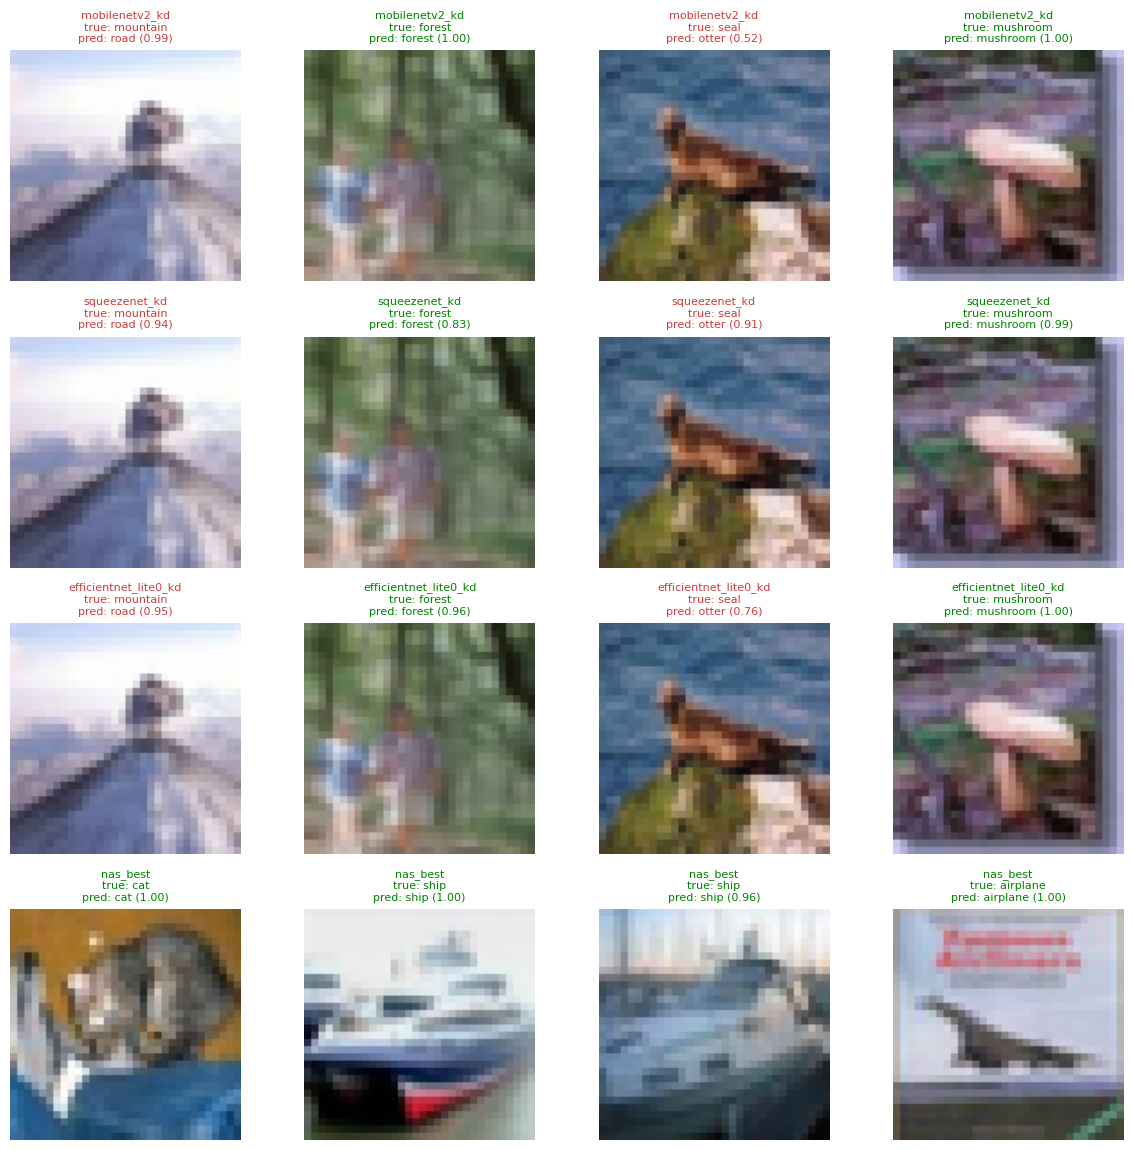

In [45]:
# Python API demo + figure for the report
import matplotlib.pyplot as plt, numpy as np
from PIL import Image
from src.deploy.inference import UnifiedClassifier
from src.deploy.registry import available_keys
keys = [k for k in available_keys() if k.endswith("_kd")] + ["nas_best"]
fig, axes = plt.subplots(len(keys), 4, figsize=(12, 2.9 * len(keys)))
for r, key in enumerate(keys):
    clf = UnifiedClassifier(key, backend="onnx")
    files = sorted(glob.glob(f"samples/{clf.dataset}_*.png"))[:4]
    for c, (f, pred) in enumerate(zip(files, clf.predict(files, topk=2))):
        ax = axes[r, c]
        ax.imshow(Image.open(f).resize((96, 96), Image.NEAREST)); ax.axis("off")
        truth = pathlib.Path(f).stem.split("_", 2)[-1]
        ax.set_title(f"{key}\ntrue: {truth}\npred: {pred[0][0]} ({pred[0][1]:.2f})", fontsize=8,
                     color="#008300" if pred[0][0] == truth else "#d03b3b")
plt.tight_layout(); plt.savefig("screenshots/demo_inference_predictions.png", dpi=110); plt.show()

## 9. Automated benchmarking (deliverable 11)
Parameters, size, FLOPs, PyTorch and ONNX Runtime accuracy, CPU latency (PyTorch vs ONNX Runtime), throughput and peak inference memory for the teacher, all six students and the NAS model.

In [46]:
bm = HP["benchmark"]
ARGS = f"--threads {bm['threads']} --runs {bm['runs']} {SMOKE_FLAG}"
!python -m src.deploy.benchmark $ARGS
display(pd.read_csv("results/benchmark_results.csv").round(3))
display(pd.read_csv("results/kd_comparison.csv").round(2))


===== benchmark | 2026-11-20 10:10:44 =====
USDT:2026-11-20 10:10:49 51522:51522 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-20 10:10:49 51522:51522 SyncActivityProfilerHandler.cpp:46] profiler_stop
[bench] resnet50_teacher             params=23.705M size=90.73MB MFLOPs=2596.0 top1=84.08 torch-cpu=58.00ms ort-cpu=nanms
USDT:2026-11-20 10:10:51 51522:51522 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-20 10:10:51 51522:51522 SyncActivityProfilerHandler.cpp:46] profiler_stop
[bench] mobilenetv2_baseline         params=2.352M size=9.20MB MFLOPs=176.2 top1=72.55 torch-cpu=9.61ms ort-cpu=2.88ms
USDT:2026-11-20 10:11:32 51522:51522 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-20 10:11:32 51522:51522 SyncActivityProfilerHandler.cpp:46] profiler_stop
[bench] squeezenet_baseline          params=0.777M size=3.03MB MFLOPs=48.5 top1=64.26 torch-cpu=5.10ms ort-cpu=0.64ms
USDT:2026-11-20 10:11:41 51522:51522 SyncActivityProfilerHandler.cpp:39

,key,model,variant,question,dataset,params_M,ckpt_size_mb,mflops,input_res,torch_top1,...,peak_gpu_mem_mb,cpu_threads,onnx_size_mb,onnx_cpu_top1,onnx_cpu_top5,onnx_eval_images,ort_cpu_latency_ms,ort_cpu_latency_p90_ms,ort_throughput_b64_img_s,ort_speedup_vs_torch
0,resnet50_teacher,ResNet-50,teacher,Q1,cifar100,23.705,90.727,2596.028,32,84.08,...,9.008,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,mobilenetv2_baseline,MobileNetV2,baseline,Q1,cifar100,2.352,9.200,176.183,32,72.55,...,3.563,1,8.953,72.55,93.12,10000.0,2.876,5.171,240.719,3.341
2,squeezenet_baseline,SqueezeNet,baseline,Q1,cifar100,0.777,3.033,48.497,32,64.26,...,1.905,1,2.965,64.23,89.20,10000.0,0.642,0.734,1982.997,7.942
3,efficientnet_lite0_baseline,EfficientNet-Lite0,baseline,Q1,cifar100,3.499,13.602,231.310,32,72.79,...,3.563,1,13.311,72.80,93.69,10000.0,3.245,4.361,304.526,3.153
4,mobilenetv2_kd,MobileNetV2,kd,Q1,cifar100,2.352,9.198,176.183,32,75.20,...,3.563,1,8.953,75.18,94.53,10000.0,2.778,4.298,248.840,3.426
5,squeezenet_kd,SqueezeNet,kd,Q1,cifar100,0.777,3.032,48.497,32,64.12,...,1.905,1,2.965,64.14,89.70,10000.0,0.600,0.661,1938.126,8.775
6,efficientnet_lite0_kd,EfficientNet-Lite0,kd,Q1,cifar100,3.499,13.601,231.310,32,75.49,...,3.563,1,13.311,75.50,94.53,10000.0,3.279,3.559,309.337,3.199
7,nas_best,NAS-best,nas,Q2,cifar10,0.227,0.934,83.387,24,92.30,...,2.479,1,0.871,92.29,99.80,10000.0,1.704,2.045,554.972,2.743


,student,params_M,baseline_top1,kd_top1,kd_gain_top1,baseline_top5,kd_top5,kd_gain_top5,teacher_top1,compression_ratio
0,MobileNetV2,2.35,72.55,75.20,2.65,93.13,94.55,1.42,84.08,10.08
1,SqueezeNet,0.78,64.26,64.12,-0.14,89.22,89.72,0.50,84.08,30.52
2,EfficientNet-Lite0,3.50,72.79,75.49,2.70,93.69,94.53,0.84,84.08,6.77


results/plots/cpu_latency_torch_vs_onnx.png


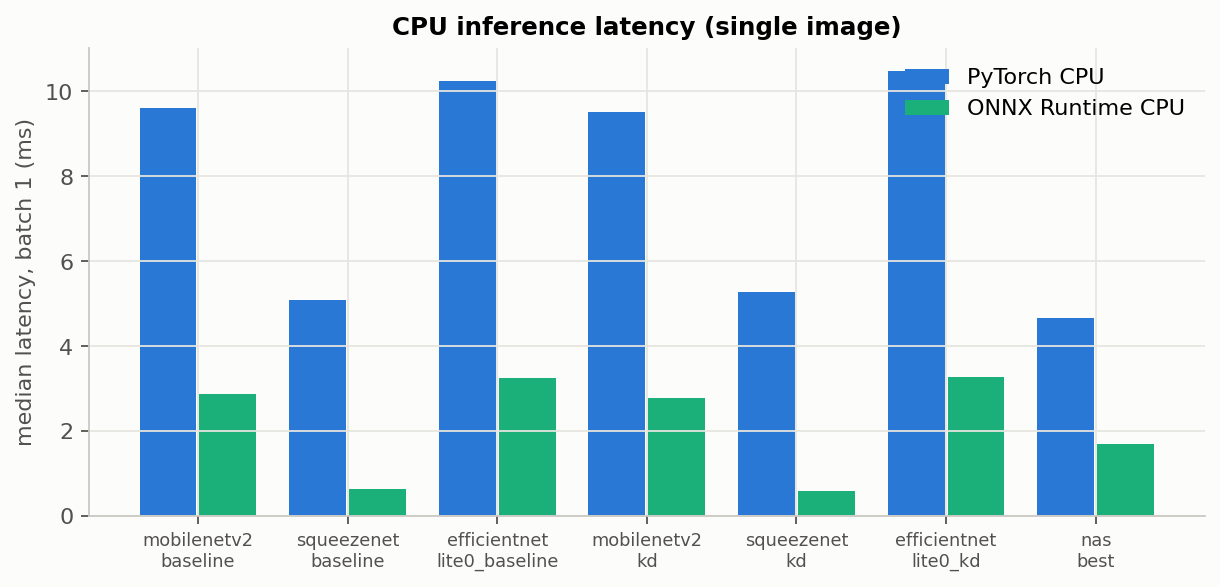

results/plots/q1_accuracy_vs_latency.png


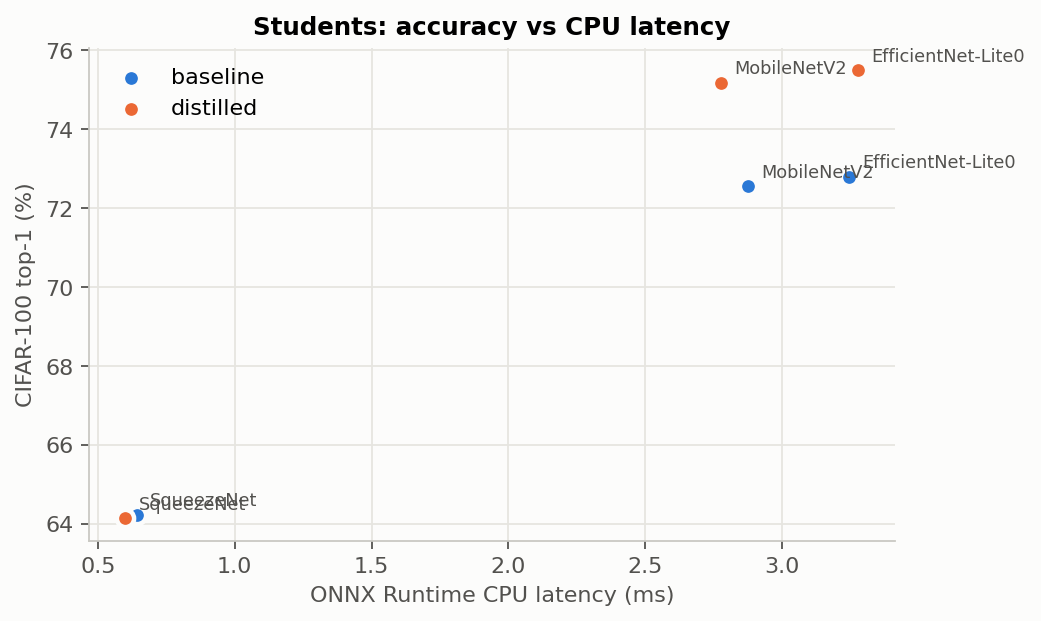

results/plots/q1_kd_vs_baseline.png


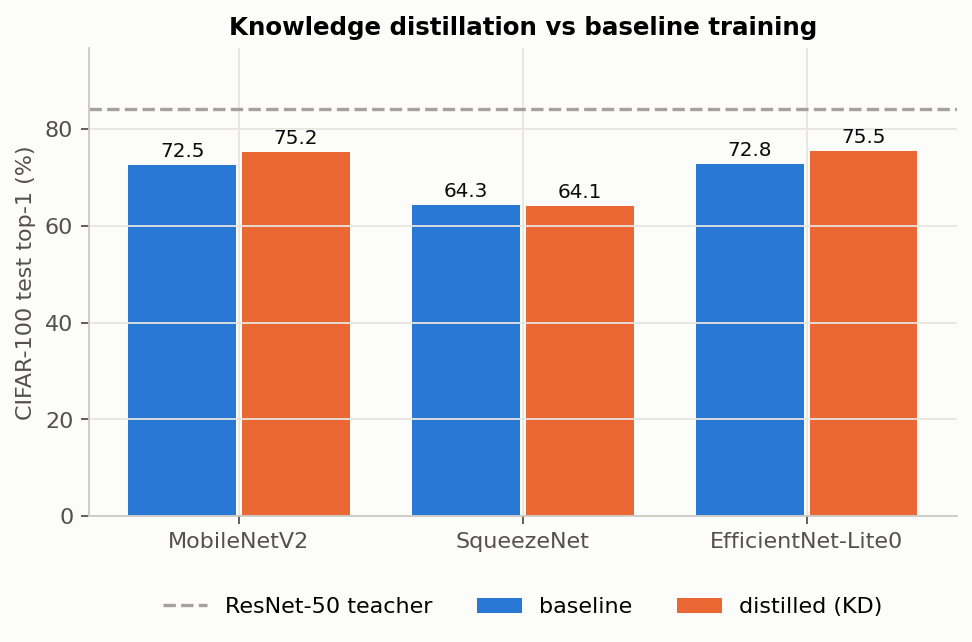

results/plots/q1_student_training_curves.png


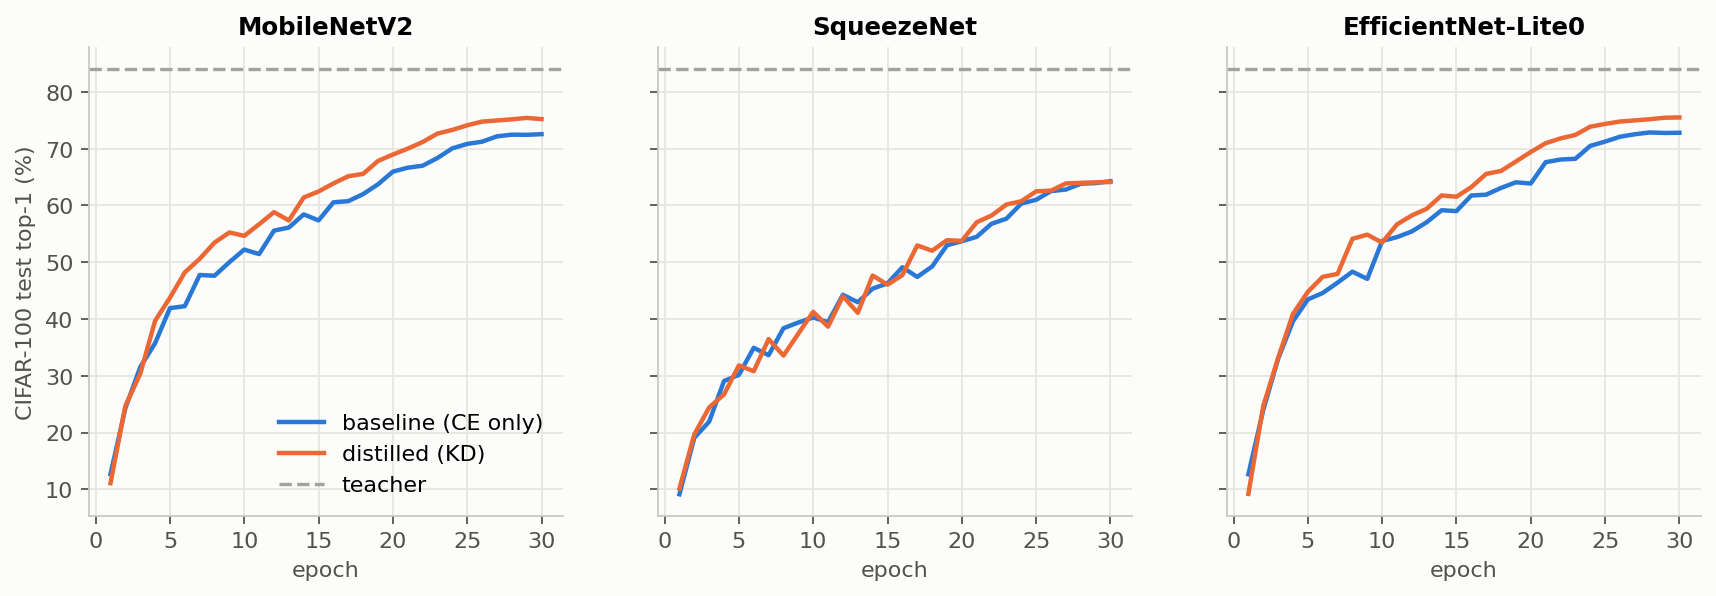

results/plots/q1_teacher_training.png


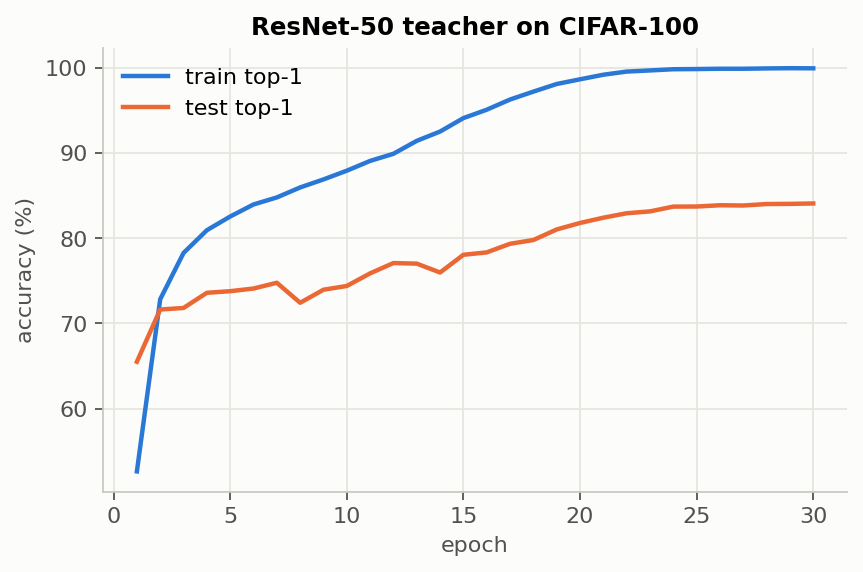

results/plots/q2_nas_accuracy_vs_latency.png


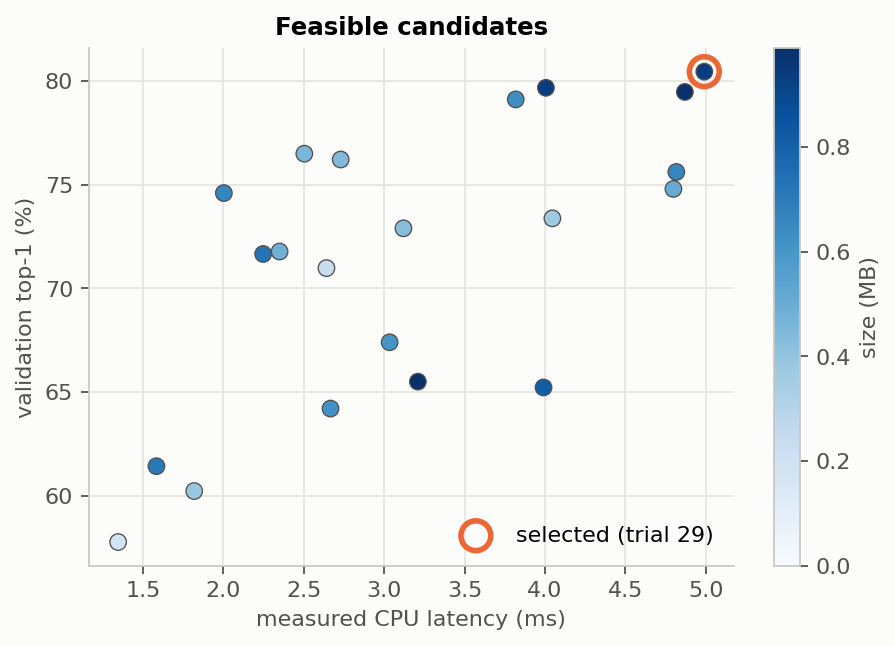

results/plots/q2_nas_best_training.png


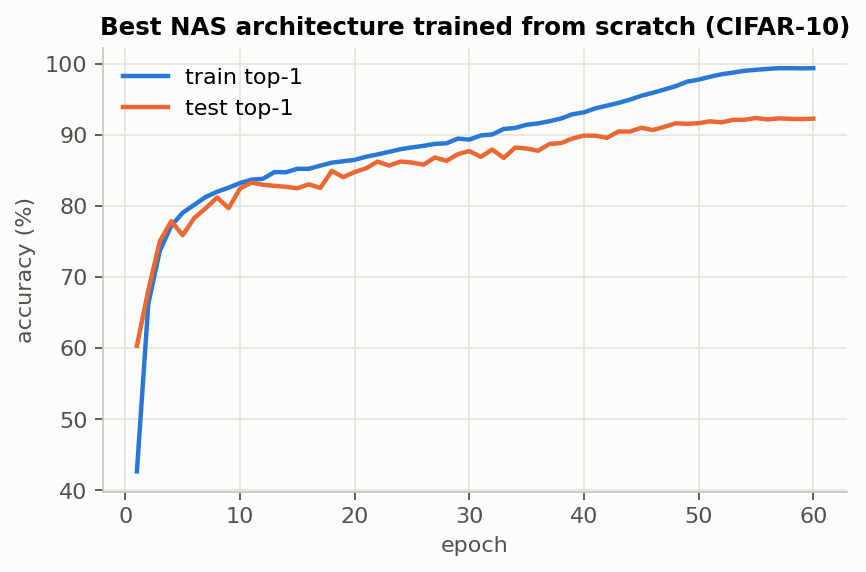

results/plots/q2_nas_constraints_scatter.png


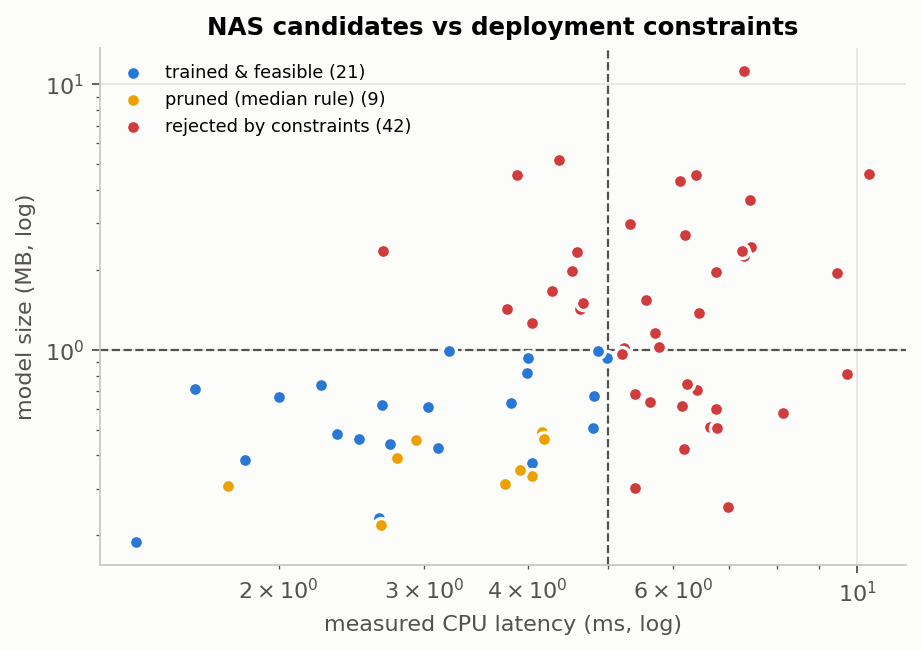

results/plots/q2_nas_history.png


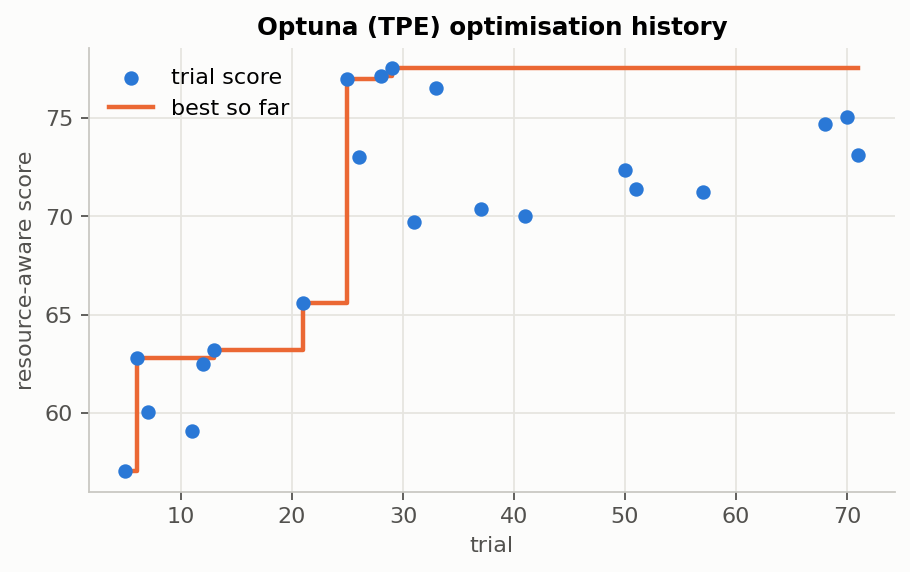

In [47]:
from IPython.display import Image as IPImage
for p in sorted(glob.glob("results/plots/*.png")):
    print(p); display(IPImage(p, width=760))

## 10. Technical report PDF (deliverable 12)
Generated from the actual results (tables, plots, and terminal-style screenshots of every stage's log). You can add your own Colab screenshots to `screenshots/` and re-run this cell — every PNG there is included.

In [48]:
!python -m src.report.make_report --roll $ROLL_NO --section $SECTION
REPORT = f"report/{ROLL_NO}_{SECTION}_Technical_Report.pdf"
print("report:", os.path.abspath(REPORT))

[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_01_q1_train_teacher.png
[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_02_q1_train_baseline.png
[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_03_q1_train_kd.png
[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_04_export_onnx.png
[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_05_onnx_cpu_inference.png
[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_06_unified_inference.png
[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_07_q2_nas_search.png
[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_08_q2_train_best.png
[screenshots] /content/drive/MyDrive/22i-1948_A/screenshots/log_09_benchmark.png
[report] wrote /content/drive/MyDrive/22i-1948_A/report/22i-1948_A_Technical_Report.pdf
report: /content/drive/MyDrive/22i-1948_A/report/22i-1948_A_Technical_Report.pdf


## 11. Package the repository as `22i-1948_<SECTION>.zip`
The notebook itself is saved into `notebooks/`. Resume-only files (`*_last.pt`) and caches are excluded.

In [49]:
import zipfile, shutil
if IN_COLAB:
    try:  # save a copy of this notebook (with outputs) into the repository
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
        json.dump(nb, open(f"notebooks/{ROLL_NO}_{SECTION}.ipynb", "w"))
        print("notebook saved to notebooks/")
    except Exception as ex:
        print("could not save the notebook automatically - File > Download .ipynb and put it in notebooks/:", ex)

ZIP_NAME = f"{ROLL_NO}_{SECTION}"
zip_path = os.path.join(BASE, f"{ZIP_NAME}.zip")
skip = lambda p: (p.endswith("_last.pt") or p.endswith(".tmp") or "__pycache__" in p or "/.git/" in p
                  or p.endswith(".zip") or "/.ipynb_checkpoints/" in p)
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(PROJECT_ROOT):
        for f in files:
            full = os.path.join(root, f)
            if not skip(full):
                z.write(full, os.path.join(ZIP_NAME, os.path.relpath(full, PROJECT_ROOT)))
print(f"{zip_path}  ({os.path.getsize(zip_path) / 2**20:.1f} MB)")
with zipfile.ZipFile(zip_path) as z:
    names = z.namelist()
print(len(names), "files, e.g.:")
for n_ in sorted(names):
    if n_.endswith((".pt", ".onnx", ".pdf", ".csv", ".json", ".md")):
        print("  ", n_)
if IN_COLAB:
    local = f"/content/{ZIP_NAME}.zip"
    if zip_path != local:
        shutil.copy(zip_path, local)
    from google.colab import files
    files.download(local)

notebook saved to notebooks/
/content/drive/MyDrive/22i-1948_A.zip  (185.4 MB)
120 files, e.g.:
   22i-1948_A/README.md
   22i-1948_A/checkpoints/q1/baseline/efficientnet_lite0_baseline.pt
   22i-1948_A/checkpoints/q1/baseline/mobilenetv2_baseline.pt
   22i-1948_A/checkpoints/q1/baseline/squeezenet_baseline.pt
   22i-1948_A/checkpoints/q1/kd/efficientnet_lite0_kd.pt
   22i-1948_A/checkpoints/q1/kd/mobilenetv2_kd.pt
   22i-1948_A/checkpoints/q1/kd/squeezenet_kd.pt
   22i-1948_A/checkpoints/q1/teacher/resnet50_teacher.pt
   22i-1948_A/checkpoints/q2/nas_best.pt
   22i-1948_A/onnx_models/efficientnet_lite0_baseline.onnx
   22i-1948_A/onnx_models/efficientnet_lite0_kd.onnx
   22i-1948_A/onnx_models/mobilenetv2_baseline.onnx
   22i-1948_A/onnx_models/mobilenetv2_kd.onnx
   22i-1948_A/onnx_models/nas_best.onnx
   22i-1948_A/onnx_models/squeezenet_baseline.onnx
   22i-1948_A/onnx_models/squeezenet_kd.onnx
   22i-1948_A/report/22i-1948_A_Technical_Report.pdf
   22i-1948_A/results/benchmark_res

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. (Optional) Push to GitHub
```bash
cd /content/drive/MyDrive/22i-1948_<SECTION>      # the project folder
git init && git lfs install
git lfs track "*.pt" "*.onnx" && git add .gitattributes
printf "data/\n*_last.pt\n__pycache__/\n" > .gitignore
git add . && git commit -m "KD + hardware-aware NAS: code, checkpoints, results, report"
git branch -M main
git remote add origin https://github.com/<your-user>/22i-1948_<SECTION>.git
git push -u origin main     # use a personal access token as the password
```